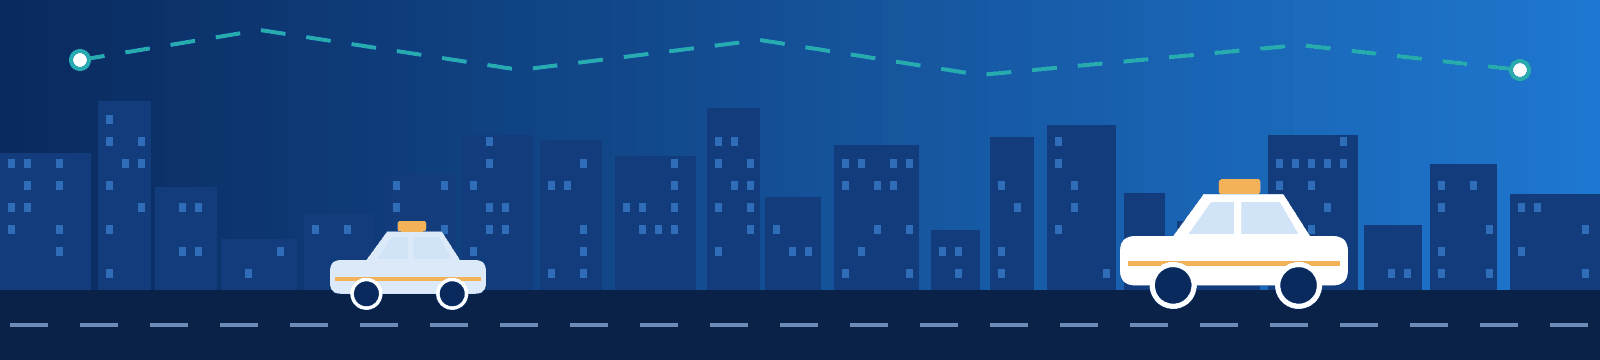

# <span style="color:#1D6FD8">Blue Bird: Krisis Ritase &amp; Kesenjangan Armada</span>

**Capstone Project Data Analytics: produktivitas armada taksi dan kontrol eVoucher korporat**

| | |
|---|---|
| **Studi kasus** | Blue Bird, operator taksi konvensional di Indonesia |
| **Cakupan data** | Oktober–Desember 2023, enam tabel operasional (trip, request, shift, pengemudi, pool, klien korporat) |
| **Dua fokus** | Optimalisasi armada (ritase dan idle time) dan mitigasi risiko B2B (pemakaian eVoucher) |

<sub>Ilustrasi sampul dibuat sendiri sebagai elemen visual dan tidak menggambarkan data maupun armada sebenarnya. Tidak ada logo atau aset resmi Blue Bird yang dipakai.</sub>

# <span style="color:#1D6FD8">Ringkasan Eksekutif</span>

<p style="line-height:1.6;">
Notebook ini menjawab satu pertanyaan besar: <strong>mengapa pengemudi Blue Bird banyak menganggur sementara sebagian pelanggan tidak mendapat taksi?</strong> Analisis memakai data Oktober–Desember 2023 yang lebih dulu dibersihkan, lalu dieksplorasi, diuji secara statistik, dan divisualisasikan. Setiap angka di bawah berasal dari sel analisis di bagian terkait.
</p>

| Temuan utama | Angka kunci | Dibahas di |
|---|---|---|
| Request gagal terpusat di CBD pada jam sibuk | CBD pukul 07–08 dan 17–18 gagal 36,6%, dibanding 6,70% untuk seluruh request (19.397 dari 289.622) | 2.4, 3.4.1–3.4.3 |
| Pengemudi sangat idle | 1,26 trip per shift, 30,6% shift tanpa trip, utilisasi 9,4% | 2.5.8, 2.5.10, 3.5.1 |
| Penyebab idle terkuat adalah tempat kerja, bukan pool | Zona menjelaskan 9,7% variasi trip per shift; setelah zona dikendalikan, pool tidak menambah apa pun (p = 0,62) | 2.7.3, 3.5.2, 3.5.5 |
| Ritase rendah, tetapi tidak terbukti menurun | Tidak ada tren selama 12 minggu penuh | 2.5.7, 3.4.5 |
| Pola eVoucher perlu diverifikasi | Trip eVoucher Airport: 65,9% pada malam atau akhir pekan, vs 22,6% pada trip Non-B2B | 2.6.5, 3.5.10 |


<div style="border-left:5px solid #E8A317; background:#FFF6E0; color:#3B2A00; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Cara membaca temuan.</strong> Semua temuan bersifat <strong>asosiatif</strong> (data observasional tiga bulan). Pola eVoucher adalah sinyal untuk diverifikasi, bukan bukti penyalahgunaan. Rekomendasi pada bagian Penutup berupa usulan uji coba dan verifikasi, bukan kesimpulan sebab-akibat.
</div>

## <span style="color:#1D6FD8">Alur Analisis</span>

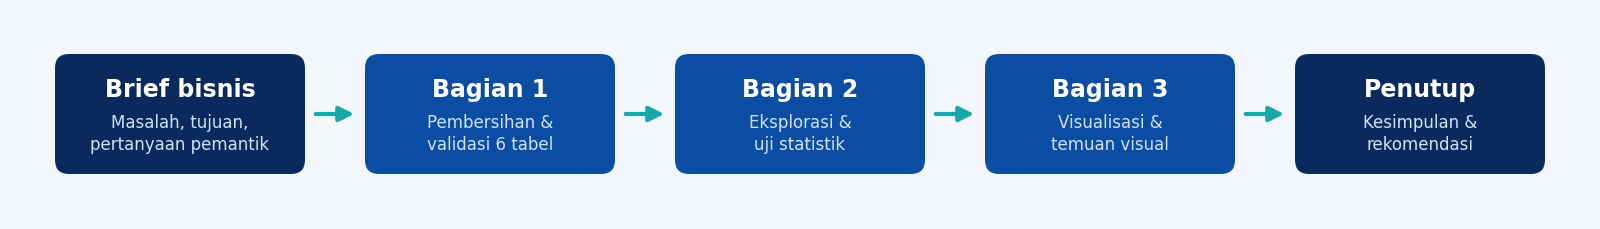

| Tahap | Pertanyaan yang dijawab | Hasil |
|---|---|---|
| Bagian 1: Pembersihan Data | Apakah data cukup andal untuk dianalisis? | Tabel final bersih, file exception, dan laporan kualitas |
| Bagian 2: Eksplorasi Data | Apa yang terjadi pada request, shift, dan eVoucher, dan apakah polanya signifikan? | Temuan teramati, hipotesis, dan tabel uji statistik |
| Bagian 3: Visualisasi | Bagaimana temuan terbaik disampaikan secara visual? | Grafik per pertanyaan bisnis dan jawaban atas penyebab idle |
| Penutup | Apa implikasinya bagi manajemen? | Kesimpulan, rekomendasi, dan keterbatasan |

# <span style="color:#1D6FD8">Business Understanding</span>

## <span style="color:#1D6FD8">Latar Belakang</span>

<p style="line-height:1.6;">
Blue Bird adalah pelopor taksi konvensional dengan armada fisik dan pengemudi tetap, bukan platform <em>ride-hailing</em> murni. Kendaraan dan pengemudi merupakan <strong>biaya tetap</strong>, sehingga setiap jam bertugas tanpa penumpang adalah biaya tanpa pendapatan. Itulah sebabnya utilisasi armada menjadi metrik acuan manajemen. Brief menyebut target sekitar 70% pada 2018, tetapi angka itu hanya konteks historis dan tidak dijadikan pembanding dalam analisis ini. Seiring ekspansi kompetitor berbasis aplikasi, prioritas bergeser dari <em>menambah</em> armada menjadi <em>memaksimalkan produktivitas</em> armada yang sudah ada, termasuk ritase dan idle time pengemudi di setiap garasi (pool).
</p>

<p style="line-height:1.6;">
Blue Bird juga melayani segmen B2B lewat <em>Corporate Solution</em>, dengan pembayaran non-tunai <strong>eVoucher</strong> untuk perjalanan dinas karyawan klien. Tim Finance di beberapa klien mempertanyakan transparansi pemakaiannya, sehingga kewajarannya perlu dikaji. Dari sisi data, tim Data Engineering mencatat inkonsistensi akibat rekonsiliasi antara sistem aplikasi dan sistem dispatch lama (log argometer dan kategori layanan). Karena itu kualitas data harus dipastikan lebih dulu di Bagian 1.
</p>

## <span style="color:#1D6FD8">Pernyataan Masalah &amp; Tujuan</span>

<p style="line-height:1.6;">
Brief merumuskan masalah utama: produktivitas armada (ritase) <em>diduga</em> menurun terkait idle time pengemudi, dan ada indikasi masalah kontrol pada eVoucher korporat. Tiga indikasi berikut <strong>besarnya masih harus dikonfirmasi</strong> melalui data:
</p>

| # | Indikasi dalam brief | Dikaji di |
|---|---|---|
| 1 | **Ritase dan idle time.** Ritase (trip per pengemudi per hari) bervariasi antar pool dan diduga berkaitan dengan idle time. | 2.5 dan 2.7 |
| 2 | **Permintaan tidak terpenuhi.** Request pelanggan tidak selalu terlayani pada waktu atau lokasi tertentu (dibatalkan karena tidak ada pengemudi atau <em>timeout</em>). | 2.4 |
| 3 | **Pemakaian eVoucher.** Trip eVoucher korporat diduga terjadi pada waktu yang tidak lazim untuk perjalanan dinas. | 2.6 |

<p style="line-height:1.6;">
<strong>Tujuan analisis</strong> ada dua. Pertama, <strong>Fleet Optimization</strong>: memahami produktivitas dan idle time antar pool untuk mendukung strategi penempatan dan dispatch pengemudi. Kedua, <strong>B2B Fraud Mitigation</strong>: memahami pola eVoucher agar kontrol dan transparansi pelaporan ke klien B2B bisa diperkuat. Keandalan data argometer dan standardisasi kategori layanan menjadi prasyarat kedua tujuan tersebut, sehingga dikerjakan terlebih dahulu. Brief meminta baseline, besaran gap, dan target terukur dirumuskan sendiri dari data (lihat Rekomendasi).
</p>

<p style="line-height:1.6;">
Data mencakup Oktober–Desember 2023 dari enam tabel: <code>bb_trips</code>, <code>bb_service_requests</code>, <code>bb_driver_shifts</code>, <code>bb_drivers</code>, <code>bb_pools</code>, dan <code>bb_corporate_clients</code>.
</p>

### <span style="color:#1D6FD8">Pemetaan Brief ke Notebook</span>

<p style="line-height:1.6;">
Dua tabel berikut menunjukkan di bagian mana setiap catatan kualitas data dan setiap pertanyaan pemantik dalam brief ditangani.
</p>

| Catatan kualitas data (brief) | Penanganan | Bagian |
|---|---|---|
| Kolom identitas (mis. `company_id`) kosong adalah hal wajar | Diperlakukan sebagai null struktural (pelanggan non-korporat) dan tidak diisi paksa | 1.7.3 |
| Kategori layanan belum seragam (aplikasi vs dispatch lama) | Dipetakan ke `service_type_clean`, label asli disimpan, lalu divalidasi dengan tipe kendaraan pengemudi | 1.4.2, 1.4.3 |
| Human error atau sensor pada waktu dan jarak argometer | Jarak negatif dan delay booking-ke-meter negatif ditandai; trip terkait dikeluarkan dan dicatat di file exception | 1.5, 1.7.4, 1.8 |
| Nilai ekstrem belum tentu salah | IQR per zona dan tipe trip (Charter tidak dibuang otomatis); hanya jarak yang tidak masuk akal yang ditinjau | 1.6 |
| Konsistensi antar tabel | PK, FK, shift, dan request divalidasi sebelum tabel digabung | 1.7 |

| Pertanyaan pemantik (brief) | Dijawab di |
|---|---|
| Pola ritase antar pool dan faktor penjelasnya | 2.5.4–2.5.5, 2.7, 3.5.1–3.5.2, 3.6.3 |
| Pola waktu dan lokasi request yang tidak terpenuhi | 2.4, 3.4.1–3.4.3 |
| Dampak kualitas data argometer dan cara penanganannya | 1.8.4, 2.3.1, 3.3.1 |
| Pola metode pembayaran, termasuk eVoucher | 2.6, 3.2.2, 3.5.7–3.5.11 |
| Keputusan bagi manajer operasional dan tim Finance | Rekomendasi (dipisah menurut peran) |

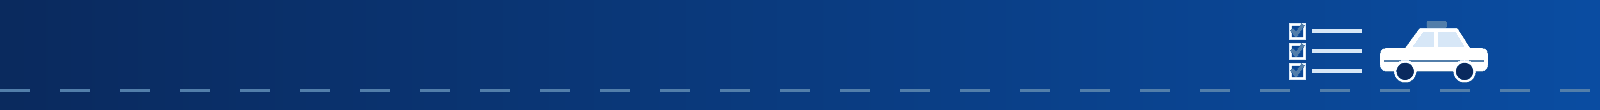

# <span style="color:#1D6FD8">Bagian 1: Pembersihan dan Validasi Data</span>

<p style="line-height:1.6;">
Setiap tabel dibersihkan satu per satu sebelum dianalisis. Prinsipnya: data asli tidak diubah, masalah ditandai lewat kolom <code>flag_*</code>, dan versi aman dari suatu nilai disimpan di kolom <code>*_clean</code>. Baris trip hanya dikeluarkan jika melanggar aturan yang sudah dikonfirmasi (jarak negatif atau delay booking-ke-meter negatif). Selebihnya tidak ada baris yang dihapus.
</p>

## <span style="color:#1D6FD8">1.1 Ruang Lingkup Proyek dan Sumber Data</span>

<p style="line-height:1.6;">
Data harus dipastikan andal sebelum dianalisis. Keenam tabel sumber dibersihkan satu per satu sebelum digabung, karena setiap tabel punya aturan dan key sendiri, dan penggabungan yang tergesa-gesa dapat menggandakan baris.
</p>

**Relasi antar tabel**

| Tabel induk (key) | Tabel anak (foreign key) |
|---|---|
| `bb_pools.pool_id` | `bb_drivers.pool_id` |
| `bb_drivers.driver_id` | `bb_driver_shifts.driver_id`, `bb_trips.driver_id` |
| `bb_driver_shifts.shift_id` | `bb_trips.shift_id` |
| `bb_corporate_clients.company_id` | `bb_trips.company_id` |
| `bb_trips.trip_id` | `bb_service_requests.matched_trip_id` |

**Isi setiap tabel**

| Tabel | Isi | Primary key |
|---|---|---|
| `bb_trips` | Trip yang selesai: waktu, jarak, tarif, layanan, pembayaran | `trip_id` |
| `bb_service_requests` | Request pelanggan dan statusnya (terpenuhi atau dibatalkan) | `request_id` |
| `bb_driver_shifts` | Shift pengemudi: clock-in/out, jumlah trip, idle time | `shift_id` |
| `bb_drivers` | Atribut pengemudi | `driver_id` |
| `bb_pools` | Pool (garasi): wilayah dan afinitas zona | `pool_id` |
| `bb_corporate_clients` | Klien korporat dan industrinya | `company_id` |

### <span style="color:#1D6FD8">1.1.1 Import Library dan Folder Output</span>

<p style="line-height:1.6;">
Sel berikut menyiapkan library dan folder output. Kredensial database dibaca dari environment variable (<code>USER</code>, <code>PASS</code>, <code>DATABASE</code>), dari file <code>.env</code> lokal, dan tidak ditulis di notebook. Bagian eksplorasi juga memerlukan <code>scipy</code> dan <code>statsmodels</code>.
</p>

In [88]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import pymysql
from dotenv import load_dotenv
from IPython.display import display

load_dotenv()

output_dir = Path("databasegpt")
output_dir.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

print(f"Output folder: {output_dir.resolve()}")

Output folder: C:\Users\Demas\Desktop\atz-priv\Bootcamp\M2\capstone\claude pro\gptdata\databasegpt


## <span style="color:#1D6FD8">1.2 Load dan Inspeksi Data</span>

<p style="line-height:1.6;">
Pertanyaan pertama: apakah keenam tabel termuat lengkap, dan seperti apa bentuknya? Tabel dimuat dari database dan disalin sebagai data asli (<code>*_raw</code>), lalu jumlah baris, kolom, dan tipe datanya diperiksa.
</p>

### <span style="color:#1D6FD8">1.2.1 Load Enam Tabel Sumber</span>

<p style="line-height:1.6;">
Keenam tabel dimuat dari database. Kredensial diambil dari environment variable, bukan ditulis langsung di notebook.
</p>

In [89]:
# Credentials should be stored in environment variables or a local .env file.
# Do not hard-code database passwords in the notebook.
required_env = ["USER", "PASS", "DATABASE"]
missing_env = [name for name in required_env if not os.getenv(name)]
if missing_env:
    raise EnvironmentError(
        "Missing environment variables: " + ", ".join(missing_env)
    )

conn = pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user=os.getenv("USER"),
    password=os.getenv("PASS"),
    database=os.getenv("DATABASE")
)

try:
    df_clients_raw = pd.read_sql_query(
        "SELECT * FROM bb_corporate_clients", conn
    )
    df_trips_raw = pd.read_sql_query(
        "SELECT * FROM bb_trips", conn
    )
    df_shifts_raw = pd.read_sql_query(
        "SELECT * FROM bb_driver_shifts", conn
    )
    df_drivers_raw = pd.read_sql_query(
        "SELECT * FROM bb_drivers", conn
    )
    df_pools_raw = pd.read_sql_query(
        "SELECT * FROM bb_pools", conn
    )
    df_requests_raw = pd.read_sql_query(
        "SELECT * FROM bb_service_requests", conn
    )
finally:
    conn.close()

print("Loaded all six source tables.")

C:\Users\Demas\AppData\Local\Temp\ipykernel_28600\519043760.py:18: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_clients_raw = pd.read_sql_query(
C:\Users\Demas\AppData\Local\Temp\ipykernel_28600\519043760.py:21: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_trips_raw = pd.read_sql_query(
C:\Users\Demas\AppData\Local\Temp\ipykernel_28600\519043760.py:24: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_shifts_raw = pd.read_sql_query(
C:\Users\Demas\AppData\Local\Temp\ipykernel_28600\519043760.py:27: UserWarning: panda

Loaded all six source tables.


### <span style="color:#1D6FD8">1.2.2 Salinan Kerja dan Profil Tabel</span>

<p style="line-height:1.6;">
Tabel asli (<code>*_raw</code>) disimpan tanpa perubahan sebagai cadangan. Pembersihan dilakukan pada salinan kerja, kemudian jumlah baris, kolom, dan tipe datanya ditinjau.
</p>

In [90]:
# Raw DataFrames are retained unchanged as a source backup in memory.
df_clients = df_clients_raw.copy()
df_trips = df_trips_raw.copy()
df_shifts = df_shifts_raw.copy()
df_drivers = df_drivers_raw.copy()
df_pools = df_pools_raw.copy()
df_requests = df_requests_raw.copy()

def make_tables():
    return {
        "clients": df_clients,
        "trips": df_trips,
        "shifts": df_shifts,
        "drivers": df_drivers,
        "pools": df_pools,
        "requests": df_requests,
    }

tables = make_tables()

profile_rows = []
for table_name, df in tables.items():
    profile_rows.append({
        "table": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "exact_duplicate_rows": int(df.duplicated().sum()),
    })

display(pd.DataFrame(profile_rows))
# Fingerprint of every raw table right after loading (a number that changes if ANY value changes).
# Bagian 4 recomputes it to prove the raw exports are the untouched source data.
raw_fingerprints = {
    name: int(pd.util.hash_pandas_object(df, index=True).sum())
    for name, df in {
        "bb_corporate_clients": df_clients_raw, "bb_trips": df_trips_raw, "bb_driver_shifts": df_shifts_raw,
        "bb_drivers": df_drivers_raw, "bb_pools": df_pools_raw, "bb_service_requests": df_requests_raw,
    }.items()
}


,table,rows,columns,exact_duplicate_rows
0,clients,286,3,0
1,trips,318098,14,0
2,shifts,252524,9,0
3,drivers,4055,6,0
4,pools,8,6,0
5,requests,289622,7,0


In [91]:
# Review each table's column names and data types.
for table_name, df in tables.items():
    print(f"\n{table_name.upper()} — first 3 rows")
    display(df.head(3))
    display(df.dtypes.rename("data_type").to_frame())


CLIENTS — first 3 rows


,company_id,company_name,industry
0,CORP-BNK-001,PT. Global Banking 62 Tbk,Banking
1,CORP-BNK-002,PT. Global Banking 104 Tbk,Banking
2,CORP-BNK-003,PT. Mandiri Banking 317 Tbk,Banking


,data_type
company_id,str
company_name,str
industry,str



TRIPS — first 3 rows


,trip_id,driver_id,shift_id,company_id,trip_type,service_type,pickup_zone_type,booking_channel,booking_time,meter_start_time,dropoff_time,distance_km,payment_method,total_fare
0,TRP-231001-0001,DRV-KLG-21-0041,SFT-KLG-2310-240939,NaN,Reguler,Bluebird,Residential,App,2023-10-01 05:12:14,2023-10-01 05:18:59,2023-10-01 05:37:21,7.00,MyBluebird App,"46,500.00"
1,TRP-231001-0002,DRV-KLG-23-0004,SFT-KLG-2310-222052,NaN,Reguler,Bluebird,CBD,App,2023-10-01 05:16:53,2023-10-01 05:22:28,2023-10-01 05:35:09,2.90,MyBluebird App,"26,500.00"
2,TRP-231001-0003,DRV-HLM-18-0022,SFT-HLM-2310-152040,NaN,Reguler,Bluebird,CBD,App,2023-10-01 05:18:35,2023-10-01 05:25:14,2023-10-01 05:42:43,3.40,MyBluebird App,"29,000.00"


...

,pool_id,pool_name,region_area,distance_to_soetta_km,distance_to_cbd_km,primary_zone_affinity
0,PL-BSD,Pool BSD,Tangerang Selatan,32.00,26.00,Mixed
1,PL-CGK,Pool Bandara Soetta,Tangerang,3.50,28.00,Airport-heavy
2,PL-CPT,Pool Ciputat,Tangerang Selatan,35.00,18.00,Mixed


,data_type
pool_id,str
pool_name,str
region_area,str
distance_to_soetta_km,float64
distance_to_cbd_km,float64
primary_zone_affinity,str



REQUESTS — first 3 rows


,request_id,requested_time,pickup_zone_type,request_source,status,matched_trip_id,wait_time_minutes
0,REQ-231001-00001,2023-10-01 05:12:14,Residential,App,Fulfilled,TRP-231001-0001,6.80
1,REQ-231001-00002,2023-10-01 05:16:53,CBD,App,Fulfilled,TRP-231001-0002,5.60
2,REQ-231001-00003,2023-10-01 05:18:35,CBD,App,Fulfilled,TRP-231001-0003,6.60


,data_type
request_id,str
requested_time,datetime64[us]
pickup_zone_type,str
request_source,str
status,str
matched_trip_id,str
wait_time_minutes,float64


## <span style="color:#1D6FD8">1.3 Penilaian Awal Kualitas Data</span>

<p style="line-height:1.6;">
Sebelum ada nilai yang diubah, perlu diketahui seberapa banyak nilai kosong yang ada. Laporan ini menjadi garis dasar untuk dibandingkan dengan hasil akhir.
</p>

### <span style="color:#1D6FD8">1.3.1 Laporan Missing Value Awal</span>

<p style="line-height:1.6;">
Jumlah nilai kosong dihitung per kolom sebagai titik awal sebelum pembersihan.
</p>

In [92]:
def missing_summary(df):
    return pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percentage": (df.isna().mean() * 100).round(2),
    }).sort_values("missing_percentage", ascending=False)

for table_name, df in tables.items():
    print(f"\nMISSING VALUES: {table_name.upper()}")
    display(missing_summary(df))


MISSING VALUES: CLIENTS


,missing_count,missing_percentage
company_id,0,0.00
company_name,0,0.00
industry,0,0.00



MISSING VALUES: TRIPS


,missing_count,missing_percentage
company_id,260740,81.97
trip_id,0,0.00
driver_id,0,0.00
shift_id,0,0.00
trip_type,0,0.00
service_type,0,0.00
pickup_zone_type,0,0.00
booking_channel,0,0.00
booking_time,0,0.00
meter_start_time,0,0.00



MISSING VALUES: SHIFTS


...

,missing_count,missing_percentage
driver_id,0,0.00
pool_id,0,0.00
driver_rating,0,0.00
join_date,0,0.00
employment_status,0,0.00
vehicle_type_assigned,0,0.00



MISSING VALUES: POOLS


,missing_count,missing_percentage
pool_id,0,0.00
pool_name,0,0.00
region_area,0,0.00
distance_to_soetta_km,0,0.00
distance_to_cbd_km,0,0.00
primary_zone_affinity,0,0.00



MISSING VALUES: REQUESTS


,missing_count,missing_percentage
wait_time_minutes,19397,6.70
matched_trip_id,19397,6.70
request_id,0,0.00
pickup_zone_type,0,0.00
requested_time,0,0.00
status,0,0.00
request_source,0,0.00


## <span style="color:#1D6FD8">1.4 Standarisasi Kategori dan Konversi Tipe Data</span>

<p style="line-height:1.6;">
Label dan tipe data yang tidak konsisten membuat validasi berikutnya menyesatkan. Misalnya, urutan waktu tidak bisa dicek selama kolomnya masih berupa teks. Karena itu teks dirapikan, layanan dipetakan, dan tipe data dikonversi lebih dulu, dengan label asli selalu dipertahankan.
</p>

### <span style="color:#1D6FD8">1.4.1 Merapikan Format Teks</span>

<p style="line-height:1.6;">
Spasi berlebih dan perbedaan huruf besar-kecil dirapikan agar label yang sama tidak terhitung sebagai kategori berbeda.
</p>

In [93]:
def clean_text_columns(df):
    df = df.copy()
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )
        df[col] = df[col].replace("", pd.NA)
    return df

df_clients = clean_text_columns(df_clients)
df_trips = clean_text_columns(df_trips)
df_shifts = clean_text_columns(df_shifts)
df_drivers = clean_text_columns(df_drivers)
df_pools = clean_text_columns(df_pools)
df_requests = clean_text_columns(df_requests)

tables = make_tables()
print("Trimmed surrounding whitespace and converted empty strings to missing values.")

Trimmed surrounding whitespace and converted empty strings to missing values.


### <span style="color:#1D6FD8">1.4.2 Standarisasi Kategori Layanan</span>

<p style="line-height:1.6;">
Label <code>service_type</code> yang tidak seragam dipetakan ke tiga kategori: <code>Bluebird</code>, <code>Silverbird</code>, dan <code>E-Cabbie</code>. Label aslinya disimpan di <code>service_type_original</code>.
</p>

In [94]:
# Keep the original label for traceability.
df_trips["service_type_original"] = df_trips["service_type"]

service_normalized = (
    df_trips["service_type"]
    .astype("string")
    .str.strip()
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
)

# Confirmed mappings from the project rules and known variants in the data.
service_mapping = {
    "bluebird": "Bluebird",
    "blue bird": "Bluebird",
    "bb reguler": "Bluebird",
    "reguler": "Bluebird",
    "silverbird": "Silverbird",
    "silver bird": "Silverbird",
    "silver": "Silverbird",
    "goldenbird": "Goldenbird",
    "golden bird": "Goldenbird",
    "golden": "Goldenbird",
    "e-cabbie": "E-Cabbie",
    "e cabbie": "E-Cabbie",
    "ecabbie": "E-Cabbie",
    "listrik": "E-Cabbie",
    "electric": "E-Cabbie",
}

df_trips["service_type_clean"] = service_normalized.map(service_mapping)

unmapped_service_types = (
    df_trips.loc[
        service_normalized.notna() & df_trips["service_type_clean"].isna(),
        "service_type_original",
    ]
    .value_counts(dropna=False)
)

print("Unmapped service categories (review these before finalizing):")
display(unmapped_service_types)
print("Standardized service categories:")
display(df_trips["service_type_clean"].value_counts(dropna=False))

Unmapped service categories (review these before finalizing):


Series([], Name: count, dtype: int64)

Standardized service categories:


service_type_clean
Bluebird      197983
Silverbird     65589
E-Cabbie       31914
Goldenbird     22612
Name: count, dtype: int64

### <span style="color:#1D6FD8">1.4.3 Validasi Pemetaan Layanan</span>

<p style="line-height:1.6;">
Pemetaan diuji terhadap <code>vehicle_type_assigned</code> pada tabel pengemudi. Jika jumlah pasangan yang tidak cocok adalah 0, pemetaan dinyatakan terkonfirmasi.
</p>

In [95]:
trip_vehicle_check = df_trips[["driver_id", "service_type_clean"]].merge(
    df_drivers[["driver_id", "vehicle_type_assigned"]], on="driver_id", how="left"
)
assert len(trip_vehicle_check) == len(df_trips), "merge changed the number of rows"

display(pd.crosstab(trip_vehicle_check["service_type_clean"], trip_vehicle_check["vehicle_type_assigned"]))

# Expected pairs: the Reguler vehicle runs the Bluebird service, and so on.
expected_pairs = {
    "Bluebird": "Reguler",
    "Silverbird": "Silver",
    "Goldenbird": "Golden",
    "E-Cabbie": "Electric",
}
wrong_pairs = (
    trip_vehicle_check["service_type_clean"].map(expected_pairs)
    != trip_vehicle_check["vehicle_type_assigned"]
).sum()
print(f"Trips where service_type_clean does not match the driver's vehicle type: {wrong_pairs}")

vehicle_type_assigned,Electric,Golden,Reguler,Silver
service_type_clean,,,,
Bluebird,0,0,197983,0
E-Cabbie,31914,0,0,0
Goldenbird,0,22612,0,0
Silverbird,0,0,0,65589


Trips where service_type_clean does not match the driver's vehicle type: 0


### <span style="color:#1D6FD8">1.4.4 Cek Kolom Kategori Lain</span>

<p style="line-height:1.6;">
Nilai unik pada kolom kategori lainnya dicetak untuk memastikan tidak ada variasi ejaan yang perlu dipetakan.
</p>

In [96]:
category_columns = {
    "clients": (df_clients, ["industry"]),
    "trips": (df_trips, ["trip_type", "pickup_zone_type", "booking_channel", "payment_method", "service_type_clean"]),
    "shifts": (df_shifts, ["dominant_zone_worked"]),
    "drivers": (df_drivers, ["pool_id", "employment_status", "vehicle_type_assigned"]),
    "pools": (df_pools, ["region_area", "primary_zone_affinity"]),
    "requests": (df_requests, ["pickup_zone_type", "request_source", "status"]),
}

for table_name, (df, columns) in category_columns.items():
    for col in columns:
        print(f"{table_name}.{col}: {sorted(df[col].dropna().unique())}")

clients.industry: ['Banking', 'Consulting', 'FMCG', 'Media', 'Mining', 'Tech StartUp']
trips.trip_type: ['Charter', 'Reguler']
trips.pickup_zone_type: ['Airport', 'CBD', 'Mall', 'Other', 'Residential']
trips.booking_channel: ['App', 'Call Center', 'Street Hail']
trips.payment_method: ['Cash', 'Credit Card', 'MyBluebird App', 'eVoucher Corporate']
trips.service_type_clean: ['Bluebird', 'E-Cabbie', 'Goldenbird', 'Silverbird']
shifts.dominant_zone_worked: ['Airport', 'CBD', 'Mall', 'Other', 'Residential']
drivers.pool_id: ['PL-BSD', 'PL-CGK', 'PL-CPT', 'PL-HLM', 'PL-KJT', 'PL-KLG', 'PL-MPG', 'PL-PRI']
drivers.employment_status: ['Mitra', 'Tetap']
drivers.vehicle_type_assigned: ['Electric', 'Golden', 'Reguler', 'Silver']
pools.region_area: ['Jakarta Barat', 'Jakarta Selatan', 'Jakarta Timur', 'Jakarta Utara', 'Tangerang', 'Tangerang Selatan']
pools.primary_zone_affinity: ['Airport-heavy', 'CBD-heavy', 'Mixed']
requests.pickup_zone_type: ['Airport', 'CBD', 'Mall', 'Other', 'Residential']
re

### <span style="color:#1D6FD8">1.4.5 Konversi Tipe Data</span>

<p style="line-height:1.6;">
Kolom waktu diubah menjadi <em>datetime</em> dan kolom angka menjadi numerik, karena validasi urutan waktu dan nilai baru bisa dilakukan setelah tipe datanya benar.
</p>

In [97]:
def convert_datetime_columns(df, columns, table_name):
    df = df.copy()
    for col in columns:
        original_not_null = df[col].notna()
        df[col] = pd.to_datetime(df[col], errors="coerce")
        conversion_errors = int((original_not_null & df[col].isna()).sum())
        print(f"{table_name}.{col}: {conversion_errors} conversion errors")
    return df

df_trips = convert_datetime_columns(
    df_trips,
    ["booking_time", "meter_start_time", "dropoff_time"],
    "trips",
)
df_requests = convert_datetime_columns(
    df_requests, ["requested_time"], "requests"
)
df_drivers = convert_datetime_columns(
    df_drivers, ["join_date"], "drivers"
)
df_shifts = convert_datetime_columns(
    df_shifts, ["shift_date", "clock_in_time", "clock_out_time"], "shifts"
)

numeric_columns = {
    "trips": ["distance_km", "total_fare"],
    "shifts": ["trip_count", "total_idle_minutes", "ritase_target_met"],
    "drivers": ["driver_rating"],
    "pools": ["distance_to_soetta_km", "distance_to_cbd_km"],
    "requests": ["wait_time_minutes"],
}

tables = make_tables()
numeric_conversion_errors = []
for table_name, columns in numeric_columns.items():
    df = tables[table_name].copy()
    for col in columns:
        if col not in df.columns:
            continue
        original_not_null = df[col].notna()
        df[col] = pd.to_numeric(df[col], errors="coerce")
        errors = int((original_not_null & df[col].isna()).sum())
        numeric_conversion_errors.append({
            "table": table_name, "column": col, "conversion_errors": errors
        })
    tables[table_name] = df

df_clients = tables["clients"]
df_trips = tables["trips"]
df_shifts = tables["shifts"]
df_drivers = tables["drivers"]
df_pools = tables["pools"]
df_requests = tables["requests"]

display(pd.DataFrame(numeric_conversion_errors))

trips.booking_time: 0 conversion errors


trips.meter_start_time: 0 conversion errors
trips.dropoff_time: 0 conversion errors
requests.requested_time: 0 conversion errors
drivers.join_date: 0 conversion errors
shifts.shift_date: 0 conversion errors
shifts.clock_in_time: 0 conversion errors
shifts.clock_out_time: 0 conversion errors


,table,column,conversion_errors
0,trips,distance_km,0
1,trips,total_fare,0
2,shifts,trip_count,0
3,shifts,total_idle_minutes,0
4,shifts,ritase_target_met,0
5,drivers,driver_rating,0
6,pools,distance_to_soetta_km,0
7,pools,distance_to_cbd_km,0
8,requests,wait_time_minutes,0


## <span style="color:#1D6FD8">1.5 Menerapkan Aturan Pembersihan</span>

<p style="line-height:1.6;">
Pada tahap ini masalah kualitas ditandai dengan kolom <code>flag_*</code> (jarak negatif, delay booking-ke-meter negatif, idle time yang melebihi durasi shift, dan lainnya), sebelum satu pun baris dikeluarkan. Aturan eksklusi baru diterapkan di bagian 1.8, setelah semua relasi tervalidasi, agar dampaknya terhadap tabel lain dapat diukur.
</p>

### <span style="color:#1D6FD8">1.5.1 Flag Kualitas Data</span>

<p style="line-height:1.6;">
Kolom <code>flag_*</code> dibuat untuk jarak negatif, delay booking-ke-meter negatif, dan idle time yang melebihi durasi shift. Nilai aslinya tidak diubah.
</p>

In [98]:
# Trip timing and value checks
df_trips["booking_to_meter_minutes"] = (
    df_trips["meter_start_time"] - df_trips["booking_time"]
).dt.total_seconds() / 60

df_trips["trip_duration_minutes"] = (
    df_trips["dropoff_time"] - df_trips["meter_start_time"]
).dt.total_seconds() / 60

df_trips["flag_negative_booking_delay"] = (
    df_trips["booking_to_meter_minutes"] < 0
)
df_trips["flag_nonpositive_trip_duration"] = (
    df_trips["trip_duration_minutes"] <= 0
)
df_trips["flag_missing_trip_timestamp"] = (
    df_trips[["booking_time", "meter_start_time", "dropoff_time"]]
    .isna().any(axis=1)
)
df_trips["flag_negative_distance"] = df_trips["distance_km"] < 0
df_trips["flag_negative_fare"] = df_trips["total_fare"] < 0

# Shift duration uses full timestamps, so overnight shifts are handled.
df_shifts["shift_duration_minutes"] = (
    df_shifts["clock_out_time"] - df_shifts["clock_in_time"]
).dt.total_seconds() / 60

df_shifts["flag_invalid_shift_duration"] = (
    df_shifts["shift_duration_minutes"] <= 0
)
df_shifts["flag_negative_idle_time"] = df_shifts["total_idle_minutes"] < 0

# Small tolerance accommodates one-decimal rounding in idle time.
rounding_tolerance = 0.1
df_shifts["flag_idle_exceeds_duration"] = (
    df_shifts["total_idle_minutes"]
    > df_shifts["shift_duration_minutes"] + rounding_tolerance
)

trip_flag_summary = pd.Series({
    "Negative distance": int(df_trips["flag_negative_distance"].sum()),
    "Negative booking-to-meter delay": int(df_trips["flag_negative_booking_delay"].sum()),
    "Nonpositive trip duration": int(df_trips["flag_nonpositive_trip_duration"].sum()),
    "Missing trip timestamp": int(df_trips["flag_missing_trip_timestamp"].sum()),
    "Negative fare": int(df_trips["flag_negative_fare"].sum()),
})
shift_flag_summary = pd.Series({
    "Invalid shift duration": int(df_shifts["flag_invalid_shift_duration"].sum()),
    "Negative idle time": int(df_shifts["flag_negative_idle_time"].sum()),
    "Idle time exceeds duration (with 0.1-minute tolerance)": int(
        df_shifts["flag_idle_exceeds_duration"].sum()
    ),
})

print("TRIP QUALITY FLAGS")
display(trip_flag_summary.to_frame("records"))
print("SHIFT QUALITY FLAGS")
display(shift_flag_summary.to_frame("records"))

display(
    df_shifts.loc[
        df_shifts["flag_invalid_shift_duration"]
        | df_shifts["flag_negative_idle_time"]
        | df_shifts["flag_idle_exceeds_duration"],
        [
            "shift_id", "driver_id", "shift_date", "clock_in_time",
            "clock_out_time", "shift_duration_minutes", "total_idle_minutes",
            "trip_count", "flag_invalid_shift_duration",
            "flag_negative_idle_time", "flag_idle_exceeds_duration",
        ],
    ].head(20)
)

TRIP QUALITY FLAGS


,records
Negative distance,505
Negative booking-to-meter delay,6595
Nonpositive trip duration,0
Missing trip timestamp,0
Negative fare,0


SHIFT QUALITY FLAGS


,records
Invalid shift duration,0
Negative idle time,0
Idle time exceeds duration (with 0.1-minute tolerance),0


,shift_id,driver_id,shift_date,clock_in_time,clock_out_time,shift_duration_minutes,total_idle_minutes,trip_count,flag_invalid_shift_duration,flag_negative_idle_time,flag_idle_exceeds_duration


## <span style="color:#1D6FD8">1.6 Investigasi Exception dan Nilai Ekstrem</span>

<p style="line-height:1.6;">
Tidak semua nilai ekstrem itu salah. Bagian ini membedakan nilai yang <strong>mustahil</strong> (jarak negatif) dari nilai yang <strong>hanya tidak biasa</strong> (trip Charter yang panjang). Outlier IQR dan batas jarak ditandai untuk ditinjau, bukan dihapus otomatis.
</p>

### <span style="color:#1D6FD8">1.6.1 Flag Outlier</span>

<p style="line-height:1.6;">
Outlier ditandai dengan metode IQR untuk ditinjau. Nilainya tidak dihapus otomatis karena nilai ekstrem belum tentu salah.
</p>

In [99]:
def add_iqr_outlier_flag(df, column):
    df = df.copy()
    values = df[column].dropna()
    flag_col = f"flag_outlier_{column}"

    if values.empty:
        df[flag_col] = False
        return df

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    df[flag_col] = (
        (df[column] < lower_bound) | (df[column] > upper_bound)
    ).fillna(False)

    print(
        f"{column}: lower={lower_bound:.2f}, upper={upper_bound:.2f}, "
        f"flagged={int(df[flag_col].sum())}"
    )
    return df

df_trips = add_iqr_outlier_flag(df_trips, "distance_km")
df_trips = add_iqr_outlier_flag(df_trips, "total_fare")

distance_km: lower=-4.40, upper=23.60, flagged=26454
total_fare: lower=-17250.00, upper=148750.00, flagged=20941


### <span style="color:#1D6FD8">1.6.2 Cek Jarak Berbasis Aturan</span>

<p style="line-height:1.6;">
Flag IQR menandai sekitar 8% trip, dan sebagian besar di antaranya normal karena trip Charter memang panjang. Jarak yang <strong>mustahil</strong> dicek dengan tiga aturan sederhana yang diturunkan dari celah pada data: jarak negatif, jarak di atas 500 km, dan jarak positif di bawah 1 km. Batas 500 km dan 1 km merupakan penilaian dari data ini, bukan aturan bisnis resmi. Trip tetap disimpan dan hanya <code>distance_km_clean</code> yang dikosongkan, karena tarif, waktu, dan pengemudi pada trip tersebut tetap valid.
</p>

In [100]:
# Evidence 1: Charter trips are long on purpose, Reguler trips are not.
print(df_trips.groupby("trip_type")["distance_km"].describe().round(1))

# Evidence 2: look for the gap in the data around 1 km.
print("\nTrips with distance between 0.85 and 1.25 km:")
print(df_trips.loc[df_trips["distance_km"].between(0.85, 1.25), "distance_km"].value_counts().sort_index())

# Evidence 3: how fast would the taxi have to drive on the trips above 500 km?
too_high_check = df_trips.loc[df_trips["distance_km"] > 500]
speed_kmh = too_high_check["distance_km"] / (too_high_check["trip_duration_minutes"] / 60)
print(f"\nTrips above 500 km: {len(too_high_check)} | all Reguler: {(too_high_check['trip_type'] == 'Reguler').all()}")
print(f"Implied speed (km/h): min {speed_kmh.min():,.0f}, max {speed_kmh.max():,.0f}  -> impossible for a taxi")

# Evidence 4: what the IQR flag from section 9 really caught.
iqr_flagged = df_trips["flag_outlier_distance_km"]
is_charter = df_trips["trip_type"].eq("Charter")
is_reguler = df_trips["trip_type"].eq("Reguler")
is_below_1km = df_trips["distance_km"].between(0, 1, inclusive="neither")
print(f"\nIQR distance flags: {int(iqr_flagged.sum()):,}")
print(f"  Charter trips (long on purpose):            {int((iqr_flagged & is_charter).sum()):,}")
print(f"  Reguler trips up to 500 km (long, possible): {int((iqr_flagged & is_reguler & (df_trips['distance_km'] <= 500)).sum()):,}")
print(f"  Reguler trips above 500 km (real errors):    {int((iqr_flagged & is_reguler & (df_trips['distance_km'] > 500)).sum()):,}")
print(f"  Trips below 1 km caught by the IQR flag:     {int((iqr_flagged & is_below_1km).sum())} of {int(is_below_1km.sum())}")

               count   mean   std    min    25%    50%    75%      max
trip_type                                                             
Charter     3,544.00 219.90 58.30 120.20 167.50 219.60 271.10   320.00
Reguler   314,554.00  13.70 78.20 -12.00   6.10   8.60  12.80 2,999.20

Trips with distance between 0.85 and 1.25 km:
distance_km
0.90    38
1.20     8
Name: count, dtype: int64

Trips above 500 km: 516 | all Reguler: True
Implied speed (km/h): min 584, max 19,383  -> impossible for a taxi

IQR distance flags: 26,454
  Charter trips (long on purpose):            3,544
  Reguler trips up to 500 km (long, possible): 22,394
  Reguler trips above 500 km (real errors):    516
  Trips below 1 km caught by the IQR flag:     0 of 698


In [101]:
MAX_VALID_DISTANCE_KM = 500   # Reguler jumps from about 100 km to 600+ km; Charter never goes above 320 km
MIN_VALID_DISTANCE_KM = 1     # no trip exists between 0.9 and 1.2 km

df_trips["flag_distance_too_high"] = df_trips["distance_km"] > MAX_VALID_DISTANCE_KM
df_trips["flag_distance_too_low"] = (
    (df_trips["distance_km"] > 0) & (df_trips["distance_km"] < MIN_VALID_DISTANCE_KM)
)
df_trips["flag_distance_unreliable"] = (
    df_trips["flag_negative_distance"]
    | df_trips["flag_distance_too_high"]
    | df_trips["flag_distance_too_low"]
)

# Bad distances become NaN in a NEW column. The original distance_km stays as it is.
df_trips["distance_km_clean"] = df_trips["distance_km"].where(~df_trips["flag_distance_unreliable"])

distance_flag_summary = pd.Series({
    "Negative distance": int(df_trips["flag_negative_distance"].sum()),
    "Distance above 500 km": int(df_trips["flag_distance_too_high"].sum()),
    "Distance below 1 km": int(df_trips["flag_distance_too_low"].sum()),
    "Unreliable distance (any of the three)": int(df_trips["flag_distance_unreliable"].sum()),
    "distance_km_clean is NaN": int(df_trips["distance_km_clean"].isna().sum()),
})
display(distance_flag_summary.to_frame("trips"))

,trips
Negative distance,505
Distance above 500 km,516
Distance below 1 km,698
Unreliable distance (any of the three),1719
distance_km_clean is NaN,1719


## <span style="color:#1D6FD8">1.7 Validasi Key dan Relasi Antar Tabel</span>

<p style="line-height:1.6;">
Primary key, foreign key, dan hubungan antar tabel divalidasi sebelum eksklusi dilakukan. Tujuannya mengetahui ID yang tidak punya pasangan, baris yang terdampak, serta sel kosong mana yang bersifat struktural (bukan error).
</p>

### <span style="color:#1D6FD8">1.7.1 Primary Key dan Duplikat</span>

<p style="line-height:1.6;">
Keunikan primary key dan baris duplikat diperiksa pada setiap tabel. ID yang berulang di tabel lain bisa jadi sah, sehingga tidak dihapus otomatis.
</p>

In [102]:
tables = make_tables()
primary_keys = {
    "clients": "company_id",
    "trips": "trip_id",
    "shifts": "shift_id",
    "drivers": "driver_id",
    "pools": "pool_id",
    "requests": "request_id",
}

key_check_rows = []
for table_name, df in tables.items():
    key = primary_keys[table_name]
    key_check_rows.append({
        "table": table_name,
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "missing_primary_keys": int(df[key].isna().sum()),
        "duplicate_primary_keys": int(df[key].dropna().duplicated().sum()),
    })

key_check_report = pd.DataFrame(key_check_rows)
display(key_check_report)

,table,exact_duplicate_rows,missing_primary_keys,duplicate_primary_keys
0,clients,0,0,0
1,trips,0,0,0
2,shifts,0,0,0
3,drivers,0,0,0
4,pools,0,0,0
5,requests,0,0,0


### <span style="color:#1D6FD8">1.7.2 Validasi Foreign Key</span>

<p style="line-height:1.6;">
Hubungan antar tabel diperiksa sebelum ada baris yang dikeluarkan: berapa ID yang tidak punya pasangan, dan berapa baris yang terdampak.
</p>

In [103]:
def find_unmatched_keys(child_df, child_key, parent_df, parent_key):
    child_values = child_df[child_key].dropna()
    parent_values = parent_df[parent_key].dropna()
    return child_values[~child_values.isin(parent_values)].drop_duplicates()

tables = make_tables()
relationships = [
    ("Trips -> Drivers", df_trips, "driver_id", df_drivers, "driver_id"),
    ("Trips -> Shifts", df_trips, "shift_id", df_shifts, "shift_id"),
    ("Trips -> Clients", df_trips, "company_id", df_clients, "company_id"),
    ("Shifts -> Drivers", df_shifts, "driver_id", df_drivers, "driver_id"),
    ("Drivers -> Pools", df_drivers, "pool_id", df_pools, "pool_id"),
    ("Requests -> Trips", df_requests, "matched_trip_id", df_trips, "trip_id"),
]

relationship_results = []
for label, child, child_key, parent, parent_key in relationships:
    unmatched = find_unmatched_keys(child, child_key, parent, parent_key)
    relationship_results.append({
        "relationship": label,
        "unmatched_unique_ids": int(len(unmatched)),
    })
    print(f"{label}: {len(unmatched)} unmatched unique IDs")
    if not unmatched.empty:
        display(unmatched.head(20))

relationship_report = pd.DataFrame(relationship_results)

Trips -> Drivers: 0 unmatched unique IDs
Trips -> Shifts: 0 unmatched unique IDs
Trips -> Clients: 0 unmatched unique IDs
Shifts -> Drivers: 0 unmatched unique IDs
Drivers -> Pools: 0 unmatched unique IDs
Requests -> Trips: 0 unmatched unique IDs


### <span style="color:#1D6FD8">1.7.3 Null Struktural vs Missing Value Sebenarnya</span>

<p style="line-height:1.6;">
Sel kosong belum tentu berarti error. <code>company_id</code> kosong pada trip non-korporat, sedangkan <code>matched_trip_id</code> dan <code>wait_time_minutes</code> kosong pada request yang dibatalkan. Sel kosong semacam ini sengaja dibiarkan.
</p>

In [104]:
# 1) company_id only exists for eVoucher trips.
display(pd.crosstab(df_trips["payment_method"], df_trips["company_id"].notna().rename("has_company_id")))

is_evoucher = df_trips["payment_method"].eq("eVoucher Corporate")
print("eVoucher trips WITHOUT company_id:", int((is_evoucher & df_trips["company_id"].isna()).sum()), "(should be 0)")
print("Non-eVoucher trips WITH company_id:", int((~is_evoucher & df_trips["company_id"].notna()).sum()), "(should be 0)")

# 2) matched_trip_id and wait_time_minutes only exist for Fulfilled requests.
display(pd.crosstab(df_requests["status"], df_requests["matched_trip_id"].notna().rename("has_matched_trip_id")))

is_fulfilled = df_requests["status"].eq("Fulfilled")
print("Fulfilled requests without matched_trip_id:", int((is_fulfilled & df_requests["matched_trip_id"].isna()).sum()), "(should be 0)")
print("Cancelled requests WITH matched_trip_id:", int((~is_fulfilled & df_requests["matched_trip_id"].notna()).sum()), "(should be 0)")
print("matched_trip_id and wait_time_minutes empty in different rows:",
      int((df_requests["matched_trip_id"].isna() != df_requests["wait_time_minutes"].isna()).sum()), "(should be 0)")

# 3) Trips that have no request.
trip_has_request = df_trips["trip_id"].isin(df_requests["matched_trip_id"].dropna())
print("\nTrips with no request, by booking_channel:")
print(df_trips.loc[~trip_has_request, "booking_channel"].value_counts())

has_company_id,False,True
payment_method,,
Cash,89623,0
Credit Card,45865,0
MyBluebird App,125252,0
eVoucher Corporate,0,57358


eVoucher trips WITHOUT company_id: 0 (should be 0)
Non-eVoucher trips WITH company_id: 0 (should be 0)


has_matched_trip_id,False,True
status,,
Cancelled-No Driver,13494,0
Cancelled-Timeout,5903,0
Fulfilled,0,270225


Fulfilled requests without matched_trip_id: 0 (should be 0)
Cancelled requests WITH matched_trip_id: 0 (should be 0)
matched_trip_id and wait_time_minutes empty in different rows: 0 (should be 0)

Trips with no request, by booking_channel:
booking_channel
Street Hail    47873
Name: count, dtype: int64


### <span style="color:#1D6FD8">1.7.4 Cek Trip terhadap Shift dan Trip Lain</span>

<p style="line-height:1.6;">
Pengemudi pada trip harus sama dengan pengemudi pada shift, meter harus mulai di dalam shift, dan sebuah trip tidak boleh dimulai sebelum trip sebelumnya selesai. Hanya trip yang <strong>mulai</strong> di luar shift yang ditandai. Delay booking-ke-meter yang negatif juga ditandai, dan hanya nilai delay-nya yang dikosongkan di <code>booking_to_meter_minutes_clean</code>.
</p>

In [105]:
# Join each trip to its shift. shift_id is unique in shifts, so the number of rows must NOT change.
trip_shift = df_trips[["trip_id", "shift_id", "driver_id", "meter_start_time", "dropoff_time"]].merge(
    df_shifts[["shift_id", "driver_id", "clock_in_time", "clock_out_time"]],
    on="shift_id", how="left", suffixes=("", "_shift"),
)
assert len(trip_shift) == len(df_trips), "merge changed the number of rows"

# Check 1: the trip's driver must be the shift's driver.
print("Trips whose driver differs from their shift's driver:",
      int((trip_shift["driver_id"] != trip_shift["driver_id_shift"]).sum()))

# Check 2: the meter must start inside the shift.
starts_outside_shift = (
    (trip_shift["meter_start_time"] < trip_shift["clock_in_time"])
    | (trip_shift["meter_start_time"] > trip_shift["clock_out_time"])
)
df_trips["flag_meter_outside_shift"] = starts_outside_shift.to_numpy()
print("Trips that START outside the shift window:", int(df_trips["flag_meter_outside_shift"].sum()))

# Trips that END after clock-out: only a few minutes late is normal.
minutes_after_clock_out = (trip_shift["dropoff_time"] - trip_shift["clock_out_time"]).dt.total_seconds() / 60
late_trips = minutes_after_clock_out[minutes_after_clock_out > 0]
print(f"Trips ending after clock-out: {len(late_trips):,} | median {late_trips.median():.1f} min | 99th percentile {late_trips.quantile(0.99):.1f} min -> normal, leave")

# Check 3: one driver cannot start a trip before the previous trip has ended.
trips_sorted = df_trips.sort_values(["driver_id", "meter_start_time"])
previous_dropoff = trips_sorted.groupby("driver_id")["dropoff_time"].shift()
df_trips["flag_overlap_same_driver"] = trips_sorted["meter_start_time"] < previous_dropoff
print("Trips that start before the same driver's previous trip ended:", int(df_trips["flag_overlap_same_driver"].sum()))

# Negative booking-to-meter delay: keep the trip, blank only the delay in a NEW column.
df_trips["booking_to_meter_minutes_clean"] = df_trips["booking_to_meter_minutes"].where(
    ~df_trips["flag_negative_booking_delay"]
)
print("booking_to_meter_minutes_clean is NaN:", int(df_trips["booking_to_meter_minutes_clean"].isna().sum()))

Trips whose driver differs from their shift's driver: 0
Trips that START outside the shift window: 96
Trips ending after clock-out: 85,472 | median 1.4 min | 99th percentile 5.3 min -> normal, leave
Trips that start before the same driver's previous trip ended: 227
booking_to_meter_minutes_clean is NaN: 6595


### <span style="color:#1D6FD8">1.7.5 Cek Shift dan Driver</span>

<p style="line-height:1.6;">
Pemeriksaan mencakup urutan shift, <code>join_date</code>, rating 1–5, shift tanpa trip, dan aturan <code>ritase_target_met</code>. Temuan hanya ditandai, karena belum bisa dipastikan mana yang benar-benar salah.
</p>

In [106]:
# Check 1: a driver cannot start a new shift before the previous shift ended.
shifts_sorted = df_shifts.sort_values(["driver_id", "clock_in_time"])
previous_clock_out = shifts_sorted.groupby("driver_id")["clock_out_time"].shift()
df_shifts["flag_overlap_prev_shift"] = shifts_sorted["clock_in_time"] < previous_clock_out
print("Shifts that start before the same driver's previous shift ended:", int(df_shifts["flag_overlap_prev_shift"].sum()))

# Check 2: shifts dated before the driver joined.
DATA_END_DATE = pd.Timestamp("2023-12-31")   # the brief says the data covers October-December 2023
join_date_by_driver = df_drivers.set_index("driver_id")["join_date"]
first_shift_by_driver = df_shifts.groupby("driver_id")["shift_date"].min()

df_shifts["flag_shift_before_join_date"] = df_shifts["shift_date"] < df_shifts["driver_id"].map(join_date_by_driver)
df_drivers["flag_join_after_data_end"] = df_drivers["join_date"] > DATA_END_DATE
df_drivers["flag_first_shift_before_join"] = df_drivers["driver_id"].map(first_shift_by_driver) < df_drivers["join_date"]

print("Shifts dated before the driver's join_date:", int(df_shifts["flag_shift_before_join_date"].sum()),
      f"of {len(df_shifts):,} ({df_shifts['flag_shift_before_join_date'].mean():.1%})")
print("Drivers with join_date after 2023-12-31 (after the data ends):", int(df_drivers["flag_join_after_data_end"].sum()))
print("Drivers whose first shift is before their join_date:", int(df_drivers["flag_first_shift_before_join"].sum()))

# Check 3: ratings.
print("Drivers with a rating outside 1-5:", int((~df_drivers["driver_rating"].between(1, 5)).sum()), "(should be 0)")

# Check 4: shifts with 0 trips. Are they fully idle, and does the trips table agree?
zero_trip_shift = df_shifts["trip_count"].eq(0)
fully_idle = (df_shifts["total_idle_minutes"] - df_shifts["shift_duration_minutes"]).abs() < 0.1
print(f"\nShifts with 0 trips: {int(zero_trip_shift.sum()):,} ({zero_trip_shift.mean():.1%}) | all fully idle: {bool(fully_idle[zero_trip_shift].all())}")
print("Those shifts have no trips in the trips table either:", bool((~df_shifts.loc[zero_trip_shift, "shift_id"].isin(df_trips["shift_id"])).all()))

# Check 5: how is ritase_target_met defined? (the brief does not say)
print("ritase_target_met equals (trip_count >= 6) in every shift:",
      bool(((df_shifts["trip_count"] >= 6).astype(int) == df_shifts["ritase_target_met"]).all()))

# Check 6: do the pool labels agree with the work the drivers really do?
pool_of_shift = df_shifts["driver_id"].map(df_drivers.set_index("driver_id")["pool_id"]).rename("pool_id")
print("\nShare of shifts by dominant zone, per pool:")
display(pd.crosstab(pool_of_shift, df_shifts["dominant_zone_worked"], normalize="index").round(2))
display(df_pools[["pool_id", "primary_zone_affinity"]])

Shifts that start before the same driver's previous shift ended: 4164
Shifts dated before the driver's join_date: 44353 of 252,524 (17.6%)
Drivers with join_date after 2023-12-31 (after the data ends): 630
Drivers whose first shift is before their join_date: 780
Drivers with a rating outside 1-5: 0 (should be 0)

Shifts with 0 trips: 77,393 (30.6%) | all fully idle: True
Those shifts have no trips in the trips table either: True
ritase_target_met equals (trip_count >= 6) in every shift: True

Share of shifts by dominant zone, per pool:


dominant_zone_worked,Airport,CBD,Mall,Other,Residential
pool_id,,,,,
PL-BSD,0.20,0.25,0.20,0.15,0.20
PL-CGK,0.55,0.15,0.10,0.10,0.10
PL-CPT,0.20,0.25,0.20,0.15,0.20
PL-HLM,0.20,0.25,0.20,0.15,0.20
PL-KJT,0.10,0.45,0.15,0.15,0.15
PL-KLG,0.10,0.45,0.15,0.15,0.15
PL-MPG,0.10,0.45,0.15,0.15,0.15
PL-PRI,0.20,0.25,0.20,0.15,0.20


,pool_id,primary_zone_affinity
0,PL-BSD,Mixed
1,PL-CGK,Airport-heavy
2,PL-CPT,Mixed
3,PL-HLM,Mixed
4,PL-KJT,CBD-heavy
5,PL-KLG,CBD-heavy
6,PL-MPG,CBD-heavy
7,PL-PRI,Mixed


### <span style="color:#1D6FD8">1.7.6 Cek Request terhadap Trip dan Wait Time 0,5 Menit</span>

<p style="line-height:1.6;">
Request dan trip yang berpasangan harus sama pada waktu, zona, dan channel. <code>wait_time_minutes</code> punya batas bawah 0,5 menit, dan semua request yang terkait dengan trip ber-delay negatif bernilai tepat 0,5. Request tetap disimpan, dan <code>wait_time_minutes_clean</code> dikosongkan untuk kasus tersebut.
</p>

In [107]:
# Join fulfilled requests to their trip. trip_id is unique, so the number of rows must NOT change.
fulfilled_requests = df_requests.dropna(subset=["matched_trip_id"])
request_trip = fulfilled_requests.merge(
    df_trips[["trip_id", "booking_time", "pickup_zone_type", "booking_channel"]],
    left_on="matched_trip_id", right_on="trip_id", how="left", suffixes=("", "_trip"),
)
assert len(request_trip) == len(fulfilled_requests), "merge changed the number of rows"

print("Requests whose trip is missing:", int(request_trip["trip_id"].isna().sum()), "(should be 0)")
print("requested_time differs from the trip's booking_time:", int((request_trip["requested_time"] != request_trip["booking_time"]).sum()), "(should be 0)")
print("pickup zone differs from the trip's pickup zone:", int((request_trip["pickup_zone_type"] != request_trip["pickup_zone_type_trip"]).sum()), "(should be 0)")
print("request_source differs from the trip's booking_channel:", int((request_trip["request_source"] != request_trip["booking_channel"]).sum()), "(should be 0)")

# The wait-time floor.
print("\nMost common small wait times (minutes):")
print(df_requests["wait_time_minutes"].round(1).value_counts().sort_index().head(6))

negative_delay_trip_ids = set(df_trips.loc[df_trips["flag_negative_booking_delay"], "trip_id"])
df_requests["flag_matched_trip_negative_delay"] = df_requests["matched_trip_id"].isin(negative_delay_trip_ids)
df_requests["flag_wait_at_floor"] = df_requests["wait_time_minutes"] == 0.5
df_requests["wait_time_minutes_clean"] = df_requests["wait_time_minutes"].where(
    ~df_requests["flag_matched_trip_negative_delay"]
)

linked = df_requests.loc[df_requests["flag_matched_trip_negative_delay"], "wait_time_minutes"]
print(f"\nRequests tied to negative-delay trips: {len(linked):,} | their wait_time values: {sorted(linked.unique())}")
print("Requests with wait_time exactly 0.5:", int(df_requests["flag_wait_at_floor"].sum()))

Requests whose trip is missing: 0 (should be 0)
requested_time differs from the trip's booking_time: 0 (should be 0)
pickup zone differs from the trip's pickup zone: 0 (should be 0)
request_source differs from the trip's booking_channel: 0 (should be 0)

Most common small wait times (minutes):
wait_time_minutes
0.50    8965
0.60     474
0.70     520
0.80     564
0.90     687
1.00     731
Name: count, dtype: int64

Requests tied to negative-delay trips: 5,629 | their wait_time values: [np.float64(0.5)]
Requests with wait_time exactly 0.5: 8965


### <span style="color:#1D6FD8">1.7.7 Cek Cakupan Waktu Data</span>

<p style="line-height:1.6;">
Kelengkapan data diperiksa per hari, sebab hari yang setengah kosong menghasilkan angka harian yang tampak rendah secara semu. Hari terakhir (2023-12-30) tidak lengkap, sehingga tidak dipakai dalam perbandingan harian.
</p>

In [108]:
trips_per_day = df_trips.groupby(df_trips["booking_time"].dt.date).size()
print("First trip:", df_trips["booking_time"].min())
print("Last trip: ", df_trips["booking_time"].max())
print(f"Typical day: {trips_per_day.median():,.0f} trips | last day ({trips_per_day.index[-1]}): {trips_per_day.iloc[-1]:,} trips")
print("Days with fewer than half of the typical number of trips:")
print(trips_per_day[trips_per_day < trips_per_day.median() * 0.5])

First trip: 2023-10-01 05:12:14
Last trip:  2023-12-30 08:16:11
Typical day: 3,541 trips | last day (2023-12-30): 386 trips
Days with fewer than half of the typical number of trips:
booking_time
2023-12-30    386
dtype: int64


## <span style="color:#1D6FD8">1.8 Tabel Final yang Sudah Dibersihkan</span>

<p style="line-height:1.6;">
Berdasarkan seluruh validasi, tabel final dibentuk menurut aturan yang terdokumentasi. Trip dengan jarak negatif atau delay booking-ke-meter negatif <strong>dikeluarkan</strong> dari tabel trip final, sementara baris aslinya tetap tersimpan di file exception. Aturan lain hanya bersifat flag untuk ditinjau. Dampak eksklusi terhadap metrik utama dibandingkan di akhir bagian ini.
</p>

### <span style="color:#1D6FD8">1.8.1 Simpan Data Exception dan Buat Tabel Final</span>

<p style="line-height:1.6;">
Setiap trip yang punya flag masalah disimpan ke file exception lengkap dengan alasan dan perlakuannya (kolom <code>treatment</code>). Trip dengan jarak negatif atau delay booking-ke-meter negatif <strong>dikeluarkan</strong> dari tabel trip final, sedangkan flag lainnya hanya untuk ditinjau. Tabel lain tidak ada yang dihapus. Dampak eksklusi diukur di bagian 1.8.4.
</p>

In [109]:
# Save all flagged trips before excluding any rows.
# The exception file lists EVERY trip with a problem flag, and its treatment column says what happens to it.
trip_issue_flags = {
    "flag_negative_distance": "Negative distance",
    "flag_distance_too_high": "Distance above 500 km",
    "flag_distance_too_low": "Distance below 1 km",
    "flag_negative_booking_delay": "Negative booking-to-meter delay",
    "flag_meter_outside_shift": "Meter started outside the shift",
    "flag_overlap_same_driver": "Overlaps the previous trip of the same driver",
}
trip_flag_columns = list(trip_issue_flags)
df_trips["flag_any_trip_issue"] = df_trips[trip_flag_columns].any(axis=1)

# Confirmed exclusion rule: a negative distance OR a negative booking-to-meter delay.
# All other flags (distance too high/low, outside shift, overlap) are review flags only.
df_trips["exclude_trip"] = df_trips["flag_negative_distance"] | df_trips["flag_negative_booking_delay"]

trip_exceptions = df_trips.loc[df_trips["flag_any_trip_issue"]].copy()
trip_exceptions["treatment"] = np.where(
    trip_exceptions["exclude_trip"],
    "Excluded from final trips table",
    "Kept in final trips table (review flag only)",
)

# One text column that says WHY the trip is in the file (a trip can have more than one reason).
trip_exceptions["issue_reason"] = trip_exceptions[trip_flag_columns].apply(
    lambda row: "; ".join(trip_issue_flags[col] for col in trip_flag_columns if row[col]),
    axis=1,
)

trip_exceptions.to_csv(
    output_dir / "trip_data_quality_exceptions.csv",
    index=False,
    encoding="utf-8-sig",
)

# Apply the exclusion rule. The original rows stay in df_trips_raw and in the exception file.
df_trips_clean = df_trips.loc[~df_trips["exclude_trip"]].copy()

# Do not delete shifts because of idle-time flags; retain them with flags.
df_shifts_clean = df_shifts.copy()

print(f"Trips before exclusions: {len(df_trips):,}")
print(f"Trip exception records (any problem flag): {len(trip_exceptions):,}")
print(f"Trips excluded by the confirmed rule (unique): {int(df_trips['exclude_trip'].sum()):,}")
print(f"Trips retained: {len(df_trips_clean):,}")
assert len(df_trips_clean) + int(df_trips["exclude_trip"].sum()) == len(df_trips)
print(f"Shift records retained: {len(df_shifts_clean):,}")
print(f"Trip exceptions saved to: {output_dir / 'trip_data_quality_exceptions.csv'}")

# Shift exception file supports investigation without removing shifts.
shift_exceptions = df_shifts.loc[
    df_shifts["flag_invalid_shift_duration"]
    | df_shifts["flag_negative_idle_time"]
    | df_shifts["flag_idle_exceeds_duration"]
].copy()

shift_exceptions.to_csv(
    output_dir / "shift_data_quality_exceptions.csv",
    index=False,
    encoding="utf-8-sig",
)

Trips before exclusions: 318,098
Trip exception records (any problem flag): 8,509
Trips excluded by the confirmed rule (unique): 7,091
Trips retained: 311,007
Shift records retained: 252,524
Trip exceptions saved to: databasegpt\trip_data_quality_exceptions.csv


### <span style="color:#1D6FD8">1.8.2 Tabel Output Final dan Validasi Relasi</span>

<p style="line-height:1.6;">
Tabel final disusun, lalu relasi antar tabel divalidasi ulang pada tabel final tersebut.
</p>

In [110]:
# Use the cleaned trip table for export; other tables remain intact.
tables_final = {
    "clients": df_clients,
    "trips": df_trips_clean,
    "shifts": df_shifts_clean,
    "drivers": df_drivers,
    "pools": df_pools,
    "requests": df_requests,
}

# Removing trips can cause request references to point to excluded trip IDs.
# Report that explicitly rather than silently modifying requests.
unmatched_requests_after_exclusions = find_unmatched_keys(
    df_requests, "matched_trip_id", df_trips_clean, "trip_id"
)
print(
    "Unique request matched_trip_id values not found in cleaned trips:",
    len(unmatched_requests_after_exclusions),
)
if not unmatched_requests_after_exclusions.empty:
    display(unmatched_requests_after_exclusions.head(20))

Unique request matched_trip_id values not found in cleaned trips: 6052


5      TRP-231001-0006
39     TRP-231001-0042
50     TRP-231001-0056
134    TRP-231001-0129
141    TRP-231001-0136
193    TRP-231001-0182
244    TRP-231001-0231
344    TRP-231001-0320
366    TRP-231001-0343
369    TRP-231001-0346
407    TRP-231001-0383
463    TRP-231001-0439
471    TRP-231001-0448
488    TRP-231001-0465
565    TRP-231001-0546
578    TRP-231001-0560
597    TRP-231001-0580
600    TRP-231001-0584
608    TRP-231001-0594
631    TRP-231001-0618
Name: matched_trip_id, dtype: str

### <span style="color:#1D6FD8">1.8.3 Sinkronisasi <code>shifts.trip_count</code></span>

<p style="line-height:1.6;">
<code>trip_count</code> dihitung ulang dari tabel trip final, dan shift yang jumlahnya tidak cocok ditandai. Shift yang memiliki trip yang dikeluarkan otomatis ditandai tidak cocok, dan itu memang kondisi yang diharapkan. Shift tersebut tidak dihapus.
</p>

In [111]:
trips_in_final_table = df_trips_clean.groupby("shift_id").size()

df_shifts_clean["trips_in_table"] = df_shifts_clean["shift_id"].map(trips_in_final_table).fillna(0).astype(int)
df_shifts_clean["flag_trip_count_mismatch"] = df_shifts_clean["trip_count"] != df_shifts_clean["trips_in_table"]

print(f"sum of shifts.trip_count: {df_shifts_clean['trip_count'].sum():,}")
print(f"trips in the final trips table: {len(df_trips_clean):,}")
print(f"Shifts where trip_count does not match the trips table: {int(df_shifts_clean['flag_trip_count_mismatch'].sum()):,}")

# These shifts are kept (not deleted). They are exactly the shifts that had an excluded trip.
shifts_with_excluded_trips = df_trips.loc[df_trips["exclude_trip"], "shift_id"].nunique()
print(f"Shifts that had at least one excluded trip: {shifts_with_excluded_trips:,}")
assert int(df_shifts_clean["flag_trip_count_mismatch"].sum()) == shifts_with_excluded_trips

sum of shifts.trip_count: 318,098
trips in the final trips table: 311,007
Shifts where trip_count does not match the trips table: 5,780
Shifts that had at least one excluded trip: 5,780


### <span style="color:#1D6FD8">1.8.4 Dampak Eksklusi terhadap Metrik Utama</span>

<p style="line-height:1.6;">
Eksklusi mengeluarkan 7.091 trip unik (505 jarak negatif + 6.595 delay negatif − 9 trip yang terkena keduanya), sehingga jumlah baris dan beberapa metrik berubah. Tabel berikut mengukur dampaknya dibanding kondisi sebelum eksklusi (<em>sensitivity comparison</em>). Tidak ada request atau shift yang dihapus: 6.052 request tetap menunjuk ke trip yang dikeluarkan, dan 5.780 shift ditandai karena jumlah trip-nya tidak lagi sama dengan tabel trip.
</p>

In [112]:
# Sensitivity: how do the confirmed exclusions change the key numbers?
neg_dist = df_trips["flag_negative_distance"]
neg_delay = df_trips["flag_negative_booking_delay"]

exclusion_summary = pd.DataFrame({
    "trips": [
        neg_dist.sum(),
        neg_delay.sum(),
        (neg_dist & neg_delay).sum(),
        (neg_dist | neg_delay).sum(),
    ]
}, index=["negative distance", "negative booking-to-meter delay", "BOTH flags (overlap)", "UNIQUE trips excluded"])
display(exclusion_summary)
# Unique = distance + delay - overlap (the two flags must not simply be added)
assert exclusion_summary.iloc[3, 0] == exclusion_summary.iloc[0, 0] + exclusion_summary.iloc[1, 0] - exclusion_summary.iloc[2, 0]
assert exclusion_summary.iloc[3, 0] == len(df_trips) - len(df_trips_clean)

# Consequences for the other tables (nothing is deleted there)
excluded_trip_ids = set(df_trips.loc[df_trips["exclude_trip"], "trip_id"])
requests_pointing_to_excluded = int(df_requests["matched_trip_id"].isin(excluded_trip_ids).sum())
print(f"Requests whose matched trip was excluded (kept, reference now unmatched): {requests_pointing_to_excluded:,}")
print(f"Shifts that had an excluded trip (kept, flagged in flag_trip_count_mismatch): {shifts_with_excluded_trips:,}")


def trip_metrics(trips):
    """Key trip-level numbers for one version of the trips table."""
    return pd.Series({
        "trips": len(trips),
        "total fare (Rp)": trips["total_fare"].sum(),
        "average fare (Rp)": trips["total_fare"].mean(),
        "average distance (km, clean)": trips["distance_km_clean"].mean(),
        "average booking-to-meter delay (min, clean)": trips["booking_to_meter_minutes_clean"].mean(),
        "eVoucher share of trips (%)": trips["company_id"].notna().mean() * 100,
        "Airport share of trips (%)": (trips["pickup_zone_type"] == "Airport").mean() * 100,
    })


sensitivity = pd.DataFrame({
    "before exclusion": trip_metrics(df_trips),
    "after exclusion (final)": trip_metrics(df_trips_clean),
})
sensitivity["change (%)"] = (sensitivity["after exclusion (final)"] / sensitivity["before exclusion"] - 1) * 100
display(sensitivity.round(2))

# Shift-level ritase: source trip_count (includes the excluded trips) vs trips in the final table
shift_sensitivity = pd.DataFrame({
    "source trip_count": [df_shifts_clean["trip_count"].mean(), (df_shifts_clean["trip_count"] == 0).mean() * 100],
    "trips in final table": [df_shifts_clean["trips_in_table"].mean(), (df_shifts_clean["trips_in_table"] == 0).mean() * 100],
}, index=["average trips per shift", "shifts with 0 trips (%)"])
display(shift_sensitivity.round(2))
print("Request fulfilment rates are unchanged: requests are not deleted.")

,trips
negative distance,505
negative booking-to-meter delay,6595
BOTH flags (overlap),9
UNIQUE trips excluded,7091


Requests whose matched trip was excluded (kept, reference now unmatched): 6,052
Shifts that had an excluded trip (kept, flagged in flag_trip_count_mismatch): 5,780


,before exclusion,after exclusion (final),change (%)
trips,"318,098.00","311,007.00",-2.23
total fare (Rp),"26,479,036,500.00","25,912,927,500.00",-2.14
average fare (Rp),"83,241.76","83,319.43",0.09
"average distance (km, clean)",13.18,13.20,0.08
"average booking-to-meter delay (min, clean)",5.01,5.01,0.00
eVoucher share of trips (%),18.03,18.03,0.00
Airport share of trips (%),13.26,13.28,0.17


,source trip_count,trips in final table
average trips per shift,1.26,1.23
shifts with 0 trips (%),30.65,31.57


Request fulfilment rates are unchanged: requests are not deleted.


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Eksklusi mengurangi 2,23% trip (318.098 menjadi 311.007) dan 2,14% total tarif (Rp 26,48 miliar menjadi Rp 25,91 miliar), tetapi hampir tidak menggeser rata-rata: tarif +0,09%, jarak +0,08%, porsi eVoucher tetap 18,03%, dan porsi Airport +0,17%. Rata-rata delay booking-ke-meter bersih tetap 5,01 menit, dan tingkat fulfilment request tidak berubah karena tidak ada request yang dihapus.<br><br>Ritase per shift adalah 1,26 jika memakai <code>trip_count</code> asli shift (termasuk trip yang dikeluarkan) dan 1,23 jika hanya menghitung trip di tabel final; shift tanpa trip masing-masing 30,65% dan 31,57%. Analisis ritase memakai <code>trip_count</code> asli, sebab trip yang dikeluarkan tetap perjalanan nyata yang hanya bermasalah pada jarak atau delay-nya. <strong>Kesimpulan bisnis tidak berubah oleh eksklusi.</strong><br><br><strong>Batasan:</strong> waktu sibuk pengemudi (utilisasi) dihitung dari trip pada tabel final, sehingga sedikit lebih rendah (9,4% dibanding sekitar 9,6% jika trip yang dikeluarkan ikut dihitung).
</div>

## <span style="color:#1D6FD8">1.9 Laporan Kualitas dan Export</span>

<p style="line-height:1.6;">
Laporan kualitas mendokumentasikan jumlah baris awal dan akhir, duplikat, missing value, flag, serta hasil validasi relasi. Tabel bersih dan laporan kemudian diekspor dan diverifikasi ulang.
</p>

### <span style="color:#1D6FD8">1.9.1 Laporan Kualitas Data Final</span>

<p style="line-height:1.6;">
Laporan ringkas per tabel: jumlah baris, duplikat, missing value, dan flag.
</p>

In [113]:
quality_rows = []
for table_name, df in tables_final.items():
    key = primary_keys[table_name]
    quality_rows.append({
        "table": table_name,
        "rows_before_exclusion": len(tables[table_name]),
        "rows_excluded": len(tables[table_name]) - len(df),
        "rows": len(df),
        "columns": len(df.columns),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "missing_cells": int(df.isna().sum().sum()),
        "missing_primary_keys": int(df[key].isna().sum()),
        "duplicate_primary_keys": int(df[key].dropna().duplicated().sum()),
    })

quality_report = pd.DataFrame(quality_rows)
display(quality_report)
print("Relationship checks on pre-exclusion source-cleaned tables:")
display(relationship_report)

,table,rows_before_exclusion,rows_excluded,rows,columns,exact_duplicate_rows,missing_cells,missing_primary_keys,duplicate_primary_keys
0,clients,286,0,286,3,0,0,0,0
1,trips,318098,7091,311007,34,0,256110,0,0
2,shifts,252524,0,252524,17,0,0,0,0
3,drivers,4055,0,4055,8,0,0,0,0
4,pools,8,0,8,6,0,0,0,0
5,requests,289622,0,289622,10,0,63820,0,0


Relationship checks on pre-exclusion source-cleaned tables:


,relationship,unmatched_unique_ids
0,Trips -> Drivers,0
1,Trips -> Shifts,0
2,Trips -> Clients,0
3,Shifts -> Drivers,0
4,Drivers -> Pools,0
5,Requests -> Trips,0


### <span style="color:#1D6FD8">1.9.2 Pengecekan Akhir Tabel Final</span>

<p style="line-height:1.6;">
Relasi diperiksa ulang pada tabel final, missing value sebenarnya dipisahkan dari null struktural, dan seluruh flag masalah dihitung dalam satu tabel.
</p>

In [114]:
# 1) Relationship checks on the FINAL tables.
final_relationships = [
    ("Trips -> Drivers", tables_final["trips"], "driver_id", tables_final["drivers"], "driver_id"),
    ("Trips -> Shifts", tables_final["trips"], "shift_id", tables_final["shifts"], "shift_id"),
    ("Trips -> Clients", tables_final["trips"], "company_id", tables_final["clients"], "company_id"),
    ("Shifts -> Drivers", tables_final["shifts"], "driver_id", tables_final["drivers"], "driver_id"),
    ("Drivers -> Pools", tables_final["drivers"], "pool_id", tables_final["pools"], "pool_id"),
    ("Requests -> Trips", tables_final["requests"], "matched_trip_id", tables_final["trips"], "trip_id"),
]

final_relationship_rows = []
for label, child, child_key, parent, parent_key in final_relationships:
    unmatched = find_unmatched_keys(child, child_key, parent, parent_key)
    final_relationship_rows.append({
        "relationship": label,
        "unmatched_unique_ids": int(len(unmatched)),
    })

final_relationship_report = pd.DataFrame(final_relationship_rows)
print("Relationship checks on the FINAL tables:")
display(final_relationship_report)

# 2) Real missing values vs structural nulls vs empty cells of the new *_clean columns.
source_columns = {
    "clients": list(df_clients_raw.columns),
    "trips": list(df_trips_raw.columns),
    "shifts": list(df_shifts_raw.columns),
    "drivers": list(df_drivers_raw.columns),
    "pools": list(df_pools_raw.columns),
    "requests": list(df_requests_raw.columns),
}

trips_final = tables_final["trips"]
requests_final = tables_final["requests"]
structural_nulls = {
    # company_id is empty when the trip was not paid by eVoucher
    "trips": int(trips_final.loc[trips_final["payment_method"].ne("eVoucher Corporate"), "company_id"].isna().sum()),
    # matched_trip_id and wait_time_minutes are empty when the request was not fulfilled
    "requests": int(requests_final.loc[requests_final["status"].ne("Fulfilled"), ["matched_trip_id", "wait_time_minutes"]].isna().sum().sum()),
}

missing_rows = []
for table_name, df in tables_final.items():
    total_missing = int(df.isna().sum().sum())
    missing_in_source_columns = int(df[source_columns[table_name]].isna().sum().sum())
    structural = structural_nulls.get(table_name, 0)
    missing_rows.append({
        "table": table_name,
        "missing_cells_total": total_missing,
        "empty_cells_in_new_clean_columns": total_missing - missing_in_source_columns,
        "structural_nulls_expected": structural,
        "real_missing": missing_in_source_columns - structural,
    })

structural_null_report = pd.DataFrame(missing_rows)
print("Missing cells: structural vs real:")
display(structural_null_report)

# 3) How many rows does each problem flag mark?
flag_columns = {
    "trips": [
        "flag_negative_booking_delay", "flag_nonpositive_trip_duration", "flag_missing_trip_timestamp",
        "flag_negative_distance", "flag_negative_fare", "flag_distance_too_high", "flag_distance_too_low",
        "flag_distance_unreliable", "flag_meter_outside_shift", "flag_overlap_same_driver",
        "flag_any_trip_issue", "flag_outlier_distance_km", "flag_outlier_total_fare",
    ],
    "shifts": [
        "flag_invalid_shift_duration", "flag_negative_idle_time", "flag_idle_exceeds_duration",
        "flag_overlap_prev_shift", "flag_shift_before_join_date", "flag_trip_count_mismatch",
    ],
    "drivers": ["flag_join_after_data_end", "flag_first_shift_before_join"],
    "requests": ["flag_matched_trip_negative_delay", "flag_wait_at_floor"],
}

flag_rows = []
for table_name, columns in flag_columns.items():
    df = tables_final[table_name]
    for col in columns:
        flag_rows.append({
            "table": table_name,
            "flag": col,
            "rows_flagged": int(df[col].sum()),
            "percent_of_table": round(float(df[col].mean()) * 100, 2),
        })

cleaning_flag_summary = pd.DataFrame(flag_rows)
display(cleaning_flag_summary)

Relationship checks on the FINAL tables:


,relationship,unmatched_unique_ids
0,Trips -> Drivers,0
1,Trips -> Shifts,0
2,Trips -> Clients,0
3,Shifts -> Drivers,0
4,Drivers -> Pools,0
5,Requests -> Trips,6052


Missing cells: structural vs real:


,table,missing_cells_total,empty_cells_in_new_clean_columns,structural_nulls_expected,real_missing
0,clients,0,0,0,0
1,trips,256110,1185,254925,0
2,shifts,0,0,0,0
3,drivers,0,0,0,0
4,pools,0,0,0,0
5,requests,63820,25026,38794,0


,table,flag,rows_flagged,percent_of_table
0,trips,flag_negative_booking_delay,0,0.00
1,trips,flag_nonpositive_trip_duration,0,0.00
2,trips,flag_missing_trip_timestamp,0,0.00
3,trips,flag_negative_distance,0,0.00
4,trips,flag_negative_fare,0,0.00
5,trips,flag_distance_too_high,505,0.16
6,trips,flag_distance_too_low,680,0.22
7,trips,flag_distance_unreliable,1185,0.38
8,trips,flag_meter_outside_shift,60,0.02
9,trips,flag_overlap_same_driver,174,0.06


### <span style="color:#1D6FD8">1.9.3 Export Tabel dan Laporan</span>

<p style="line-height:1.6;">
Tabel bersih dan laporan disimpan sebagai CSV (<code>utf-8-sig</code>, tanpa index).
</p>

In [115]:
for table_name, df in tables_final.items():
    file_path = output_dir / f"{table_name}_cleaned.csv"
    df.to_csv(file_path, index=False, encoding="utf-8-sig")
    print(f"Exported: {file_path}")

quality_report.to_csv(
    output_dir / "data_quality_report.csv",
    index=False,
    encoding="utf-8-sig",
)
relationship_report.to_csv(
    output_dir / "relationship_validation_report.csv",
    index=False,
    encoding="utf-8-sig",
)


# Additional reports (structural nulls, final relationships, flag summary)
final_relationship_report.to_csv(
    output_dir / "relationship_validation_report_final.csv", index=False, encoding="utf-8-sig"
)
structural_null_report.to_csv(
    output_dir / "missing_values_structural_vs_real.csv", index=False, encoding="utf-8-sig"
)
cleaning_flag_summary.to_csv(
    output_dir / "cleaning_flag_summary.csv", index=False, encoding="utf-8-sig"
)

print("Exported: relationship_validation_report_final.csv, missing_values_structural_vs_real.csv, cleaning_flag_summary.csv")
print("Export complete.")

# Fingerprint of the final cleaned tables at the END of cleaning.
# Bagian 4 recomputes it to prove that Parts 2-3 did not change the tables that are exported.
cleaned_fingerprints = {name: int(pd.util.hash_pandas_object(df, index=True).sum()) for name, df in tables_final.items()}
print("Cleaned-table fingerprints stored for Bagian 4.")


Exported: databasegpt\clients_cleaned.csv
Exported: databasegpt\trips_cleaned.csv
Exported: databasegpt\shifts_cleaned.csv
Exported: databasegpt\drivers_cleaned.csv
Exported: databasegpt\pools_cleaned.csv
Exported: databasegpt\requests_cleaned.csv
Exported: relationship_validation_report_final.csv, missing_values_structural_vs_real.csv, cleaning_flag_summary.csv
Export complete.


### <span style="color:#1D6FD8">1.9.4 Ringkasan Pembersihan Data</span>

<div style="border-left:5px solid #2E9E5B; background:#E8F6EE; color:#12301F; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Hasil.</strong> Seluruh tabel sudah dibersihkan tanpa mengubah data asli. Sebanyak 7.091 trip unik (jarak negatif atau delay booking-ke-meter negatif) dikeluarkan dari tabel trip final dan disimpan di file exception. Tabel shift, request, driver, pool, dan klien tidak dihapus: 6.052 request kini menunjuk ke trip yang dikeluarkan, dan 5.780 shift ditandai karena jumlah trip-nya tidak lagi cocok.<br><br>Masalah lain (jarak lebih dari 500 km atau kurang dari 1 km, trip di luar shift, trip tumpang tindih, idle melebihi durasi) hanya ditandai untuk ditinjau, dan kolom <code>*_clean</code> dipakai untuk analisis.
</div>

<div style="border-left:5px solid #E8A317; background:#FFF6E0; color:#3B2A00; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Yang masih belum pasti.</strong> (1) Batas 500 km dan 1 km adalah penilaian dari data, bukan aturan bisnis. (2) Target 6 trip pada <code>ritase_target_met</code> tidak didefinisikan di brief. (3) <code>join_date</code> yang mencurigakan tidak boleh dipakai untuk analisis masa kerja sebelum dikonfirmasi pemilik data.
</div>

<div style="border-left:5px solid #6B7C8F; background:#F0F3F6; color:#1F2933; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Menuju Bagian 2.</strong> Data sudah cukup andal, tetapi belum menjelaskan apa yang terjadi secara operasional. Bagian 2 mengeksplorasi data bersih untuk menjawab pertanyaan pada brief.
</div>

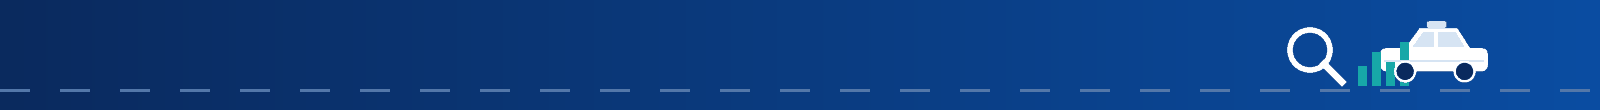

# <span style="color:#1D6FD8">Bagian 2: Eksplorasi Data</span>

<p style="line-height:1.6;">
Eksplorasi memakai tabel bersih dari Bagian 1 tanpa pembersihan tambahan. Setiap rasio menyebut pembilang, penyebut, dan unit analisisnya (request, trip, atau shift). Pola yang <strong>teramati</strong> dibedakan dari <strong>hipotesis</strong>, dan korelasi tidak diperlakukan sebagai sebab-akibat.
</p>

## <span style="color:#1D6FD8">2.1 Pertanyaan Analisis</span>

<p style="line-height:1.6;">
Eksplorasi dipandu oleh enam pertanyaan dari brief:
</p>

1. **Fulfilment:** seberapa sering request terpenuhi, dibatalkan karena tidak ada pengemudi, atau timeout? (2.4)
2. **Jam sibuk dan lokasi:** apakah kegagalan terpusat pada jam sibuk, di CBD, atau di area Airport? (2.4)
3. **Utilisasi armada:** berapa trip per shift, berapa idle time, dan adakah ketimpangan antar pool dan zona? (2.5)
4. **Efisiensi operasional:** apakah ketersediaan pengemudi, alokasi shift, dan posisi pengemudi ikut menyebabkan request gagal? (2.5, 2.7)
5. **Korporat dan pembayaran:** bagaimana pola trip B2B dan pemakaian eVoucher? (2.6)
6. **Kualitas data:** seberapa besar data meter yang buruk memengaruhi angka? (2.3)

## <span style="color:#1D6FD8">2.2 Gambaran Umum Dataset</span>

<p style="line-height:1.6;">
Sebelum menjawab pertanyaan spesifik, cakupan data, unit analisis, dan penyebut yang dipakai perlu dipastikan. Tabel eksplorasi disiapkan, lalu gambaran umum trip ditampilkan.
</p>

### <span style="color:#1D6FD8">2.2.1 Siapkan Tabel Eksplorasi</span>

<p style="line-height:1.6;">
Kolom bantu (jam, hari, flag) ditambahkan. Tidak ada baris yang dihapus.
</p>

In [116]:
# Requests: one row = one customer request (unit of analysis for Questions 1 and 2).
req = df_requests.copy()
req["hour"] = req["requested_time"].dt.hour
req["date"] = req["requested_time"].dt.date
req["month"] = req["requested_time"].dt.strftime("%Y-%m")
req["weekday"] = req["requested_time"].dt.day_name()
req["is_failed"] = req["status"] != "Fulfilled"
req["is_no_driver"] = req["status"] == "Cancelled-No Driver"
req["is_timeout"] = req["status"] == "Cancelled-Timeout"

# Sanity checks: nothing was added or lost, and the status labels are what we expect.
assert len(req) == len(df_requests)
assert req["request_id"].is_unique
assert set(req["status"].unique()) == {"Fulfilled", "Cancelled-No Driver", "Cancelled-Timeout"}
assert (req["is_failed"] == (req["is_no_driver"] | req["is_timeout"])).all()

def request_rates(data, by):
    """Counts and failure rates (in %) for any grouping. Denominator = all requests in the group."""
    out = data.groupby(by, observed=True).agg(
        requests=("request_id", "size"),
        failed=("is_failed", "sum"),
        no_driver=("is_no_driver", "sum"),
        timeout=("is_timeout", "sum"),
    )
    out["failed_pct"] = out["failed"] / out["requests"] * 100
    out["no_driver_pct"] = out["no_driver"] / out["requests"] * 100
    out["timeout_pct"] = out["timeout"] / out["requests"] * 100
    return out

print(f"Requests: {len(req):,} | period: {req['requested_time'].min()} to {req['requested_time'].max()}")

Requests: 289,622 | period: 2023-10-01 05:12:14 to 2023-12-30 08:20:27


In [117]:
# Fixed zone order used in every zone table and chart below.
zones_in_order = ["Airport", "CBD", "Mall", "Residential", "Other"]

### <span style="color:#1D6FD8">2.2.2 Gambaran Umum Trip</span>

<p style="line-height:1.6;">
Unit analisis: satu trip. Trip Street Hail tidak memiliki request, sehingga tabel request hanya mencerminkan permintaan lewat App dan Call Center.
</p>

In [118]:
trips_eda = df_trips_clean.copy()
trips_eda["is_corporate"] = trips_eda["company_id"].notna()
trips_eda["hour"] = trips_eda["booking_time"].dt.hour

for column in ["trip_type", "booking_channel", "service_type_clean", "payment_method", "pickup_zone_type"]:
    print(f"Trips by {column}:")
    table = trips_eda.groupby(column).agg(
        trips=("trip_id", "size"),
        median_fare=("total_fare", "median"),
        total_fare=("total_fare", "sum"),
        median_distance_km=("distance_km_clean", "median"),
    )
    table["trip_share_pct"] = table["trips"] / len(trips_eda) * 100
    display(table)

# Reconcile trips and requests: every fulfilled request has one trip; the rest are Street Hail.
print(f"Fulfilled requests: {(req['status'] == 'Fulfilled').sum():,} | trips with a request: {trips_eda['trip_id'].isin(req['matched_trip_id']).sum():,}")
print(f"Trips without a request (Street Hail): {(~trips_eda['trip_id'].isin(req['matched_trip_id'])).sum():,} "
      f"| Street Hail trips: {(trips_eda['booking_channel'] == 'Street Hail').sum():,}")

Trips by trip_type:


,trips,median_fare,total_fare,median_distance_km,trip_share_pct
trip_type,,,,,
Charter,3481,"1,098,500.00","3,904,553,500.00",219.30,1.12
Reguler,307526,"60,000.00","22,008,374,000.00",8.60,98.88


Trips by booking_channel:


,trips,median_fare,total_fare,median_distance_km,trip_share_pct
booking_channel,,,,,
App,186535,"60,500.00","15,569,204,500.00",8.60,59.98
Call Center,77638,"60,500.00","6,464,183,500.00",8.70,24.96
Street Hail,46834,"60,500.00","3,879,539,500.00",8.60,15.06


Trips by service_type_clean:


...

Trips by payment_method:


,trips,median_fare,total_fare,median_distance_km,trip_share_pct
payment_method,,,,,
Cash,87681,"60,000.00","7,176,241,500.00",8.50,28.19
Credit Card,44818,"59,500.00","3,664,233,500.00",8.50,14.41
MyBluebird App,122426,"59,500.00","10,028,515,000.00",8.50,39.36
eVoucher Corporate,56082,"64,500.00","5,043,937,500.00",9.30,18.03


Trips by pickup_zone_type:


,trips,median_fare,total_fare,median_distance_km,trip_share_pct
pickup_zone_type,,,,,
Airport,41304,"129,000.00","6,176,934,000.00",23.40,13.28
CBD,116426,"53,500.00","8,174,383,500.00",7.10,37.44
Mall,55773,"59,000.00","4,250,804,500.00",8.60,17.93
Other,44756,"63,000.00","3,620,216,500.00",9.60,14.39
Residential,52748,"53,000.00","3,690,589,000.00",7.80,16.96


Fulfilled requests: 270,225 | trips with a request: 264,173
Trips without a request (Street Hail): 46,834 | Street Hail trips: 46,834


## <span style="color:#1D6FD8">2.3 Permintaan Layanan dan Karakteristik Trip</span>

<p style="line-height:1.6;">
Bagian ini meninjau trip yang selesai, khususnya seberapa besar kualitas data meter memengaruhi rata-rata jarak dan delay. Hasilnya menjadi dasar kepercayaan terhadap seluruh angka berikutnya.
</p>

### <span style="color:#1D6FD8">2.3.1 Seberapa Besar Data Buruk Mengubah Angka Operasional?</span>

<p style="line-height:1.6;">
Rata-rata yang sama dihitung dengan dan tanpa nilai bertanda, untuk menilai pengaruh kualitas data meter.
</p>

In [119]:
quality_impact = pd.DataFrame({
    "raw": [
        trips_eda["distance_km"].mean(),
        trips_eda.loc[trips_eda["trip_type"] == "Reguler", "distance_km"].mean(),
        trips_eda["booking_to_meter_minutes"].mean(),
        df_requests["wait_time_minutes"].mean(),
    ],
    "clean": [
        trips_eda["distance_km_clean"].mean(),
        trips_eda.loc[trips_eda["trip_type"] == "Reguler", "distance_km_clean"].mean(),
        trips_eda["booking_to_meter_minutes_clean"].mean(),
        df_requests["wait_time_minutes_clean"].mean(),
    ],
}, index=["Average distance, all trips (km)", "Average distance, Reguler trips (km)",
          "Average booking-to-meter delay (min)", "Average request wait time (min)"])
quality_impact["difference"] = quality_impact["clean"] - quality_impact["raw"]
quality_impact["difference_pct"] = quality_impact["difference"] / quality_impact["raw"] * 100
display(quality_impact)

distance_by_zone = trips_eda.groupby("pickup_zone_type")[["distance_km", "distance_km_clean"]].mean()
display(distance_by_zone)
print(f"Trips with an unreliable distance: {trips_eda['flag_distance_unreliable'].sum():,} "
      f"({trips_eda['flag_distance_unreliable'].mean()*100:.2f}% of trips)")

,raw,clean,difference,difference_pct
"Average distance, all trips (km)",16.08,13.20,-2.88,-17.94
"Average distance, Reguler trips (km)",13.77,10.85,-2.93,-21.25
Average booking-to-meter delay (min),5.01,5.01,0.00,0.00
Average request wait time (min),4.91,5.01,0.09,1.91


,distance_km,distance_km_clean
pickup_zone_type,,
Airport,29.47,26.97
CBD,13.44,10.12
Mall,14.72,11.73
Other,15.29,12.87
Residential,13.54,11.02


Trips with an unreliable distance: 1,185 (0.38% of trips)


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Setelah 7.091 trip dengan jarak atau delay negatif dikeluarkan, masih ada 1.185 trip (0,38%) dengan jarak tidak andal (lebih dari 500 km atau kurang dari 1 km). Trip ini menggelembungkan rata-rata jarak: 16,08 km pada data mentah vs 13,20 km pada data bersih (selisih sekitar 18% dari angka mentah). Rata-rata delay booking-ke-meter sama (5,01 menit) karena delay negatif sudah dikeluarkan. Karena itu kolom <code>*_clean</code> dipakai untuk jarak, delay, dan waktu tunggu.
</div>

## <span style="color:#1D6FD8">2.4 Request dan Fulfilment</span>

<p style="line-height:1.6;">
Unit analisis: satu request, dan setiap rasio memakai seluruh request sebagai penyebut. Pertanyaannya disusun bertahap: seberapa sering gagal, kapan, di mana, apa jenis kegagalannya, dan seberapa besar masalahnya.
</p>

### <span style="color:#1D6FD8">2.4.1 Seberapa Sering Request Terpenuhi atau Gagal?</span>

<p style="line-height:1.6;">
Unit analisis: satu request. Penyebut: seluruh request. Status dibagi menjadi terpenuhi, dibatalkan karena tidak ada pengemudi, dan dibatalkan karena timeout.
</p>

In [120]:
status_table = req["status"].value_counts().to_frame("requests")
status_table["share_pct"] = status_table["requests"] / len(req) * 100
display(status_table)
print(f"Failed requests (No Driver + Timeout): {req['is_failed'].sum():,} of {len(req):,} = {req['is_failed'].mean()*100:.2f}%")
print(f"  No driver share of all failures: {req['is_no_driver'].sum() / req['is_failed'].sum() * 100:.1f}%")

,requests,share_pct
status,,
Fulfilled,270225,93.30
Cancelled-No Driver,13494,4.66
Cancelled-Timeout,5903,2.04


Failed requests (No Driver + Timeout): 19,397 of 289,622 = 6.70%
  No driver share of all failures: 69.6%


### <span style="color:#1D6FD8">2.4.2 Kegagalan per Jam</span>

<p style="line-height:1.6;">
Jumlah request (permintaan) dan tingkat kegagalan dilihat berdampingan, karena jam yang ramai belum tentu jam dengan kegagalan tertinggi.
</p>

In [121]:
by_hour = request_rates(req, "hour")
overall_failed_pct = req["is_failed"].mean() * 100
display(by_hour[["requests", "failed", "failed_pct", "no_driver_pct", "timeout_pct"]])

# Define the hour groups FROM THE DATA (not from assumption):
#  - failure-peak hours = hours where the failure rate is more than 2x the overall rate
#  - demand-peak hours  = the 5 hours with the most requests
failure_peak_hours = sorted(by_hour.index[by_hour["failed_pct"] > 2 * overall_failed_pct])
demand_peak_hours = sorted(by_hour["requests"].nlargest(5).index)
print(f"Overall failure rate: {overall_failed_pct:.2f}%")
print("Failure-peak hours (rate > 2x overall):", failure_peak_hours)
print("Demand-peak hours (top 5 by request volume):", demand_peak_hours)
print("Overlap between the two groups:", sorted(set(failure_peak_hours) & set(demand_peak_hours)))

req["period"] = np.where(
    req["hour"].isin(failure_peak_hours), "Failure-peak hours",
    np.where(req["hour"].isin(demand_peak_hours), "Demand-peak hours", "Other hours"),
)
display(request_rates(req, "period"))

,requests,failed,failed_pct,no_driver_pct,timeout_pct
hour,,,,,
0,2390,98,4.10,2.76,1.34
1,3496,158,4.52,3.38,1.14
2,5289,185,3.50,2.40,1.10
3,5827,224,3.84,2.61,1.24
4,5458,224,4.10,2.58,1.52
5,7052,276,3.91,2.94,0.98
6,9692,614,6.34,4.42,1.92
7,13830,3040,21.98,15.07,6.91
8,17344,3893,22.45,15.74,6.71


Overall failure rate: 6.70%
Failure-peak hours (rate > 2x overall): [7, 8, 17, 18]
Demand-peak hours (top 5 by request volume): [12, 13, 14, 15, 16]
Overlap between the two groups: []


,requests,failed,no_driver,timeout,failed_pct,no_driver_pct,timeout_pct
period,,,,,,,
Demand-peak hours,153518,6257,4364,1893,4.08,2.84,1.23
Failure-peak hours,41349,8838,6139,2699,21.37,14.85,6.53
Other hours,94755,4302,2991,1311,4.54,3.16,1.38


### <span style="color:#1D6FD8">2.4.3 Kegagalan per Zona, Sumber Request, Bulan, dan Hari</span>

<p style="line-height:1.6;">
Tingkat kegagalan dibandingkan antar zona, channel request, bulan, dan hari untuk melihat faktor mana yang benar-benar berbeda.
</p>

In [122]:
print("By pickup zone:")
display(request_rates(req, "pickup_zone_type").sort_values("failed_pct", ascending=False))
print("By request source:")
display(request_rates(req, "request_source"))
print("By month:")
display(request_rates(req, "month"))
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print("By weekday:")
display(request_rates(req, "weekday").reindex(weekday_order))

By pickup zone:


,requests,failed,no_driver,timeout,failed_pct,no_driver_pct,timeout_pct
pickup_zone_type,,,,,,,
CBD,113817,12605,8793,3812,11.07,7.73,3.35
Residential,47997,2093,1438,655,4.36,3.00,1.36
Mall,50534,2197,1560,637,4.35,3.09,1.26
Other,40687,1759,1208,551,4.32,2.97,1.35
Airport,36587,743,495,248,2.03,1.35,0.68


By request source:


,requests,failed,no_driver,timeout,failed_pct,no_driver_pct,timeout_pct
request_source,,,,,,,
App,205408,14567,10128,4439,7.09,4.93,2.16
Call Center,84214,4830,3366,1464,5.74,4.00,1.74


By month:


,requests,failed,no_driver,timeout,failed_pct,no_driver_pct,timeout_pct
month,,,,,,,
2023-10,98921,6611,4557,2054,6.68,4.61,2.08
2023-11,96456,6466,4576,1890,6.70,4.74,1.96
2023-12,94245,6320,4361,1959,6.71,4.63,2.08


By weekday:


,requests,failed,no_driver,timeout,failed_pct,no_driver_pct,timeout_pct
weekday,,,,,,,
Monday,41982,2770,1925,845,6.60,4.59,2.01
Tuesday,41391,2735,1898,837,6.61,4.59,2.02
Wednesday,42482,2969,2077,892,6.99,4.89,2.10
Thursday,41618,2744,1915,829,6.59,4.60,1.99
Friday,41613,2788,1910,878,6.70,4.59,2.11
Saturday,39325,2656,1863,793,6.75,4.74,2.02
Sunday,41211,2735,1906,829,6.64,4.62,2.01


### <span style="color:#1D6FD8">2.4.4 Kombinasi Zona × Jam</span>

<p style="line-height:1.6;">
Zona dan jam dikombinasikan untuk mengetahui apakah masalahnya ada di CBD, di jam sibuk, atau pada keduanya.
</p>

In [123]:
zone_by_period = req.pivot_table(
    index="pickup_zone_type", columns="period", values="is_failed", aggfunc="mean"
) * 100
zone_by_period_n = req.pivot_table(
    index="pickup_zone_type", columns="period", values="is_failed", aggfunc="size"
)
print("Failure rate (%) by zone and hour group:")
display(zone_by_period)
print("Number of requests behind each cell:")
display(zone_by_period_n)

# Same crossing, but for the individual failure-peak hours.
cbd_hours = request_rates(req[req["pickup_zone_type"] == "CBD"], "hour")[["requests", "failed_pct"]]
print("CBD only, failure rate by hour:")
display(cbd_hours.T)

# How much of ALL failures sit in CBD + failure-peak hours?
cbd_peak = (req["pickup_zone_type"] == "CBD") & (req["period"] == "Failure-peak hours")
print(f"CBD requests in failure-peak hours: {cbd_peak.sum():,} ({cbd_peak.mean()*100:.1f}% of all requests)")
print(f"They contain {req.loc[cbd_peak, 'is_failed'].sum():,} of {req['is_failed'].sum():,} failures "
      f"({req.loc[cbd_peak, 'is_failed'].sum() / req['is_failed'].sum() * 100:.1f}% of all failures)")
print(f"Failure rate: CBD + failure-peak = {req.loc[cbd_peak, 'is_failed'].mean()*100:.1f}% "
      f"vs everything else = {req.loc[~cbd_peak, 'is_failed'].mean()*100:.1f}%")

# Statistical check. With ~290k rows almost any difference is 'significant', so we also report the effect size.
try:
    from scipy.stats import chi2_contingency
    table_2x2 = pd.crosstab(cbd_peak, req["is_failed"])
    chi2, p_value, _, _ = chi2_contingency(table_2x2)
    a, b = table_2x2.loc[True, True], table_2x2.loc[True, False]
    c, d = table_2x2.loc[False, True], table_2x2.loc[False, False]
    print(f"Chi-square p-value: {max(p_value, 1e-300):.3g} (effectively 0) | odds ratio: {(a / b) / (c / d):.1f} (failure odds, CBD+peak vs rest)")
except ImportError:
    print("scipy not installed: skip the chi-square test (pip install scipy).")

Failure rate (%) by zone and hour group:


period,Demand-peak hours,Failure-peak hours,Other hours
pickup_zone_type,,,
Airport,2.04,2.27,1.94
CBD,5.10,36.55,6.07
Mall,3.83,7.57,3.98
Other,4.05,7.14,3.74
Residential,3.90,7.43,3.93


Number of requests behind each cell:


period,Demand-peak hours,Failure-peak hours,Other hours
pickup_zone_type,,,
Airport,21636,3485,11466
CBD,54903,20436,38478
Mall,27549,6358,16627
Other,22866,4933,12888
Residential,26564,6137,15296


CBD only, failure rate by hour:


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
requests,986.00,"1,327.00","1,786.00","2,028.00","1,808.00","2,575.00","3,998.00","7,168.00","9,150.00","7,063.00","6,728.00","6,996.00","9,371.00","12,780.00","13,480.00","11,732.00","7,540.00","3,564.00",554.00,303.00,491.00,655.00,821.00,913.00
failed_pct,4.36,5.88,4.37,4.59,5.31,4.58,10.18,36.59,36.60,8.81,4.79,4.37,4.65,5.01,4.78,4.86,6.75,35.52,41.88,10.23,5.09,4.73,4.75,5.04


CBD requests in failure-peak hours: 20,436 (7.1% of all requests)
They contain 7,470 of 19,397 failures (38.5% of all failures)
Failure rate: CBD + failure-peak = 36.6% vs everything else = 4.4%
Chi-square p-value: 1e-300 (effectively 0) | odds ratio: 12.4 (failure odds, CBD+peak vs rest)


### <span style="color:#1D6FD8">2.4.5 Jenis Kegagalan</span>

<p style="line-height:1.6;">
<code>Cancelled-No Driver</code> mengarah ke sisi pasokan. <code>Cancelled-Timeout</code> bisa berarti pengemudi lambat merespons atau pelanggan menyerah menunggu.
</p>

In [124]:
split = request_rates(req, ["pickup_zone_type", "period"])[["requests", "no_driver_pct", "timeout_pct"]]
display(split.loc[["CBD", "Airport"]])
print("Share of failures that are 'No Driver', by group (denominator = failed requests in that group):")
failed_only = req[req["is_failed"]]
display((failed_only.groupby("period")["is_no_driver"].mean() * 100).to_frame("no_driver_share_of_failures_pct"))

requests  no_driver_pct  timeout_pct
pickup_zone_type period                                                  
CBD              Demand-peak hours      54903           3.53         1.57
                 Failure-peak hours     20436          25.50        11.05
                 Other hours            38478           4.27         1.80
Airport          Demand-peak hours      21636           1.43         0.61
                 Failure-peak hours      3485           1.26         1.00
                 Other hours            11466           1.24         0.71

Share of failures that are 'No Driver', by group (denominator = failed requests in that group):


,no_driver_share_of_failures_pct
period,
Demand-peak hours,69.75
Failure-peak hours,69.46
Other hours,69.53


### <span style="color:#1D6FD8">2.4.6 Waktu Tunggu Request yang Terpenuhi</span>

<p style="line-height:1.6;">
Waktu tunggu hanya tersedia untuk request yang terpenuhi. Analisis memakai <code>wait_time_minutes_clean</code>, dan nilainya bersifat indikatif karena ada batas bawah 0,5 menit.
</p>

In [125]:
fulfilled = req[req["status"] == "Fulfilled"]
print("Wait time (minutes), fulfilled requests, using wait_time_minutes_clean:")
display(fulfilled["wait_time_minutes_clean"].describe().to_frame("wait_time_minutes_clean"))
print(f"Fulfilled requests with wait_time_minutes_clean empty: {fulfilled['wait_time_minutes_clean'].isna().sum():,}")
print("Median wait (min) by hour group and zone:")
display(fulfilled.pivot_table(index="pickup_zone_type", columns="period",
                              values="wait_time_minutes_clean", aggfunc="median"))

Wait time (minutes), fulfilled requests, using wait_time_minutes_clean:


,wait_time_minutes_clean
count,"264,596.00"
mean,5.01
std,1.98
min,0.50
25%,3.70
50%,5.00
75%,6.30
max,14.20


Fulfilled requests with wait_time_minutes_clean empty: 5,629
Median wait (min) by hour group and zone:


period,Demand-peak hours,Failure-peak hours,Other hours
pickup_zone_type,,,
Airport,5.00,4.90,5.00
CBD,5.00,5.00,5.00
Mall,5.00,5.00,5.00
Other,5.00,5.00,5.00
Residential,5.00,5.00,5.00


### <span style="color:#1D6FD8">2.4.7 Besar Masalah Request Gagal (Ilustrasi dengan Asumsi)</span>

<p style="line-height:1.6;">
Berapa request dan nilai tarif yang dipertaruhkan jika kegagalan di jam sibuk setara dengan jam lain pada zona yang sama? Tiga asumsi dipakai: (1) request yang tadinya gagal akan terpenuhi, (2) setiap request menghasilkan median tarif trip di zona yang sama, dan (3) periode yang dihitung 2023-10-01 sampai 2023-12-30. Hasilnya adalah batas atas ilustratif, bukan prakiraan.
</p>

In [126]:
fare_of_trip = trips_eda.set_index("trip_id")["total_fare"]
req["trip_fare"] = req["matched_trip_id"].map(fare_of_trip)           # fare only exists for fulfilled requests
median_fare_by_zone = req.groupby("pickup_zone_type")["trip_fare"].median()

rows = []
for zone in zones_in_order:
    zone_requests = req[req["pickup_zone_type"] == zone]
    in_peak = zone_requests["period"] == "Failure-peak hours"
    peak_rate = zone_requests.loc[in_peak, "is_failed"].mean()
    reference_rate = zone_requests.loc[~in_peak, "is_failed"].mean()
    excess = in_peak.sum() * (peak_rate - reference_rate)
    rows.append({
        "zone": zone,
        "peak_requests": int(in_peak.sum()),
        "peak_failure_pct": peak_rate * 100,
        "reference_failure_pct": reference_rate * 100,
        "excess_failed_requests": excess,
        "median_fare": median_fare_by_zone[zone],
        "fare_at_stake_rp": excess * median_fare_by_zone[zone],
    })
impact = pd.DataFrame(rows).set_index("zone")
display(impact.round(1))
total_failed = int(req["is_failed"].sum())
print(f"Total failed requests: {total_failed:,}")
print(f"Excess failures in the failure-peak hours (all zones): {impact['excess_failed_requests'].sum():,.0f} "
      f"= {impact['excess_failed_requests'].sum() / total_failed * 100:.1f}% of all failures")
print(f"  of which CBD: {impact.loc['CBD', 'excess_failed_requests']:,.0f} "
      f"= {impact.loc['CBD', 'excess_failed_requests'] / impact['excess_failed_requests'].sum() * 100:.0f}% of the excess")
print(f"Fare at stake (all zones, median fare, 3 months): Rp {impact['fare_at_stake_rp'].sum():,.0f}  "
      f"vs total fare of all trips: Rp {trips_eda['total_fare'].sum():,.0f} "
      f"({impact['fare_at_stake_rp'].sum() / trips_eda['total_fare'].sum() * 100:.1f}%)")

,peak_requests,peak_failure_pct,reference_failure_pct,excess_failed_requests,median_fare,fare_at_stake_rp
zone,,,,,,
Airport,3485,2.30,2.00,9.10,"129,000.00","1,173,080.80"
CBD,20436,36.60,5.50,"6,346.20","53,500.00","339,523,251.40"
Mall,6358,7.60,3.90,234.00,"59,000.00","13,807,527.90"
Residential,6137,7.40,3.90,216.00,"53,000.00","11,448,165.90"
Other,4933,7.10,3.90,157.90,"63,000.00","9,946,150.10"


Total failed requests: 19,397
Excess failures in the failure-peak hours (all zones): 6,963 = 35.9% of all failures
  of which CBD: 6,346 = 91% of the excess
Fare at stake (all zones, median fare, 3 months): Rp 375,898,176  vs total fare of all trips: Rp 25,912,927,500 (1.5%)


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Jika jam puncak kegagalan sama rendahnya dengan jam lain, sekitar 6.960 request lebih sedikit yang gagal (35,9% dari 19.397), dan <strong>91% di antaranya (6.346 request) ada di CBD</strong>. Pada median tarif, nilainya sekitar Rp 376 juta dalam tiga bulan, hanya 1,5% dari total tarif Rp 25,9 miliar. Nilai langsungnya relatif kecil; argumen yang lebih kuat adalah sekitar 6.300 pelanggan CBD yang tidak mendapat taksi dan dampaknya terhadap reputasi layanan. Rp 376 juta adalah batas atas.
</div>

## <span style="color:#1D6FD8">2.5 Pengemudi dan Shift</span>

<p style="line-height:1.6;">
Setelah diketahui <em>di mana dan kapan</em> request gagal, pertanyaan berikutnya beralih ke sisi pasokan: apakah pengemudi cukup, berapa trip yang mereka peroleh, dan seberapa idle mereka? Unit analisis: satu shift pengemudi.
</p>

### <span style="color:#1D6FD8">2.5.1 Apakah Pasokan Pengemudi per Jam Cukup?</span>

<p style="line-height:1.6;">
Untuk setiap jam dihitung rata-rata jumlah shift yang aktif pada jam itu, selama 90 hari penuh (2023-10-01 sampai 2023-12-29). Sebuah shift dihitung jika rentang clock-in sampai clock-out menyentuh jam tersebut, sehingga shift yang hanya aktif sebagian jam tetap dihitung 1. Satu shift setara satu pengemudi per hari. Label jam adalah awal jam (17 = 17:00–17:59), lalu hasilnya dibandingkan dengan jumlah request. Ini pola yang teramati, bukan bukti sebab.
</p>

In [127]:
FIRST_DAY = pd.Timestamp("2023-10-01")
N_DAYS = 90                      # 2023-10-01 ... 2023-12-29 = 31 + 30 + 29 full days
N_SLOTS = N_DAYS * 24

def drivers_on_shift_by_hour(shifts):
    """Average number of shifts that are 'on duty' in each hour of the day (0-23)."""
    start_slot = ((shifts["clock_in_time"].dt.floor("h") - FIRST_DAY) // pd.Timedelta(hours=1)).to_numpy()
    end_slot = ((shifts["clock_out_time"].dt.floor("h") - FIRST_DAY) // pd.Timedelta(hours=1)).to_numpy() + 1
    size = N_SLOTS + 100
    assert start_slot.min() >= 0 and start_slot.max() < N_SLOTS and end_slot.max() < size
    change = np.bincount(start_slot, minlength=size) - np.bincount(end_slot, minlength=size)
    on_duty = np.cumsum(change)[:N_SLOTS]
    return pd.Series(on_duty.reshape(N_DAYS, 24).mean(axis=0), index=range(24))

full_days_req = req[req["requested_time"] < pd.Timestamp("2023-12-30")]
supply_demand = pd.DataFrame({
    "drivers_on_shift": drivers_on_shift_by_hour(df_shifts_clean),
    "requests_per_hour": full_days_req.groupby("hour").size() / N_DAYS,
    "failed_pct": request_rates(full_days_req, "hour")["failed_pct"],
})
supply_demand["requests_per_driver"] = supply_demand["requests_per_hour"] / supply_demand["drivers_on_shift"]
display(supply_demand)

corr = supply_demand["requests_per_driver"].corr(supply_demand["failed_pct"])
print(f"Correlation across the 24 hours: requests_per_driver vs failure rate = {corr:.2f}")
print("Hours with fewer than 400 drivers on shift:", list(supply_demand.index[supply_demand["drivers_on_shift"] < 400]))

,drivers_on_shift,requests_per_hour,failed_pct,requests_per_driver
0,489.71,26.28,4.14,0.05
1,489.04,38.50,4.56,0.08
2,478.78,58.14,3.54,0.12
3,429.69,64.09,3.87,0.15
4,342.27,59.94,4.13,0.18
5,826.41,77.84,3.93,0.09
6,"1,305.64",107.34,6.35,0.08
7,"1,794.39",153.52,21.99,0.09
8,"2,321.58",192.68,22.44,0.08
9,"2,311.30",177.07,5.91,0.08


Correlation across the 24 hours: requests_per_driver vs failure rate = 0.03
Hours with fewer than 400 drivers on shift: [4, 17, 18, 19, 20, 21]


In [128]:
# The same view for the CBD only: drivers whose dominant zone is CBD vs requests picked up in the CBD.
cbd_supply_demand = pd.DataFrame({
    "cbd_drivers_on_shift": drivers_on_shift_by_hour(df_shifts_clean[df_shifts_clean["dominant_zone_worked"] == "CBD"]),
    "cbd_requests_per_hour": full_days_req[full_days_req["pickup_zone_type"] == "CBD"].groupby("hour").size() / N_DAYS,
    "cbd_failed_pct": request_rates(full_days_req[full_days_req["pickup_zone_type"] == "CBD"], "hour")["failed_pct"],
})
cbd_supply_demand["cbd_requests_per_driver"] = (
    cbd_supply_demand["cbd_requests_per_hour"] / cbd_supply_demand["cbd_drivers_on_shift"]
)
display(cbd_supply_demand.T)
print("Correlation (24 hours): CBD requests per driver vs CBD failure rate =",
      round(cbd_supply_demand["cbd_requests_per_driver"].corr(cbd_supply_demand["cbd_failed_pct"]), 2))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
cbd_drivers_on_shift,139.34,139.08,136.34,122.76,98.09,253.26,409.06,563.84,731.36,728.32,728.16,728.16,726.87,707.80,614.96,452.83,272.22,109.48,47.73,56.41,83.88,111.33,140.99,140.99
cbd_requests_per_hour,10.84,14.64,19.72,22.28,19.83,28.40,44.31,79.59,101.63,78.48,74.76,77.73,104.12,142.00,149.78,130.36,83.78,39.60,6.16,3.37,5.46,7.28,9.12,10.14
cbd_failed_pct,4.41,5.92,4.39,4.64,5.38,4.62,10.21,36.59,36.59,8.81,4.79,4.37,4.65,5.01,4.78,4.86,6.75,35.52,41.88,10.23,5.09,4.73,4.75,5.04
cbd_requests_per_driver,0.08,0.11,0.14,0.18,0.20,0.11,0.11,0.14,0.14,0.11,0.10,0.11,0.14,0.20,0.24,0.29,0.31,0.36,0.13,0.06,0.07,0.07,0.06,0.07


Correlation (24 hours): CBD requests per driver vs CBD failure rate = 0.21


### <span style="color:#1D6FD8">2.5.2 Utilisasi Armada per Shift</span>

<p style="line-height:1.6;">
Unit analisis: satu shift pengemudi. <code>ritase_target_met</code> setara dengan <code>trip_count &gt;= 6</code>, tetapi brief tidak mendefinisikan target tersebut.
</p>

In [129]:
# Add driver and pool attributes with .map() so the number of rows can NOT change.
shifts_eda = df_shifts_clean.copy()
shifts_eda["pool_id"] = shifts_eda["driver_id"].map(df_drivers.set_index("driver_id")["pool_id"])
shifts_eda["employment_status"] = shifts_eda["driver_id"].map(df_drivers.set_index("driver_id")["employment_status"])
shifts_eda["vehicle_type_assigned"] = shifts_eda["driver_id"].map(df_drivers.set_index("driver_id")["vehicle_type_assigned"])
shifts_eda["start_hour"] = shifts_eda["clock_in_time"].dt.hour
shifts_eda["start_group"] = np.where(shifts_eda["start_hour"] < 12, "Morning start", "Evening start")
shifts_eda["idle_share_pct"] = shifts_eda["total_idle_minutes"] / shifts_eda["shift_duration_minutes"] * 100
shifts_eda["zero_trip_shift"] = shifts_eda["trip_count"] == 0

assert len(shifts_eda) == len(df_shifts_clean)
assert shifts_eda[["pool_id", "employment_status", "vehicle_type_assigned"]].notna().all().all()
print("Shift start hours present:", [int(h) for h in sorted(shifts_eda["start_hour"].unique())])

print("Trips per shift (trip_count):")
display(shifts_eda["trip_count"].describe().to_frame("trip_count"))
display(shifts_eda["trip_count"].value_counts().sort_index().to_frame("shifts").assign(
    share_pct=lambda t: t["shifts"] / len(shifts_eda) * 100))
print(f"Shifts that met the target (>= 6 trips): {shifts_eda['ritase_target_met'].sum():,} of {len(shifts_eda):,} "
      f"= {shifts_eda['ritase_target_met'].mean()*100:.2f}%")
print(f"Shifts with 0 trips: {shifts_eda['zero_trip_shift'].sum():,} = {shifts_eda['zero_trip_shift'].mean()*100:.1f}%")
print("Shift duration and idle time:")
display(shifts_eda[["shift_duration_minutes", "total_idle_minutes", "idle_share_pct"]].describe())

Shift start hours present: [5, 6, 7, 8, 18, 19, 20, 21, 22]
Trips per shift (trip_count):


,trip_count
count,"252,524.00"
mean,1.26
std,1.19
min,0.00
25%,0.00
50%,1.00
75%,2.00
max,10.00


,shifts,share_pct
trip_count,,
0,77393,30.65
1,85303,33.78
2,53540,21.20
3,24080,9.54
4,8706,3.45
5,2608,1.03
6,692,0.27
7,166,0.07
8,28,0.01


Shifts that met the target (>= 6 trips): 894 of 252,524 = 0.35%
Shifts with 0 trips: 77,393 = 30.6%
Shift duration and idle time:


,shift_duration_minutes,total_idle_minutes,idle_share_pct
count,"252,524.00","252,524.00","252,524.00"
mean,509.99,460.74,90.26
std,45.08,71.80,11.10
min,300.00,0.00,0.00
25%,479.70,422.30,85.75
50%,509.88,467.90,92.76
75%,540.33,508.50,100.00
max,660.00,660.00,100.01


In [130]:
def shift_summary(data, by):
    """One row per group. Unit = driver shift. Target = trip_count >= 6."""
    out = data.groupby(by, observed=True).agg(
        shifts=("shift_id", "size"),
        drivers=("driver_id", "nunique"),
        avg_trips_per_shift=("trip_count", "mean"),
        zero_trip_pct=("zero_trip_shift", lambda s: s.mean() * 100),
        target_met_pct=("ritase_target_met", lambda s: s.mean() * 100),
        avg_idle_share_pct=("idle_share_pct", "mean"),
        avg_duration_min=("shift_duration_minutes", "mean"),
    )
    return out

for column in ["pool_id", "dominant_zone_worked", "start_group", "employment_status", "vehicle_type_assigned"]:
    print(f"Shift summary by {column}:")
    display(shift_summary(shifts_eda, column))

Shift summary by pool_id:


,shifts,drivers,avg_trips_per_shift,zero_trip_pct,target_met_pct,avg_idle_share_pct,avg_duration_min
pool_id,,,,,,,
PL-BSD,30340,485,1.25,30.50,0.34,90.53,510.13
PL-CGK,40093,644,0.97,40.47,0.14,92.15,510.07
PL-CPT,32287,520,1.25,30.53,0.31,90.42,510.08
PL-HLM,26557,425,1.24,31.23,0.25,90.58,509.74
PL-KJT,33997,548,1.40,26.55,0.54,89.13,510.05
PL-KLG,32236,515,1.39,26.82,0.48,89.28,510.02
PL-MPG,28910,464,1.40,26.34,0.51,89.18,509.84
PL-PRI,28104,454,1.26,30.15,0.28,90.42,509.85


Shift summary by dominant_zone_worked:


,shifts,drivers,avg_trips_per_shift,zero_trip_pct,target_met_pct,avg_idle_share_pct,avg_duration_min
dominant_zone_worked,,,,,,,
Airport,55158,4054,0.67,51.14,0.00,93.90,509.88
CBD,78223,4053,1.70,18.62,0.84,86.35,510.03
Mall,41580,4053,1.33,26.69,0.30,90.04,509.84
Other,35658,4055,1.16,31.55,0.10,91.39,510.36
Residential,41905,4053,1.23,29.29,0.17,92.06,509.87


Shift summary by start_group:


,shifts,drivers,avg_trips_per_shift,zero_trip_pct,target_met_pct,avg_idle_share_pct,avg_duration_min
start_group,,,,,,,
Evening start,44564,4055,1.01,38.39,0.12,92.22,510.52
Morning start,207960,4055,1.31,28.99,0.40,89.84,509.87


Shift summary by employment_status:


,shifts,drivers,avg_trips_per_shift,zero_trip_pct,target_met_pct,avg_idle_share_pct,avg_duration_min
employment_status,,,,,,,
Mitra,43422,909,1.26,30.87,0.37,90.30,509.88
Tetap,209102,3146,1.26,30.60,0.35,90.26,510.01


Shift summary by vehicle_type_assigned:


,shifts,drivers,avg_trips_per_shift,zero_trip_pct,target_met_pct,avg_idle_share_pct,avg_duration_min
vehicle_type_assigned,,,,,,,
Electric,25503,410,1.25,30.92,0.40,90.35,510.74
Golden,17922,292,1.26,30.70,0.35,90.21,509.61
Reguler,157315,2523,1.26,30.66,0.34,90.29,509.95
Silver,51784,830,1.27,30.46,0.37,90.16,509.85


### <span style="color:#1D6FD8">2.5.3 Pool: Ukuran, Lokasi, dan Beban Kerja</span>

<p style="line-height:1.6;">
Atribut pool diambil dari <code>df_pools</code> (8 baris) dengan <code>.map()</code> agar jumlah baris tidak berubah.
</p>

In [131]:
pool_table = shift_summary(shifts_eda, "pool_id").join(
    df_pools.set_index("pool_id")[["region_area", "distance_to_soetta_km", "distance_to_cbd_km", "primary_zone_affinity"]]
)
# Trips completed per driver over the whole period (a simple ritase view per driver).
pool_table["trips_per_driver_total"] = (
    shifts_eda.groupby("pool_id")["trip_count"].sum() / pool_table["drivers"]
)
display(pool_table)

# Does the zone a pool's drivers work match the pool's label? (checks the 'zone affinity' attribute)
print("Share of shifts by dominant zone, per pool (rows add to 1):")
display(pd.crosstab(shifts_eda["pool_id"], shifts_eda["dominant_zone_worked"], normalize="index").round(2))

# Are requests where the drivers are? Share of requests by zone vs share of shifts by dominant zone.
zone_balance = pd.DataFrame({
    "request_share_pct": req["pickup_zone_type"].value_counts(normalize=True) * 100,
    "shift_share_pct": shifts_eda["dominant_zone_worked"].value_counts(normalize=True) * 100,
})
zone_balance["avg_trips_per_shift"] = shifts_eda.groupby("dominant_zone_worked")["trip_count"].mean()
display(zone_balance)

,shifts,drivers,avg_trips_per_shift,zero_trip_pct,target_met_pct,avg_idle_share_pct,avg_duration_min,region_area,distance_to_soetta_km,distance_to_cbd_km,primary_zone_affinity,trips_per_driver_total
pool_id,,,,,,,,,,,,
PL-BSD,30340,485,1.25,30.50,0.34,90.53,510.13,Tangerang Selatan,32.00,26.00,Mixed,77.89
PL-CGK,40093,644,0.97,40.47,0.14,92.15,510.07,Tangerang,3.50,28.00,Airport-heavy,60.32
PL-CPT,32287,520,1.25,30.53,0.31,90.42,510.08,Tangerang Selatan,35.00,18.00,Mixed,77.87
PL-HLM,26557,425,1.24,31.23,0.25,90.58,509.74,Jakarta Timur,41.00,12.00,Mixed,77.54
PL-KJT,33997,548,1.40,26.55,0.54,89.13,510.05,Jakarta Timur,38.00,14.00,CBD-heavy,86.75
PL-KLG,32236,515,1.39,26.82,0.48,89.28,510.02,Jakarta Utara,26.00,16.00,CBD-heavy,86.93
PL-MPG,28910,464,1.40,26.34,0.51,89.18,509.84,Jakarta Selatan,30.00,8.00,CBD-heavy,87.04
PL-PRI,28104,454,1.26,30.15,0.28,90.42,509.85,Jakarta Barat,22.00,15.00,Mixed,77.83


Share of shifts by dominant zone, per pool (rows add to 1):


dominant_zone_worked,Airport,CBD,Mall,Other,Residential
pool_id,,,,,
PL-BSD,0.20,0.25,0.20,0.15,0.20
PL-CGK,0.55,0.15,0.10,0.10,0.10
PL-CPT,0.20,0.25,0.20,0.15,0.20
PL-HLM,0.20,0.25,0.20,0.15,0.20
PL-KJT,0.10,0.45,0.15,0.15,0.15
PL-KLG,0.10,0.45,0.15,0.15,0.15
PL-MPG,0.10,0.45,0.15,0.15,0.15
PL-PRI,0.20,0.25,0.20,0.15,0.20


,request_share_pct,shift_share_pct,avg_trips_per_shift
Airport,12.63,21.84,0.67
CBD,39.30,30.98,1.70
Mall,17.45,16.47,1.33
Other,14.05,14.12,1.16
Residential,16.57,16.59,1.23


### <span style="color:#1D6FD8">2.5.4 Definisi Ritase: Satu Shift = Satu Hari Kerja Pengemudi?</span>

<p style="line-height:1.6;">
Brief mendefinisikan ritase sebagai jumlah trip per pengemudi per hari. Jika setiap pengemudi memiliki paling banyak satu shift per hari, maka shift dan driver-day identik.
</p>

In [132]:
shifts_per_driver_day = shifts_eda.groupby(["driver_id", "shift_date"]).size()
print("Shifts per driver per day (value : number of driver-days):")
print(shifts_per_driver_day.value_counts().sort_index().to_dict())
assert shifts_per_driver_day.max() == 1, "Some drivers have 2 shifts in a day: sum trip_count per driver-day first"
print("OK: one shift = one driver-day, so trip_count per shift IS the daily ritase.")

# Average ritase per DRIVER (each driver counts once, so drivers with many shifts do not dominate).
ritase_per_driver = shifts_eda.groupby("driver_id")["trip_count"].mean()
display(ritase_per_driver.describe().to_frame("avg_trips_per_day_per_driver"))

Shifts per driver per day (value : number of driver-days):
{1: 252524}


OK: one shift = one driver-day, so trip_count per shift IS the daily ritase.


,avg_trips_per_day_per_driver
count,"4,055.00"
mean,1.26
std,0.21
min,0.45
25%,1.13
50%,1.27
75%,1.41
max,1.93


### <span style="color:#1D6FD8">2.5.5 Mengapa Pool Berbeda: Pool atau Zona Kerja?</span>

<p style="line-height:1.6;">
Rata-rata nyata setiap pool dibandingkan dengan rata-rata yang <em>diharapkan</em> apabila setiap shift menghasilkan rata-rata seluruh pool pada zonanya (standarisasi langsung).
</p>

In [133]:
print("Average trips per shift: pool x dominant zone (compare the rows inside one column):")
display(shifts_eda.pivot_table(index="pool_id", columns="dominant_zone_worked",
                               values="trip_count", aggfunc="mean").round(2))

zone_average = shifts_eda.groupby("dominant_zone_worked")["trip_count"].mean()
shifts_eda["expected_trips_from_zone"] = shifts_eda["dominant_zone_worked"].map(zone_average)
pool_vs_expected = shifts_eda.groupby("pool_id").agg(
    actual_avg_trips=("trip_count", "mean"),
    expected_from_zone_mix=("expected_trips_from_zone", "mean"),
)
pool_vs_expected["gap"] = pool_vs_expected["actual_avg_trips"] - pool_vs_expected["expected_from_zone_mix"]
display(pool_vs_expected.round(3))
print("Largest absolute gap between actual and zone-mix expectation:",
      round(pool_vs_expected["gap"].abs().max(), 3), "trips per shift")
print("Spread between best and worst pool (actual):",
      round(pool_vs_expected["actual_avg_trips"].max() - pool_vs_expected["actual_avg_trips"].min(), 2), "trips per shift")

Average trips per shift: pool x dominant zone (compare the rows inside one column):


dominant_zone_worked,Airport,CBD,Mall,Other,Residential
pool_id,,,,,
PL-BSD,0.68,1.71,1.34,1.13,1.23
PL-CGK,0.66,1.64,1.29,1.15,1.18
PL-CPT,0.69,1.70,1.33,1.19,1.23
PL-HLM,0.66,1.69,1.33,1.17,1.23
PL-KJT,0.70,1.71,1.34,1.13,1.24
PL-KLG,0.69,1.70,1.33,1.15,1.25
PL-MPG,0.67,1.71,1.35,1.15,1.24
PL-PRI,0.70,1.70,1.35,1.18,1.24


,actual_avg_trips,expected_from_zone_mix,gap
pool_id,,,
PL-BSD,1.25,1.25,-0.00
PL-CGK,0.97,1.00,-0.03
PL-CPT,1.25,1.25,0.01
PL-HLM,1.24,1.24,-0.00
PL-KJT,1.40,1.39,0.01
PL-KLG,1.39,1.39,0.00
PL-MPG,1.40,1.39,0.01
PL-PRI,1.26,1.25,0.01


Largest absolute gap between actual and zone-mix expectation: 0.027 trips per shift
Spread between best and worst pool (actual): 0.43 trips per shift


### <span style="color:#1D6FD8">2.5.6 Catatan: <code>dominant_zone_worked</code> Sebagian Merupakan Hasil Pekerjaan</span>

<p style="line-height:1.6;">
Jika zona dominan dihitung dari trip yang dikerjakan pengemudi, pernyataan "shift CBD punya lebih banyak trip" menjadi sebagian sirkular. Karena itu diuji apakah zona dominan shift sama dengan zona penjemputan tersering dari trip pada shift itu.
</p>

In [134]:
modal_zone_of_shift = trips_eda.groupby("shift_id")["pickup_zone_type"].agg(lambda s: s.value_counts().index[0])
shifts_with_trips = shifts_eda[shifts_eda["trip_count"] > 0].copy()
shifts_with_trips["modal_pickup_zone"] = shifts_with_trips["shift_id"].map(modal_zone_of_shift)
match_rate = (shifts_with_trips["modal_pickup_zone"] == shifts_with_trips["dominant_zone_worked"]).mean()
print(f"Shifts with trips: {len(shifts_with_trips):,}")
print(f"dominant_zone_worked equals the most common pickup zone of the shift's own trips: {match_rate * 100:.1f}%")
print(f"Shifts with 0 trips still have a dominant zone: {(shifts_eda['trip_count'] == 0).sum():,} shifts")

Shifts with trips: 175,131
dominant_zone_worked equals the most common pickup zone of the shift's own trips: 85.3%
Shifts with 0 trips still have a dominant zone: 77,393 shifts


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Pada 85,3% shift yang memiliki trip, zona dominan sama dengan zona penjemputan tersering. Artinya zona dominan sebagian merupakan <em>hasil</em> pekerjaan, bukan murni penugasan, sehingga pernyataan tentang "alokasi zona" tetap berstatus hipotesis. Yang pasti: perbedaan antar pool hilang setelah komposisi zona diperhitungkan.
</div>

### <span style="color:#1D6FD8">2.5.7 Apakah Ritase Benar-Benar Turun? Tren Mingguan</span>

<p style="line-height:1.6;">
Brief menduga ritase menurun. Karena datanya hanya tiga bulan, tren diuji di dalam periode tersebut menggunakan minggu penuh (Senin 2023-10-02 sampai Minggu 2023-12-24).
</p>

In [135]:
shifts_eda["week_start"] = shifts_eda["shift_date"].dt.to_period("W").dt.start_time
req["week_start"] = req["requested_time"].dt.to_period("W").dt.start_time
full_weeks = pd.date_range("2023-10-02", "2023-12-18", freq="W-MON")

weekly = pd.DataFrame({
    "avg_trips_per_shift": shifts_eda.groupby("week_start")["trip_count"].mean(),
    "zero_trip_shift_pct": shifts_eda.groupby("week_start")["zero_trip_shift"].mean() * 100,
    "request_failure_pct": req.groupby("week_start")["is_failed"].mean() * 100,
    "requests": req.groupby("week_start").size(),
}).loc[full_weeks]
display(weekly)

week_number = np.arange(len(weekly))
for column in ["avg_trips_per_shift", "request_failure_pct"]:
    slope = np.polyfit(week_number, weekly[column], 1)[0]
    print(f"{column}: change per week = {slope:+.4f} | first week {weekly[column].iloc[0]:.3f} -> last week {weekly[column].iloc[-1]:.3f} "
          f"| min {weekly[column].min():.3f} | max {weekly[column].max():.3f}")

,avg_trips_per_shift,zero_trip_shift_pct,request_failure_pct,requests
2023-10-02,1.26,30.13,6.47,22520
2023-10-09,1.26,30.26,6.58,22569
2023-10-16,1.25,31.14,6.88,22371
2023-10-23,1.25,31.27,6.73,22161
2023-10-30,1.26,30.90,6.64,22486
2023-11-06,1.26,30.61,6.71,22558
2023-11-13,1.26,30.45,6.54,22490
2023-11-20,1.26,30.78,6.94,22682
2023-11-27,1.26,30.53,6.58,22563
2023-12-04,1.27,30.14,6.95,22659


avg_trips_per_shift: change per week = +0.0004 | first week 1.265 -> last week 1.259 | min 1.246 | max 1.269
request_failure_pct: change per week = +0.0195 | first week 6.465 -> last week 6.857 | min 6.465 | max 6.951


### <span style="color:#1D6FD8">2.5.8 Apa yang Diukur <code>total_idle_minutes</code>?</span>

<p style="line-height:1.6;">
Diuji apakah idle time sama dengan durasi shift dikurangi waktu trip (dari booking sampai drop-off).
</p>

In [136]:
trip_minutes = (trips_eda["dropoff_time"] - trips_eda["booking_time"]).dt.total_seconds() / 60
busy_per_shift = trip_minutes.groupby(trips_eda["shift_id"]).sum()

idle_check = shifts_eda[["shift_id", "trip_count", "shift_duration_minutes", "total_idle_minutes"]].copy()
idle_check["busy_minutes_from_trips"] = idle_check["shift_id"].map(busy_per_shift).fillna(0)
idle_check["gap_min"] = (idle_check["shift_duration_minutes"] - idle_check["total_idle_minutes"]) - idle_check["busy_minutes_from_trips"]
display(idle_check["gap_min"].describe().to_frame("gap_min (duration - idle - trip time)"))
for tolerance in [0.2, 1, 5]:
    print(f"Shifts where idle is consistent with trip time within {tolerance} min: {(idle_check['gap_min'].abs() <= tolerance).mean() * 100:.1f}%")

# Average idle per trip count: how many idle minutes does each extra trip remove?
idle_by_trips = shifts_eda.groupby("trip_count")["total_idle_minutes"].agg(["size", "mean"])
display(idle_by_trips.round(1))
slope_idle = np.polyfit(shifts_eda["trip_count"], shifts_eda["total_idle_minutes"], 1)[0]
print(f"Each extra trip reduces idle time by about {abs(slope_idle):.0f} minutes.")

idle_summary = shifts_eda.groupby(["dominant_zone_worked", "start_group"]).agg(
    shifts=("shift_id", "size"),
    avg_idle_minutes=("total_idle_minutes", "mean"),
    avg_idle_share_pct=("idle_share_pct", "mean"),
    avg_trips=("trip_count", "mean"),
)
display(idle_summary.round(1))

,gap_min (duration - idle - trip time)
count,"252,524.00"
mean,1.05
std,9.18
min,-343.32
25%,-0.80
50%,0.00
75%,1.00
max,433.13


Shifts where idle is consistent with trip time within 0.2 min: 35.1%
Shifts where idle is consistent with trip time within 1 min: 52.0%
Shifts where idle is consistent with trip time within 5 min: 93.6%


,size,mean
trip_count,,
0,77393,510.10
1,85303,470.50
2,53540,432.10
3,24080,392.50
4,8706,354.90
5,2608,315.00
6,692,273.80
7,166,236.20
8,28,179.60


Each extra trip reduces idle time by about 39 minutes.


shifts  avg_idle_minutes  \
dominant_zone_worked start_group                               
Airport              Evening start   11897            485.60   
                     Morning start   43261            477.20   
CBD                  Evening start   12689            453.90   
                     Morning start   65534            438.50   
Mall                 Evening start    6961            469.40   
                     Morning start   34619            457.50   
Other                Evening start    5915            475.20   
                     Morning start   29743            465.10   
Residential          Evening start    7102            475.70   
                     Morning start   34803            468.50   

                                    avg_idle_share_pct  avg_trips  
dominant_zone_worked start_group                                   
Airport              Evening start               95.00       0.50  
                     Morning start               93.60       0.70  
CBD                  Evening start               88.80       1.40  
                     Morning start               85.90       1.80  
Mall                 Evening start               91.90       1.10  
                     Morning start               89.70       1.40  
Other                Evening start               92.90       1.00  
                     Morning start               91.10       1.20  
Residential          Evening start               93.30       1.00  
                     Morning start               91.80       1.30

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> <code>total_idle_minutes</code> adalah angka turunan: durasi shift dikurangi waktu trip dari booking sampai drop-off. Rumus ini cocok dalam toleransi 5 menit untuk 93,6% shift. Setiap tambahan satu trip mengurangi sekitar 39 menit idle, dan bahkan shift dengan 6 trip masih sekitar 54% idle. Jadi idle tinggi karena trip per shift sedikit, bukan karena trip yang panjang. Menurunkan idle berarti membawa lebih banyak trip ke setiap pengemudi (<em>demand matching</em>).
</div>

### <span style="color:#1D6FD8">2.5.9 Variabel Apa yang Bisa Dipakai?</span>

<p style="line-height:1.6;">
Variabel yang tidak layak dipakai untuk pengujian dikeluarkan beserta alasannya. Tabel berikut menghitung jumlah baris yang terdampak.
</p>

In [137]:
# Driver attributes added to every shift with .map() (the number of rows cannot change).
driver_lookup = df_drivers.set_index("driver_id")
shifts_eda["driver_rating"] = shifts_eda["driver_id"].map(driver_lookup["driver_rating"])
shifts_eda["joined_on"] = shifts_eda["driver_id"].map(driver_lookup["join_date"])
shifts_eda["weekday"] = shifts_eda["shift_date"].dt.day_name()

# Tenure (days since joining) is only valid when the shift is NOT before the join date (flagged in Part 1).
shifts_eda["tenure_days"] = (shifts_eda["shift_date"] - shifts_eda["joined_on"]).dt.days
shifts_eda.loc[df_shifts_clean["flag_shift_before_join_date"].to_numpy(), "tenure_days"] = np.nan
assert len(shifts_eda) == len(df_shifts_clean)

usability = pd.DataFrame([
    ["pool_id, dominant_zone_worked, start group, employment_status, vehicle type, weekday",
     "USED", "Complete, one value per shift or driver", 0],
    ["driver_rating", "USED", "Valid for every driver (1-5 range checked in Part 1)", 0],
    ["tenure (days since join_date)", "USED, subset only",
     "Shifts dated before the driver's join_date are impossible (flagged in Part 1), so tenure is left empty for them",
     int(df_shifts_clean["flag_shift_before_join_date"].sum())],
    ["Drivers with join_date after the data ends", "LEFT OUT of the tenure test",
     "Their join_date cannot be right (flagged in Part 1)", int(df_drivers["flag_join_after_data_end"].sum())],
    ["total_idle_minutes as a PREDICTOR", "LEFT OUT as predictor",
     "It is calculated from trip times (2.5.8), so using it to explain trips would be circular. It is only an outcome",
     len(shifts_eda)],
    ["ritase_target_met", "LEFT OUT",
     "Calculated from trip_count (at least 6 trips) and met by only 0.35% of shifts: no variation to test",
     int(shifts_eda["ritase_target_met"].sum())],
    ["Failed requests (cancelled)", "LEFT OUT of the driver-level tests",
     "A failed request has no driver, shift or pool, so it cannot be linked to idle time", int(req["is_failed"].sum())],
    ["Street Hail trips in the demand measure", "LEFT OUT of 'requests per driver'",
     "They have no request record, so the demand we can count is App + Call Center only",
     int((trips_eda["booking_channel"] == "Street Hail").sum())],
    ["Partial day 2023-12-30", "LEFT OUT of hourly and weekly measures",
     "Data stops at 08:20 that day", int((req["requested_time"] >= pd.Timestamp("2023-12-30")).sum())],
    ["Pool distance to CBD / Airport", "DESCRIPTIVE only",
     "Only 8 pools = 8 data points, and they are mixed up with the zone mix: no valid statistical test", 8],
    ["wait_time_minutes", "LEFT OUT", "Exists only for fulfilled requests and is flat across hours and zones (2.4.6)",
     int(req["wait_time_minutes"].notna().sum())],
    ["IDs, company fields, payment method", "LEFT OUT", "Not related to a driver's idle time", 0],
], columns=["variable / data", "decision", "reason", "rows or items affected"])
pd.set_option("display.max_colwidth", 120)
display(usability)

,variable / data,decision,reason,rows or items affected
0,"pool_id, dominant_zone_worked, start group, employment_status, vehicle type, weekday",USED,"Complete, one value per shift or driver",0
1,driver_rating,USED,Valid for every driver (1-5 range checked in Part 1),0
2,tenure (days since join_date),"USED, subset only","Shifts dated before the driver's join_date are impossible (flagged in Part 1), so tenure is left empty for them",44353
3,Drivers with join_date after the data ends,LEFT OUT of the tenure test,Their join_date cannot be right (flagged in Part 1),630
4,total_idle_minutes as a PREDICTOR,LEFT OUT as predictor,"It is calculated from trip times (2.5.8), so using it to explain trips would be circular. It is only an outcome",252524
5,ritase_target_met,LEFT OUT,Calculated from trip_count (at least 6 trips) and met by only 0.35% of shifts: no variation to test,894
6,Failed requests (cancelled),LEFT OUT of the driver-level tests,"A failed request has no driver, shift or pool, so it cannot be linked to idle time",19397
7,Street Hail trips in the demand measure,LEFT OUT of 'requests per driver',"They have no request record, so the demand we can count is App + Call Center only",46834
8,Partial day 2023-12-30,LEFT OUT of hourly and weekly measures,Data stops at 08:20 that day,327
9,Pool distance to CBD / Airport,DESCRIPTIVE only,"Only 8 pools = 8 data points, and they are mixed up with the zone mix: no valid statistical test",8


### <span style="color:#1D6FD8">2.5.10 Seberapa Sibuk Armada? Utilisasi per Jam dan Zona</span>

<p style="line-height:1.6;">
Untuk setiap jam, waktu pengemudi bertugas dibandingkan dengan waktu pengemudi berada di dalam trip (booking sampai drop-off, definisi yang sama dengan 2.5.8). Utilisasi = menit sibuk / menit bertugas, sedangkan porsi idle = 100% − utilisasi.
</p>

In [138]:
def minutes_per_hour_slot(start_times, end_times):
    """For intervals [start, end): how many minutes of each hour slot (since 2023-10-01 00:00) are covered.
    Works with whole arrays at once (no loops over rows)."""
    a = ((start_times - FIRST_DAY) / pd.Timedelta(minutes=1)).to_numpy()
    b = ((end_times - FIRST_DAY) / pd.Timedelta(minutes=1)).to_numpy()
    a = np.clip(a, 0, N_SLOTS * 60)
    b = np.clip(b, 0, N_SLOTS * 60)
    first_slot = (a // 60).astype(int)
    last_slot = (b // 60).astype(int)
    covered = np.zeros(N_SLOTS + 2)
    same_slot = first_slot == last_slot
    np.add.at(covered, first_slot[same_slot], (b - a)[same_slot])
    cross = ~same_slot
    np.add.at(covered, first_slot[cross], (first_slot[cross] + 1) * 60 - a[cross])      # part of the first slot
    np.add.at(covered, last_slot[cross], b[cross] - last_slot[cross] * 60)             # part of the last slot
    whole = np.zeros(N_SLOTS + 3)                                                        # fully covered slots in between
    np.add.at(whole, first_slot[cross] + 1, 60)
    np.add.at(whole, last_slot[cross], -60)
    covered += np.cumsum(whole)[: N_SLOTS + 2]
    return covered[:N_SLOTS]

def per_hour_of_day(slot_values):
    """Average over the 90 full days for each hour of the day (0-23)."""
    return pd.Series(slot_values.reshape(N_DAYS, 24).sum(axis=0) / N_DAYS, index=range(24))

# Trips need the zone of the driver's shift, so we can compare drivers and trips of the same zone.
trips_eda["driver_zone"] = trips_eda["shift_id"].map(shifts_eda.set_index("shift_id")["dominant_zone_worked"])
assert trips_eda["driver_zone"].notna().all()

duty_minutes = minutes_per_hour_slot(shifts_eda["clock_in_time"], shifts_eda["clock_out_time"])
busy_minutes = minutes_per_hour_slot(trips_eda["booking_time"], trips_eda["dropoff_time"])

utilisation_by_hour = pd.DataFrame({
    "drivers_on_shift": per_hour_of_day(duty_minutes) / 60,
    "drivers_busy": per_hour_of_day(busy_minutes) / 60,
})
utilisation_by_hour["utilisation_pct"] = utilisation_by_hour["drivers_busy"] / utilisation_by_hour["drivers_on_shift"] * 100
utilisation_by_hour["failed_pct"] = supply_demand["failed_pct"]
display(utilisation_by_hour.round(1).T)

overall_utilisation = busy_minutes.sum() / duty_minutes.sum() * 100
print(f"Overall utilisation (busy minutes / on-shift minutes): {overall_utilisation:.1f}%  -> idle share {100 - overall_utilisation:.1f}%")
print(f"Highest hour: {utilisation_by_hour['utilisation_pct'].idxmax():02d}h = {utilisation_by_hour['utilisation_pct'].max():.1f}%")

# Same measure for each zone (drivers grouped by the dominant zone of their shift, trips by that zone as well).
zone_util_rows = {}
for zone in zones_in_order:
    zone_shifts = shifts_eda[shifts_eda["dominant_zone_worked"] == zone]
    zone_trips = trips_eda[trips_eda["driver_zone"] == zone]
    zone_duty = per_hour_of_day(minutes_per_hour_slot(zone_shifts["clock_in_time"], zone_shifts["clock_out_time"]))
    zone_busy = per_hour_of_day(minutes_per_hour_slot(zone_trips["booking_time"], zone_trips["dropoff_time"]))
    zone_util_rows[zone] = zone_busy / zone_duty * 100
zone_hour_utilisation = pd.DataFrame(zone_util_rows).T
zone_total_utilisation = {
    zone: minutes_per_hour_slot(trips_eda.loc[trips_eda["driver_zone"] == zone, "booking_time"],
                                trips_eda.loc[trips_eda["driver_zone"] == zone, "dropoff_time"]).sum()
          / minutes_per_hour_slot(shifts_eda.loc[shifts_eda["dominant_zone_worked"] == zone, "clock_in_time"],
                                  shifts_eda.loc[shifts_eda["dominant_zone_worked"] == zone, "clock_out_time"]).sum() * 100
    for zone in zones_in_order
}
print("Utilisation by dominant zone (whole day):")
display(pd.Series(zone_total_utilisation).round(1).to_frame("utilisation_pct"))

# Scale check: how much shift time would the same trips need at a higher utilisation? (illustration only)
what_if = pd.DataFrame({"assumed_utilisation_pct": [20, 30, 50, 70]})
what_if["shift_time_needed_pct_of_today"] = overall_utilisation / what_if["assumed_utilisation_pct"] * 100
display(what_if.round(1))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
drivers_on_shift,489.50,485.70,458.20,388.10,294.70,492.10,975.00,"1,480.50","2,030.90","2,310.80","2,310.70","2,309.70","2,285.80","2,121.40","1,702.80","1,149.90",596.20,183.30,72.90,149.70,247.30,345.60,445.80,495.20
drivers_busy,19.20,26.00,39.50,46.70,43.50,48.30,66.60,80.80,102.50,126.10,131.00,140.30,180.90,265.90,301.00,276.60,202.00,84.80,13.70,4.50,7.50,11.20,14.60,18.00
utilisation_pct,3.90,5.30,8.60,12.00,14.80,9.80,6.80,5.50,5.00,5.50,5.70,6.10,7.90,12.50,17.70,24.10,33.90,46.30,18.80,3.00,3.00,3.30,3.30,3.60
failed_pct,4.10,4.60,3.50,3.90,4.10,3.90,6.30,22.00,22.40,5.90,4.00,3.80,3.90,4.10,3.90,4.00,4.70,18.20,22.10,6.90,4.20,3.60,4.10,4.20


Overall utilisation (busy minutes / on-shift minutes): 9.4%  -> idle share 90.6%
Highest hour: 17h = 46.3%
Utilisation by dominant zone (whole day):


,utilisation_pct
Airport,5.90
CBD,13.20
Mall,9.70
Residential,7.70
Other,8.40


,assumed_utilisation_pct,shift_time_needed_pct_of_today
0,20,47.20
1,30,31.50
2,50,18.90
3,70,13.50


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Pengemudi hanya memakai <strong>9,4%</strong> waktu bertugasnya di dalam trip (idle 90,6%). Utilisasi di bawah 20% pada 21 dari 24 jam, dan baru mencapai 33,9% pukul 16 dan 46,3% pukul 17. Per zona: CBD 13,2%, Mall 9,7%, Other 8,4%, Residential 7,7%, dan Airport 5,9%. Angka 9,4% tidak dibandingkan dengan 70% dalam brief karena definisi utilisasi di brief tidak diketahui.<br><br>Jumlah pengemudi di bagian ini dihitung menurut menit tugas (rata-rata per jam), bukan jumlah shift yang menyentuh jam itu seperti di 2.5.1, sehingga angkanya lebih kecil (mis. 183 vs 351 pada pukul 17).<br><br>Muncul dua masalah yang berbeda. Pada <strong>07–08</strong>, pengemudi banyak (1.480–2.030) dan hanya sekitar 5% yang sibuk, tetapi 22% request gagal, sehingga penyebabnya bukan kekurangan pengemudi (hipotesis: posisi atau awal shift). Pada <strong>17:00</strong>, pasokan jatuh (183 pengemudi) dan 46% sibuk, sehingga kekurangan di jam ini nyata.
</div>

## <span style="color:#1D6FD8">2.6 Pola Korporat dan Pembayaran</span>

<p style="line-height:1.6;">
Brief menyebut kekhawatiran Finance atas pemakaian eVoucher. Bagian ini mengeksplorasi trip B2B dan channel booking (termasuk Street Hail yang tidak memiliki request), membandingkan pola waktu eVoucher secara keseluruhan dan per zona, lalu menyaring trip eVoucher menurut zona penjemputan.
</p>

### <span style="color:#1D6FD8">2.6.1 Klien Korporat</span>

<p style="line-height:1.6;">
Trip korporat adalah trip yang memiliki <code>company_id</code>. Trip tanpa <code>company_id</code> adalah pelanggan biasa (null struktural, bukan error).
</p>

In [139]:
print(f"Corporate trips: {trips_eda['is_corporate'].sum():,} of {len(trips_eda):,} = {trips_eda['is_corporate'].mean()*100:.1f}%")
print("Corporate share of trips by pickup zone / booking channel / trip type:")
for column in ["pickup_zone_type", "booking_channel", "trip_type"]:
    display((trips_eda.groupby(column)["is_corporate"].mean() * 100).round(1).to_frame("corporate_trip_pct"))

corporate_trips = trips_eda[trips_eda["is_corporate"]].merge(df_clients, on="company_id", how="left", validate="many_to_one")
assert len(corporate_trips) == trips_eda["is_corporate"].sum()   # the merge did not multiply rows
assert corporate_trips["industry"].notna().all()

by_industry = corporate_trips.groupby("industry").agg(
    trips=("trip_id", "size"),
    companies_with_trips=("company_id", "nunique"),
    total_fare=("total_fare", "sum"),
    median_fare=("total_fare", "median"),
)
by_industry["trip_share_pct"] = by_industry["trips"] / by_industry["trips"].sum() * 100
by_industry["trips_per_company"] = by_industry["trips"] / by_industry["companies_with_trips"]
display(by_industry.sort_values("trips", ascending=False))

per_company = corporate_trips.groupby("company_id").size().sort_values(ascending=False)
top_10pct = int(np.ceil(len(per_company) * 0.10))
print(f"Companies with at least one trip: {len(per_company)} of {len(df_clients)} in the clients table")
top_trips = per_company.head(top_10pct).sum()
print(f"Top 10% of companies ({top_10pct}) = {top_trips:,} of {per_company.sum():,} corporate trips = {top_trips / per_company.sum() * 100:.1f}%")
print(f"Tie check at the cut-off: company #{top_10pct} has {per_company.iloc[top_10pct - 1]} trips, company #{top_10pct + 1} has {per_company.iloc[top_10pct]} trips")
print(f"If all companies were equal, {top_10pct} companies would give {top_10pct / len(per_company) * 100:.1f}% of trips")
print("Payment method vs corporate flag (should show only eVoucher Corporate = corporate):")
display(pd.crosstab(trips_eda["payment_method"], trips_eda["is_corporate"]))

Corporate trips: 56,082 of 311,007 = 18.0%
Corporate share of trips by pickup zone / booking channel / trip type:


,corporate_trip_pct
pickup_zone_type,
Airport,29.90
CBD,16.20
Mall,16.40
Other,16.30
Residential,16.10


,corporate_trip_pct
booking_channel,
App,16.80
Call Center,25.20
Street Hail,11.10


,corporate_trip_pct
trip_type,
Charter,18.10
Reguler,18.00


,trips,companies_with_trips,total_fare,median_fare,trip_share_pct,trips_per_company
industry,,,,,,
FMCG,11981,57,"1,070,054,000.00","64,500.00",21.36,210.19
Consulting,10659,50,"968,749,000.00","64,000.00",19.01,213.18
Banking,10220,56,"912,759,500.00","63,500.00",18.22,182.50
Tech StartUp,8660,45,"789,765,500.00","65,000.00",15.44,192.44
Mining,8479,47,"749,418,000.00","64,500.00",15.12,180.40
Media,6083,31,"553,191,500.00","65,000.00",10.85,196.23


Companies with at least one trip: 286 of 286 in the clients table
Top 10% of companies (29) = 15,288 of 56,082 corporate trips = 27.3%
Tie check at the cut-off: company #29 has 422 trips, company #30 has 408 trips
If all companies were equal, 29 companies would give 10.1% of trips
Payment method vs corporate flag (should show only eVoucher Corporate = corporate):


is_corporate,False,True
payment_method,,
Cash,87681,0
Credit Card,44818,0
MyBluebird App,122426,0
eVoucher Corporate,0,56082


### <span style="color:#1D6FD8">2.6.2 Trip eVoucher pada Waktu Tidak Lazim (Semua Zona)</span>

<p style="line-height:1.6;">
Brief menyebut eVoucher mungkin dipakai pada waktu yang tidak lazim, tetapi tidak mendefinisikannya. Analisis ini mengasumsikan waktu tidak lazim sebagai trip yang mulai pukul 22:00–04:59 atau pada hari Sabtu/Minggu. Ini aturan penyaringan, bukan bukti penyalahgunaan.
</p>

In [140]:
ev = trips_eda.copy()
ev["is_evoucher"] = ev["payment_method"] == "eVoucher Corporate"
ev["start_hour"] = ev["meter_start_time"].dt.hour
ev["is_weekend"] = ev["meter_start_time"].dt.dayofweek >= 5
ev["is_late_night"] = (ev["start_hour"] >= 22) | (ev["start_hour"] <= 4)
ev["is_unusual_time"] = ev["is_late_night"] | ev["is_weekend"]

assert ev["is_evoucher"].equals(ev["company_id"].notna())   # same group (checked in Part 1)

unusual = ev.groupby("is_evoucher").agg(
    trips=("trip_id", "size"),
    late_night_pct=("is_late_night", lambda s: s.mean() * 100),
    weekend_pct=("is_weekend", lambda s: s.mean() * 100),
    unusual_time_pct=("is_unusual_time", lambda s: s.mean() * 100),
)
unusual.index = ["Other payment methods", "eVoucher Corporate"]
display(unusual)

# Hour-of-day profile: share of each group's trips that start in each hour.
evoucher_hour_share = pd.DataFrame({
    "eVoucher Corporate": ev[ev["is_evoucher"]]["start_hour"].value_counts(normalize=True).sort_index() * 100,
    "Other payment methods": ev[~ev["is_evoucher"]]["start_hour"].value_counts(normalize=True).sort_index() * 100,
})

# Screening per company (only companies with enough eVoucher trips to be meaningful).
overall_unusual = ev.loc[ev["is_evoucher"], "is_unusual_time"].mean()
company_screen = ev[ev["is_evoucher"]].groupby("company_id").agg(
    evoucher_trips=("trip_id", "size"),
    unusual_time_trips=("is_unusual_time", "sum"),
)
company_screen["unusual_time_pct"] = company_screen["unusual_time_trips"] / company_screen["evoucher_trips"] * 100
# z-score: how many standard errors above the all-company rate? (a screening number, not a verdict)
company_screen["z_score"] = (
    (company_screen["unusual_time_pct"] / 100 - overall_unusual)
    / np.sqrt(overall_unusual * (1 - overall_unusual) / company_screen["evoucher_trips"])
)
MIN_TRIPS_FOR_SCREEN = 50
screened = company_screen[company_screen["evoucher_trips"] >= MIN_TRIPS_FOR_SCREEN]
company_screen = company_screen.join(df_clients.set_index("company_id")[["company_name", "industry"]])
print(f"All-company eVoucher unusual-time rate: {overall_unusual*100:.1f}%")
print(f"Companies with >= {MIN_TRIPS_FOR_SCREEN} eVoucher trips: {len(screened)} of {len(company_screen)}")
print("Companies to review first (z > 3), largest z first:")
display(company_screen.loc[screened.index].query("z_score > 3").sort_values("z_score", ascending=False).round(2))

,trips,late_night_pct,weekend_pct,unusual_time_pct
Other payment methods,254925,9.72,29.41,36.43
eVoucher Corporate,56082,7.70,20.72,26.20


All-company eVoucher unusual-time rate: 26.2%
Companies with >= 50 eVoucher trips: 244 of 286
Companies to review first (z > 3), largest z first:


,evoucher_trips,unusual_time_trips,unusual_time_pct,z_score,company_name,industry
company_id,,,,,,


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Pada seluruh zona digabung, trip eVoucher justru <em>lebih jarang</em> terjadi pada malam atau akhir pekan dibanding trip lain (26,2% vs 36,4%), dan tidak ada perusahaan yang menonjol (tidak ada dari 244 perusahaan dengan 50+ trip yang memiliki z &gt; 3). Namun angka gabungan ini menyembunyikan pola sebenarnya, yang baru terlihat setelah dipisah per zona di 2.6.5.
</div>

### <span style="color:#1D6FD8">2.6.3 Label B2B / Non-B2B dan Perbandingannya</span>

<p style="line-height:1.6;">
Kolom baru <code>customer_segment</code> dibuat dari <code>company_id</code>, lalu kedua kelompok dibandingkan.
</p>

In [141]:
trips_eda["customer_segment"] = np.where(trips_eda["company_id"].notna(), "B2B", "Non-B2B")

# Sanity checks: the label must match the payment method exactly.
assert trips_eda["customer_segment"].isin(["B2B", "Non-B2B"]).all()
assert (trips_eda["customer_segment"] == "B2B").sum() == (trips_eda["payment_method"] == "eVoucher Corporate").sum()
print("Payment method by customer segment (trips):")
display(pd.crosstab(trips_eda["payment_method"], trips_eda["customer_segment"]))

segment_summary = trips_eda.groupby("customer_segment").agg(
    trips=("trip_id", "size"),
    total_fare=("total_fare", "sum"),
    mean_fare=("total_fare", "mean"),
    median_fare=("total_fare", "median"),
    median_distance_km=("distance_km_clean", "median"),
)
segment_summary["trip_share_pct"] = segment_summary["trips"] / segment_summary["trips"].sum() * 100
segment_summary["fare_share_pct"] = segment_summary["total_fare"] / segment_summary["total_fare"].sum() * 100
display(segment_summary)

print("Pickup zone mix inside each segment (% of the segment's trips):")
segment_zone_mix = pd.crosstab(trips_eda["customer_segment"], trips_eda["pickup_zone_type"], normalize="index") * 100
display(segment_zone_mix.round(1))
print("Booking channel mix inside each segment (% of the segment's trips):")
display((pd.crosstab(trips_eda["customer_segment"], trips_eda["booking_channel"], normalize="index") * 100).round(1))
print("Service type mix inside each segment (% of the segment's trips):")
display((pd.crosstab(trips_eda["customer_segment"], trips_eda["service_type_clean"], normalize="index") * 100).round(1))

Payment method by customer segment (trips):


customer_segment,B2B,Non-B2B
payment_method,,
Cash,0,87681
Credit Card,0,44818
MyBluebird App,0,122426
eVoucher Corporate,56082,0


,trips,total_fare,mean_fare,median_fare,median_distance_km,trip_share_pct,fare_share_pct
customer_segment,,,,,,,
B2B,56082,"5,043,937,500.00","89,938.62","64,500.00",9.30,18.03,19.46
Non-B2B,254925,"20,868,990,000.00","81,863.25","59,500.00",8.50,81.97,80.54


Pickup zone mix inside each segment (% of the segment's trips):


pickup_zone_type,Airport,CBD,Mall,Other,Residential
customer_segment,,,,,
B2B,22.00,33.60,16.30,13.00,15.20
Non-B2B,11.40,38.30,18.30,14.70,17.40


Booking channel mix inside each segment (% of the segment's trips):


booking_channel,App,Call Center,Street Hail
customer_segment,,,
B2B,55.90,34.80,9.30
Non-B2B,60.90,22.80,16.30


Service type mix inside each segment (% of the segment's trips):


service_type_clean,Bluebird,E-Cabbie,Goldenbird,Silverbird
customer_segment,,,,
B2B,62.30,10.00,7.10,20.60
Non-B2B,62.10,10.10,7.10,20.70


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> B2B berjumlah 56.082 trip (18,0%) dan menyumbang 19,5% total tarif. Trip B2B bertarif lebih tinggi (rata-rata Rp 89.939 vs Rp 81.863), lebih sering menuju Airport (22,0% vs 11,4%), dan lebih banyak dipesan lewat Call Center (34,8% vs 22,8%). Tarif yang lebih tinggi kemungkinan disebabkan porsi Airport yang lebih besar (belum diuji): di dalam Airport, median tarif kedua segmen hampir sama.
</div>

### <span style="color:#1D6FD8">2.6.4 Street Hail vs App vs Call Center</span>

<p style="line-height:1.6;">
Seluruh trip selesai dibandingkan menurut <code>booking_channel</code> untuk melihat apakah trip Street Hail berbeda dari yang lain.
</p>

In [142]:
channel_summary = trips_eda.groupby("booking_channel").agg(
    trips=("trip_id", "size"),
    mean_fare=("total_fare", "mean"),
    median_fare=("total_fare", "median"),
    median_distance_km=("distance_km_clean", "median"),
    b2b_trip_pct=("customer_segment", lambda s: (s == "B2B").mean() * 100),
)
channel_summary["trip_share_pct"] = channel_summary["trips"] / channel_summary["trips"].sum() * 100
display(channel_summary)

print("Pickup zone mix inside each channel (%):")
display((pd.crosstab(trips_eda["booking_channel"], trips_eda["pickup_zone_type"], normalize="index") * 100).round(1))
print("Service type mix inside each channel (%):")
display((pd.crosstab(trips_eda["booking_channel"], trips_eda["service_type_clean"], normalize="index") * 100).round(1))

channel_payment_mix = pd.crosstab(trips_eda["booking_channel"], trips_eda["payment_method"], normalize="index") * 100
print("Payment method mix inside each channel (%):")
display(channel_payment_mix.round(1))

street_hail_evoucher = ((trips_eda["booking_channel"] == "Street Hail") & (trips_eda["payment_method"] == "eVoucher Corporate")).sum()
print(f"Street Hail trips paid by eVoucher: {street_hail_evoucher:,} "
      f"({street_hail_evoucher / (trips_eda['booking_channel'] == 'Street Hail').sum() * 100:.1f}% of Street Hail trips)")

channel_hour_share = (trips_eda.groupby("booking_channel")["hour"].value_counts(normalize=True).unstack(0) * 100).sort_index()

,trips,mean_fare,median_fare,median_distance_km,b2b_trip_pct,trip_share_pct
booking_channel,,,,,,
App,186535,"83,465.33","60,500.00",8.60,16.80,59.98
Call Center,77638,"83,260.56","60,500.00",8.70,25.15,24.96
Street Hail,46834,"82,835.96","60,500.00",8.60,11.15,15.06


Pickup zone mix inside each channel (%):


pickup_zone_type,Airport,CBD,Mall,Other,Residential
booking_channel,,,,,
App,13.30,37.50,17.90,14.30,17.00
Call Center,13.10,37.30,17.90,14.60,17.00
Street Hail,13.30,37.40,18.30,14.30,16.80


Service type mix inside each channel (%):


service_type_clean,Bluebird,E-Cabbie,Goldenbird,Silverbird
booking_channel,,,,
App,62.10,10.10,7.10,20.60
Call Center,62.30,10.00,7.10,20.60
Street Hail,62.10,10.10,6.90,21.00


Payment method mix inside each channel (%):


payment_method,Cash,Credit Card,MyBluebird App,eVoucher Corporate
booking_channel,,,,
App,10.40,15.70,57.10,16.80
Call Center,40.20,17.10,17.50,25.20
Street Hail,79.00,4.90,5.00,11.10


Street Hail trips paid by eVoucher: 5,220 (11.1% of Street Hail trips)


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Dari seluruh trip, App menyumbang 59,98%, Call Center 24,96%, dan Street Hail 15,06%. Selain metode bayar, trip Street Hail mirip dengan trip yang dipesan (komposisi zona, layanan, median tarif Rp 60.500, median jarak 8,6 km). Street Hail 79,0% dibayar tunai, dan 11,1% (5.220 trip) dibayar eVoucher tanpa catatan booking. Apakah itu praktik normal atau celah kontrol tidak dapat dipastikan dari data ini dan perlu ditanyakan ke tim Finance.
</div>

### <span style="color:#1D6FD8">2.6.5 eVoucher pada Waktu Tidak Lazim per Zona Penjemputan</span>

<p style="line-height:1.6;">
Perbandingan di 2.6.2 menggabungkan semua zona, padahal trip B2B dua kali lebih sering menuju Airport. Karena itu perbandingan diulang di dalam setiap zona dengan aturan yang sama (22:00–04:59 atau akhir pekan).
</p>

In [143]:
ev["customer_segment"] = np.where(ev["is_evoucher"], "B2B", "Non-B2B")       # same rule as 2.6.3, added to the 2.6.2 table

zone_rule = ev.groupby(["pickup_zone_type", "customer_segment"]).agg(
    trips=("trip_id", "size"),
    late_night_pct=("is_late_night", lambda s: s.mean() * 100),
    weekend_pct=("is_weekend", lambda s: s.mean() * 100),
    unusual_time_pct=("is_unusual_time", lambda s: s.mean() * 100),
)
print("Unusual-time share inside each zone, B2B vs Non-B2B (% of that group's trips in the zone):")
display(zone_rule.round(1))

airport_b2b = ev[(ev["pickup_zone_type"] == "Airport") & (ev["customer_segment"] == "B2B")]
airport_non_b2b = ev[(ev["pickup_zone_type"] == "Airport") & (ev["customer_segment"] == "Non-B2B")]
all_b2b = ev[ev["customer_segment"] == "B2B"]

airport_unusual = airport_b2b[airport_b2b["is_unusual_time"]]
expected_unusual = airport_non_b2b["is_unusual_time"].mean() * len(airport_b2b)
print(f"B2B Airport trips: {len(airport_b2b):,} = {len(airport_b2b) / len(all_b2b) * 100:.1f}% of all B2B trips")
print(f"  weekend: {airport_b2b['is_weekend'].sum():,} | late night: {airport_b2b['is_late_night'].sum():,} | either: {len(airport_unusual):,}")
print(f"  unusual-time share: {airport_b2b['is_unusual_time'].mean() * 100:.1f}% (Non-B2B Airport: {airport_non_b2b['is_unusual_time'].mean() * 100:.1f}%)")
print(f"  unusual-time trips = {len(airport_unusual) / len(all_b2b) * 100:.1f}% of all B2B trips "
      f"and {airport_unusual['total_fare'].sum() / all_b2b['total_fare'].sum() * 100:.1f}% of all B2B fare "
      f"(Rp {airport_unusual['total_fare'].sum():,.0f})")
print(f"  trips above what a Non-B2B Airport pattern would give: about {len(airport_unusual) - expected_unusual:,.0f}")

# Weekday profile of Airport trips (share of the group's Airport trips on each weekday).
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
airport_weekday = pd.DataFrame({
    "B2B": airport_b2b["meter_start_time"].dt.dayofweek.value_counts(normalize=True).sort_index() * 100,
    "Non-B2B": airport_non_b2b["meter_start_time"].dt.dayofweek.value_counts(normalize=True).sort_index() * 100,
})
airport_weekday.index = weekday_names
display(airport_weekday.round(1))

# Is it a few companies, or all of them? (Airport B2B trips only; companies with >= 20 such trips)
airport_company = airport_b2b.groupby("company_id").agg(
    airport_trips=("trip_id", "size"),
    unusual_pct=("is_unusual_time", lambda s: s.mean() * 100),
)
airport_company = airport_company[airport_company["airport_trips"] >= 20]
print(f"Companies with >= 20 B2B Airport trips: {len(airport_company)}")
display(airport_company["unusual_pct"].describe().round(1).to_frame("unusual_pct_per_company"))

airport_by_industry = airport_b2b.merge(df_clients, on="company_id", how="left").groupby("industry")["is_unusual_time"].mean() * 100
display(airport_by_industry.round(1).to_frame("unusual_pct_by_industry"))

Unusual-time share inside each zone, B2B vs Non-B2B (% of that group's trips in the zone):


trips  late_night_pct  weekend_pct  \
pickup_zone_type customer_segment                                       
Airport          B2B               12343           20.60        51.40   
                 Non-B2B           28961            6.90        17.60   
CBD              B2B               18831            3.80        12.10   
                 Non-B2B           97595           10.10        31.10   
Mall             B2B                9122            4.40        11.50   
                 Non-B2B           46651           10.30        30.30   
Other            B2B                7281            4.20        12.50   
                 Non-B2B           37475            9.80        31.30   
Residential      B2B                8505            4.20        12.10   
                 Non-B2B           44243           10.10        30.80   

                                   unusual_time_pct  
pickup_zone_type customer_segment                    
Airport          B2B                          65.90  
                 Non-B2B                      22.60  
CBD              B2B                          14.90  
                 Non-B2B                      38.30  
Mall             B2B                          14.60  
                 Non-B2B                      37.80  
Other            B2B                          15.60  
                 Non-B2B                      38.50  
Residential      B2B                          15.10  
                 Non-B2B                      38.10

B2B Airport trips: 12,343 = 22.0% of all B2B trips
  weekend: 6,348 | late night: 2,537 | either: 8,134
  unusual-time share: 65.9% (Non-B2B Airport: 22.6%)
  unusual-time trips = 14.5% of all B2B trips and 24.3% of all B2B fare (Rp 1,225,140,000)
  trips above what a Non-B2B Airport pattern would give: about 5,340


,B2B,Non-B2B
Mon,9.90,16.30
Tue,9.50,16.40
Wed,10.30,16.60
Thu,9.30,16.40
Fri,9.60,16.60
Sat,25.20,8.80
Sun,26.20,8.80


Companies with >= 20 B2B Airport trips: 200


,unusual_pct_per_company
count,200.00
mean,66.00
std,6.90
min,47.80
25%,61.90
50%,66.70
75%,70.50
max,84.60


,unusual_pct_by_industry
industry,
Banking,65.30
Consulting,67.40
FMCG,65.30
Media,65.60
Mining,65.30
Tech StartUp,66.40


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Di semua zona non-Airport, trip B2B lebih jarang terjadi pada malam atau akhir pekan (sekitar 15% vs 38%). <strong>Di Airport polanya terbalik:</strong> 65,9% trip B2B terjadi pada malam atau akhir pekan, dibanding 22,6% pada trip Non-B2B (Sabtu 25,2% dan Minggu 26,2% dari trip B2B Airport). Jumlahnya 8.134 trip, atau 14,5% trip B2B dan 24,3% tarif B2B (Rp 1,23 miliar).<br><br>Polanya <strong>bukan milik segelintir perusahaan</strong>: dari 200 perusahaan dengan 20+ trip B2B Airport, porsinya berkisar 48–85% (median 67%), dan setiap industri berada di 65–67%. Pola ini jelas dan seragam, tetapi bukan bukti penyalahgunaan, karena trip Airport pada malam atau akhir pekan bisa sah (jadwal penerbangan). Untuk memutuskan, diperlukan kebijakan perjalanan klien dan tujuan trip yang tidak tersedia di data.
</div>

### <span style="color:#1D6FD8">2.6.6 Screening eVoucher menurut Zona Penjemputan</span>

<div style="border-left:5px solid #1D6FD8; background:#EAF2FC; color:#14263D; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Pertanyaan.</strong> Apakah trip eVoucher yang dijemput di luar CBD perlu ditandai sebagai potensi pelanggaran kebijakan?
</div>

<div style="border-left:5px solid #E8A317; background:#FFF6E0; color:#3B2A00; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Asumsi (belum dikonfirmasi).</strong> Kebijakan eVoucher diasumsikan mengharuskan trip berada di CBD. Brief hanya menyebut eVoucher untuk perjalanan dinas tanpa batas zona, sehingga aturan ini harus dikonfirmasi ke Finance.
</div>

<div style="border-left:5px solid #6B7C8F; background:#F0F3F6; color:#1F2933; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Keterbatasan data.</strong> Tabel <code>bb_trips</code> hanya memuat zona penjemputan (<code>pickup_zone_type</code>) dan tidak memiliki zona tujuan. Akibatnya hanya kasus <em>pickup di luar CBD</em> yang bisa diukur. Kasus hanya-tujuan-di-luar-CBD dan keduanya-di-luar-CBD tidak dapat dibedakan, sehingga jumlah pelanggaran sebenarnya (jika kebijakan berlaku untuk kedua titik) minimal sebesar angka pickup ini.
</div>

<p style="line-height:1.6;">
Unit analisis: satu trip eVoucher (trip ber-<code>company_id</code>). Penyebut: seluruh trip eVoucher. Pembanding: trip dengan metode bayar lain (Non-B2B).
</p>

In [144]:
# Screening: eVoucher trips whose PICKUP zone is not the CBD.
# ASSUMPTION to confirm with Finance: the eVoucher policy requires trips to stay in the CBD.
# LIMITATION: bb_trips has only pickup_zone_type. There is no destination zone, so only the pickup endpoint can be checked.
POLICY_ZONE = "CBD"
MIN_COMPANY_TRIPS = 20          # same cut-off as the company screening above

screen = ev.copy()
screen["flag_pickup_outside_cbd"] = screen["pickup_zone_type"].notna() & (screen["pickup_zone_type"] != POLICY_ZONE)
ev_trips = screen[screen["is_evoucher"]]
other_trips = screen[~screen["is_evoucher"]]      # reference group: all other payment methods (Non-B2B)

print(f"eVoucher trips: {len(ev_trips):,} | reference (Non-B2B) trips: {len(other_trips):,}")
print(f"Trips with a missing pickup zone: {int(screen['pickup_zone_type'].isna().sum())}")

flagged_trips = ev_trips[ev_trips["flag_pickup_outside_cbd"]]
total_ev_fare = ev_trips["total_fare"].sum()

screening_summary = pd.DataFrame({
    "trips": [len(ev_trips), len(flagged_trips), len(ev_trips) - len(flagged_trips)],
    "pct_of_evoucher_trips": [100, len(flagged_trips) / len(ev_trips) * 100, (1 - len(flagged_trips) / len(ev_trips)) * 100],
    "fare_rp": [total_ev_fare, flagged_trips["total_fare"].sum(), total_ev_fare - flagged_trips["total_fare"].sum()],
}, index=["All eVoucher trips", "Pickup outside CBD (flagged)", "Pickup in CBD (not flagged)"])
screening_summary["pct_of_evoucher_fare"] = screening_summary["fare_rp"] / total_ev_fare * 100
display(screening_summary.round(1))
print("Pickup-only / destination-only / both outside CBD: only 'pickup outside CBD' can be measured.")
print("Destination-only and both-outside trips cannot be identified (no destination column).")

# Which zones make up the flagged trips, compared with the reference group
by_zone = ev_trips.groupby("pickup_zone_type").agg(
    trips=("trip_id", "size"),
    fare_rp=("total_fare", "sum"),
    median_fare=("total_fare", "median"),
).loc[zones_in_order]
by_zone["pct_of_evoucher_trips"] = by_zone["trips"] / by_zone["trips"].sum() * 100
by_zone["pct_of_evoucher_fare"] = by_zone["fare_rp"] / by_zone["fare_rp"].sum() * 100
by_zone["reference_pct_of_trips"] = other_trips["pickup_zone_type"].value_counts(normalize=True).loc[zones_in_order] * 100
display(by_zone.round(1))

eVoucher trips: 56,082 | reference (Non-B2B) trips: 254,925
Trips with a missing pickup zone: 0


,trips,pct_of_evoucher_trips,fare_rp,pct_of_evoucher_fare
All eVoucher trips,56082,100.00,"5,043,937,500.00",100.00
Pickup outside CBD (flagged),37251,66.40,"3,740,594,500.00",74.20
Pickup in CBD (not flagged),18831,33.60,"1,303,343,000.00",25.80


Pickup-only / destination-only / both outside CBD: only 'pickup outside CBD' can be measured.
Destination-only and both-outside trips cannot be identified (no destination column).


,trips,fare_rp,median_fare,pct_of_evoucher_trips,pct_of_evoucher_fare,reference_pct_of_trips
pickup_zone_type,,,,,,
Airport,12343,"1,833,179,500.00","128,500.00",22.00,36.30,11.40
CBD,18831,"1,303,343,000.00","53,000.00",33.60,25.80,38.30
Mall,9122,"700,848,000.00","58,500.00",16.30,13.90,18.30
Residential,8505,"615,282,500.00","52,500.00",15.20,12.20,17.40
Other,7281,"591,284,500.00","63,000.00",13.00,11.70,14.70


In [145]:
# Is eVoucher different from the reference group? (two-proportion z-test, confidence interval, chi-square on the zone mix)
from scipy import stats

n_ev, n_ref = len(ev_trips), len(other_trips)
p_ev = ev_trips["flag_pickup_outside_cbd"].mean()
p_ref = other_trips["flag_pickup_outside_cbd"].mean()

pooled = (p_ev * n_ev + p_ref * n_ref) / (n_ev + n_ref)
z_value = (p_ev - p_ref) / np.sqrt(pooled * (1 - pooled) * (1 / n_ev + 1 / n_ref))
p_value = 2 * stats.norm.sf(abs(z_value))
standard_error = np.sqrt(p_ev * (1 - p_ev) / n_ev + p_ref * (1 - p_ref) / n_ref)
diff = p_ev - p_ref
cohens_h = 2 * np.arcsin(np.sqrt(p_ev)) - 2 * np.arcsin(np.sqrt(p_ref))
print(f"Pickup outside CBD: eVoucher {p_ev * 100:.1f}% vs reference {p_ref * 100:.1f}%")
print(f"Difference = {diff * 100:+.1f} percentage points (95% CI {(diff - 1.96 * standard_error) * 100:+.1f} to {(diff + 1.96 * standard_error) * 100:+.1f}), "
      f"z = {z_value:.1f}, p = {p_value:.3g}, Cohen's h = {cohens_h:.2f}")

zone_table = pd.crosstab(screen["is_evoucher"], screen["pickup_zone_type"])
chi2_value, chi2_p, chi2_dof, _ = stats.chi2_contingency(zone_table)
cramers_v = np.sqrt(chi2_value / (zone_table.to_numpy().sum() * (min(zone_table.shape) - 1)))
print(f"Chi-square on the zone mix (eVoucher vs reference): chi2 = {chi2_value:,.0f}, dof = {chi2_dof}, p = {chi2_p:.3g}, Cramer's V = {cramers_v:.3f}")

# Is it a few companies? Share of each company's eVoucher trips picked up outside the CBD (companies with enough trips)
company_flag = ev_trips.groupby("company_id").agg(
    trips=("trip_id", "size"),
    flagged=("flag_pickup_outside_cbd", "sum"),
)
company_flag = company_flag[company_flag["trips"] >= MIN_COMPANY_TRIPS].copy()
company_flag["flagged_pct"] = company_flag["flagged"] / company_flag["trips"] * 100
company_flag["z_score"] = (company_flag["flagged_pct"] / 100 - p_ev) / np.sqrt(p_ev * (1 - p_ev) / company_flag["trips"])
z_limit = stats.norm.isf(0.05 / 2 / len(company_flag))      # Bonferroni: 0.05 shared by all companies
print(f"Companies with >= {MIN_COMPANY_TRIPS} eVoucher trips: {len(company_flag)}")
print(f"Share of trips outside the CBD per company: median {company_flag['flagged_pct'].median():.1f}%, "
      f"range {company_flag['flagged_pct'].min():.1f}% to {company_flag['flagged_pct'].max():.1f}%")
print(f"Companies above the Bonferroni limit (z > {z_limit:.2f}): {int((company_flag['z_score'] > z_limit).sum())}")

Pickup outside CBD: eVoucher 66.4% vs reference 61.7%
Difference = +4.7 percentage points (95% CI +4.3 to +5.1), z = 20.8, p = 1.54e-96, Cohen's h = 0.10
Chi-square on the zone mix (eVoucher vs reference): chi2 = 4,527, dof = 4, p = 0, Cramer's V = 0.121
Companies with >= 20 eVoucher trips: 275
Share of trips outside the CBD per company: median 66.6%, range 45.0% to 80.0%
Companies above the Bonferroni limit (z > 3.74): 0


<div style="border-left:5px solid #2E9E5B; background:#E8F6EE; color:#12301F; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Temuan data (terkonfirmasi).</strong> Dari 56.082 trip eVoucher, 37.251 trip (66,4%) dijemput di luar CBD dengan total tarif Rp 3,74 miliar, atau 74,2% dari tarif eVoucher (Rp 5,04 miliar). Zona penjemputan tidak ada yang kosong. Komposisi trip eVoucher: Airport 22,0% (36,3% tarif), CBD 33,6%, Mall 16,3%, Residential 15,2%, dan Other 13,0%.<br><br>Pada kelompok pembanding, 61,7% trip dijemput di luar CBD. Selisihnya +4,7 poin persentase (CI 95% +4,3 sampai +5,1; uji z p &lt; 0,001; Cohen's h = 0,10, efek diabaikan). Chi-square pada komposisi zona signifikan tetapi kecil (Cramér's V = 0,121), terutama karena porsi Airport (22,0% vs 11,4%).<br><br>Per perusahaan (275 perusahaan dengan minimal 20 trip), porsi pickup di luar CBD berkisar 45,0–80,0% (median 66,6%), dan tidak ada perusahaan yang melewati batas Bonferroni (z &gt; 3,74).
</div>

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Jika aturan "hanya CBD" diterapkan apa adanya, dua pertiga trip eVoucher akan ditandai, hampir sama dengan pelanggan non-eVoucher (61,7%). Perilaku yang begitu luas dan seragam di semua perusahaan lebih menunjukkan bahwa aturan CBD-only kemungkinan bukan kebijakan yang berlaku atau tidak ditegakkan, bukan bahwa sebagian besar perusahaan melanggar. Satu-satunya perbedaan nyata adalah porsi Airport, yang wajar untuk perjalanan dinas (penerbangan).
</div>

### <span style="color:#1D6FD8">2.6.7 Distribusi Tarif dan Kasus Tarif Tinggi eVoucher</span>

<p style="line-height:1.6;">
Tarif dibandingkan dengan kelompok pembanding, yaitu trip Non-B2B pada zona penjemputan dan tipe trip yang sama. Tarif "tinggi" berarti di atas batas atas IQR (Q3 + 1,5 × IQR) kelompok pembanding. Tarif tinggi hanyalah sinyal untuk ditinjau, bukan bukti kecurangan, karena trip Charter atau Airport yang jauh memang mahal.
</p>

<p style="line-height:1.6;">
Tiga sinyal dihitung untuk setiap trip eVoucher: (1) pickup di luar CBD, (2) mulai pada akhir pekan atau pukul 22:00–04:59 (asumsi analisis), dan (3) tarif di atas batas pembanding.
</p>

In [146]:
# Fare screening. "High" = above the upper fence (Q3 + 1.5 x IQR) of the REFERENCE group (Non-B2B) for the same pickup zone and trip type.
# A high fare is only a review signal: a long Charter or airport trip can legitimately cost a lot.
group_columns = ["pickup_zone_type", "trip_type"]

screen["fare_per_km"] = screen["total_fare"] / screen["distance_km_clean"].where(screen["distance_km_clean"] > 0)
reference_group = screen[~screen["is_evoucher"]]

def upper_fence(column):
    """Q3 + 1.5 x IQR of the reference group, for each pickup zone and trip type."""
    q1 = reference_group.groupby(group_columns)[column].quantile(0.25)
    q3 = reference_group.groupby(group_columns)[column].quantile(0.75)
    return (q3 + 1.5 * (q3 - q1)).rename(column + "_fence").reset_index()

n_before = len(screen)
screen = screen.merge(upper_fence("total_fare"), on=group_columns, how="left")
screen = screen.merge(upper_fence("fare_per_km"), on=group_columns, how="left")
assert len(screen) == n_before          # the merge must not multiply rows

screen["flag_high_fare"] = screen["total_fare"] > screen["total_fare_fence"]
screen["flag_high_fare_per_km"] = screen["fare_per_km"] > screen["fare_per_km_fence"]      # NaN fare_per_km counts as False

ev_trips = screen[screen["is_evoucher"]]
other_trips = screen[~screen["is_evoucher"]]

fare_rows = []
for label, data in [("eVoucher", ev_trips), ("Reference (Non-B2B)", other_trips)]:
    fare_rows.append({
        "group": label,
        "trips": len(data),
        "high fare (% of trips)": data["flag_high_fare"].mean() * 100,
        "high fare per km (% of trips)": data["flag_high_fare_per_km"].mean() * 100,
        "median fare (Rp)": data["total_fare"].median(),
        "maximum fare (Rp)": data["total_fare"].max(),
    })
display(pd.DataFrame(fare_rows).set_index("group").round(1))

x_ev, x_ref = int(ev_trips["flag_high_fare"].sum()), int(other_trips["flag_high_fare"].sum())
p_ev_fare, p_ref_fare = x_ev / len(ev_trips), x_ref / len(other_trips)
pooled = (x_ev + x_ref) / (len(ev_trips) + len(other_trips))
z_fare = (p_ev_fare - p_ref_fare) / np.sqrt(pooled * (1 - pooled) * (1 / len(ev_trips) + 1 / len(other_trips)))
se_fare = np.sqrt(p_ev_fare * (1 - p_ev_fare) / len(ev_trips) + p_ref_fare * (1 - p_ref_fare) / len(other_trips))
print(f"High-fare share: eVoucher {p_ev_fare * 100:.2f}% vs reference {p_ref_fare * 100:.2f}%; difference "
      f"{(p_ev_fare - p_ref_fare) * 100:+.2f} points (95% CI {(p_ev_fare - p_ref_fare - 1.96 * se_fare) * 100:+.2f} to "
      f"{(p_ev_fare - p_ref_fare + 1.96 * se_fare) * 100:+.2f}), z = {z_fare:.1f}, p = {2 * stats.norm.sf(abs(z_fare)):.3g}")

# Priority for review: how many of the three signals does an eVoucher trip show?
#   1) pickup outside CBD   2) weekend or 22:00-04:59 start   3) fare above the reference fence
ev_trips = ev_trips.copy()
ev_trips["review_signals"] = (
    ev_trips["flag_pickup_outside_cbd"].astype(int)
    + ev_trips["is_unusual_time"].astype(int)
    + ev_trips["flag_high_fare"].astype(int)
)
priority = ev_trips.groupby("review_signals").agg(
    trips=("trip_id", "size"),
    fare_rp=("total_fare", "sum"),
)
priority["pct_of_evoucher_trips"] = priority["trips"] / len(ev_trips) * 100
priority["pct_of_evoucher_fare"] = priority["fare_rp"] / ev_trips["total_fare"].sum() * 100
display(priority.round(1))
three_signals = ev_trips[ev_trips["review_signals"] == 3]
print(f"Of the {len(three_signals):,} trips with all three signals, {int(three_signals['flag_high_fare_per_km'].sum()):,} also have a high fare per km (fare not explained by distance alone).")
print(f"Distance of the trips with all three signals: median {three_signals['distance_km_clean'].median():.1f} km, maximum {three_signals['distance_km_clean'].max():.1f} km")

review_candidates = ev_trips[ev_trips["review_signals"] >= 2].sort_values(["review_signals", "total_fare"], ascending=False)
review_columns = ["trip_id", "company_id", "pickup_zone_type", "trip_type", "meter_start_time", "distance_km_clean",
                  "total_fare", "total_fare_fence", "fare_per_km", "flag_high_fare_per_km",
                  "flag_pickup_outside_cbd", "is_unusual_time", "flag_high_fare", "review_signals"]
review_candidates[review_columns].to_csv(output_dir / "evoucher_review_candidates.csv", index=False, encoding="utf-8-sig")
print(f"Trips with 2 or 3 signals saved for review: {len(review_candidates):,} (evoucher_review_candidates.csv)")
print("Highest-fare trips with all three signals:")
display(review_candidates.loc[review_candidates["review_signals"] == 3, review_columns].head(10))

,trips,high fare (% of trips),high fare per km (% of trips),median fare (Rp),maximum fare (Rp)
group,,,,,
eVoucher,56082,3.40,5.30,"64,500.00","2,503,500.00"
Reference (Non-B2B),254925,3.50,5.20,"59,500.00","2,429,500.00"


High-fare share: eVoucher 3.43% vs reference 3.55%; difference -0.12 points (95% CI -0.29 to +0.05), z = -1.4, p = 0.168


,trips,fare_rp,pct_of_evoucher_trips,pct_of_evoucher_fare
review_signals,,,,
0,15404,"1,025,172,500.00",27.50,20.30
1,27869,"2,339,561,500.00",49.70,46.40
2,12432,"1,583,270,500.00",22.20,31.40
3,377,"95,933,000.00",0.70,1.90


Of the 377 trips with all three signals, 84 also have a high fare per km (fare not explained by distance alone).
Distance of the trips with all three signals: median 36.9 km, maximum 313.8 km
Trips with 2 or 3 signals saved for review: 12,809 (evoucher_review_candidates.csv)
Highest-fare trips with all three signals:


,trip_id,company_id,pickup_zone_type,trip_type,meter_start_time,distance_km_clean,total_fare,total_fare_fence,fare_per_km,flag_high_fare_per_km,flag_pickup_outside_cbd,is_unusual_time,flag_high_fare,review_signals
141208,TRP-231111-0509,CORP-CNS-038,Residential,Charter,2023-11-11 06:59:54,313.80,"2,218,500.00","2,066,875.00","7,069.79",False,True,True,True,3
95947,TRP-231028-3413,CORP-FMC-020,Airport,Charter,2023-10-28 23:19:12,305.50,"2,168,500.00","2,161,625.00","7,098.20",False,True,True,True,3
145709,TRP-231112-1655,CORP-CNS-021,Airport,Reguler,2023-11-12 12:53:17,100.70,"598,500.00","258,250.00","5,943.40",False,True,True,True,3
192771,TRP-231126-0222,CORP-MDA-030,Airport,Reguler,2023-11-26 04:31:05,80.60,"577,000.00","258,250.00","7,158.81",False,True,True,True,3
267384,TRP-231217-1970,CORP-CNS-035,Airport,Reguler,2023-12-17 13:40:07,57.50,"440,500.00","258,250.00","7,660.87",False,True,True,True,3
22510,TRP-231007-2288,CORP-MNG-027,Airport,Reguler,2023-10-07 14:15:12,52.60,"431,000.00","258,250.00","8,193.92",True,True,True,True,3
141318,TRP-231111-0621,CORP-TEC-023,Airport,Reguler,2023-11-11 07:52:55,62.50,"428,000.00","258,250.00","6,848.00",False,True,True,True,3
215836,TRP-231202-2442,CORP-CNS-019,Airport,Reguler,2023-12-02 14:31:23,54.20,"420,500.00","258,250.00","7,758.30",True,True,True,True,3
167444,TRP-231118-2716,CORP-BNK-017,Airport,Reguler,2023-11-18 15:10:11,56.70,"418,500.00","258,250.00","7,380.95",False,True,True,True,3
218282,TRP-231203-1363,CORP-CNS-001,Airport,Reguler,2023-12-03 11:47:10,52.40,"416,000.00","258,250.00","7,938.93",True,True,True,True,3


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Tarif eVoucher tidak lebih sering tinggi dibanding pembanding (3,43% vs 3,55%; selisih −0,12 poin, CI 95% −0,29 sampai +0,05; p = 0,17), dan tarif per km yang tinggi juga mirip (5,3% vs 5,2%). Median tarif eVoucher Rp 64.500 vs Rp 59.500 (karena porsi Airport lebih besar); tarif tertinggi Rp 2.503.500 (eVoucher) dan Rp 2.429.500 (pembanding).<br><br>Menurut jumlah sinyal: 0 sinyal 27,5% trip (20,3% tarif), 1 sinyal 49,7% (46,4%), 2 sinyal 22,2% (31,4%), dan 3 sinyal hanya 377 trip (0,7% trip; Rp 95,9 juta atau 1,9% tarif). Sebanyak 12.809 trip dengan 2–3 sinyal disimpan di <code>evoucher_review_candidates.csv</code>.<br><br>Pada 377 trip dengan 3 sinyal, jarak median 36,9 km (maksimum 313,8 km), sehingga tarif tinggi sebagian besar dijelaskan oleh jarak. Hanya 84 trip yang juga memiliki tarif per km tinggi (tarif tidak dijelaskan oleh jarak saja), dan inilah yang paling layak diperiksa lebih dulu. Tarif tinggi atau pickup di luar CBD saja tidak membuktikan kecurangan.
</div>

### <span style="color:#1D6FD8">2.6.8 Klasifikasi Temuan dan Rekomendasi Investigasi eVoucher</span>

<p style="line-height:1.6;">
Temuan dikelompokkan ke dalam tiga tingkat kepastian:
</p>

| Tingkat | Isi | Status |
|---|---|---|
| **Temuan data (terkonfirmasi)** | 56.082 trip eVoucher; 66,4% (37.251 trip, Rp 3,74 miliar = 74,2% tarif) dijemput di luar CBD; tarif eVoucher tidak lebih sering tinggi dibanding pembanding; pola seragam di 275 perusahaan | Dari data |
| **Potensi pelanggaran kebijakan (bersyarat)** | Trip pickup di luar CBD, <em>jika</em> kebijakan CBD-only terkonfirmasi; prioritas: 377 trip dengan 3 sinyal, lalu 12.432 trip dengan 2 sinyal | Belum bisa disimpulkan |
| **Dugaan kecurangan** | Belum ada dasar: tidak ada perusahaan yang menonjol, tarif tidak lebih sering tinggi, dan pola geografisnya mirip pelanggan lain | Tidak didukung data |

**Rekomendasi investigasi lanjutan**

1. **Konfirmasi aturan eVoucher** (zona, hari, jam, tujuan) ke Finance dan kontrak klien, termasuk apakah tujuan perjalanan dicatat. Tanpa ini, 37.251 trip belum bisa disebut pelanggaran.
2. **Minta data zona tujuan** (atau koordinat drop-off) untuk mengukur kasus hanya-tujuan dan keduanya di luar CBD.
3. **Audit berbasis sampel, bukan seluruh trip:** utamakan 377 trip dengan 3 sinyal (terutama 84 trip dengan tarif per km tinggi), lalu ambil sampel acak dari 12.432 trip dengan 2 sinyal; minta admin klien mengonfirmasi tujuan perjalanan.
4. **Pantau KPI bulanan:** porsi trip eVoucher di luar zona kebijakan, porsi akhir pekan/malam di Airport, dan jumlah trip dengan 3 sinyal.
5. **Hindari menyebut kecurangan** sebelum ada bukti tujuan perjalanan; sampaikan sebagai pola yang perlu diverifikasi.

### <span style="color:#1D6FD8">2.6.9 Sebaran Trip eVoucher antar Pengemudi dan Pasangan Pengemudi–Perusahaan</span>

<p style="line-height:1.6;">
Brief meminta pola eVoucher dilihat juga dari sisi pengemudi, bukan hanya perusahaan. Unit analisis: satu pengemudi. Pembilang: trip eVoucher pengemudi tersebut. Penyebut: seluruh trip pengemudi itu. Seorang pengemudi ditandai hanya jika porsi eVoucher-nya jauh di atas porsi seluruh armada (uji z satu sisi, batas Bonferroni). Ini sinyal untuk ditinjau, bukan bukti kecurangan.
</p>

In [147]:
from scipy import stats

# One row per driver: all trips and eVoucher trips (ev comes from 2.6.2, one row per trip).
driver_ev = ev.groupby("driver_id").agg(
    total_trips=("trip_id", "size"),
    evoucher_trips=("is_evoucher", "sum"),
    evoucher_fare=("total_fare", lambda s: s[ev.loc[s.index, "is_evoucher"]].sum()),
)
driver_ev["evoucher_share"] = driver_ev["evoucher_trips"] / driver_ev["total_trips"]

fleet_share = ev["is_evoucher"].mean()   # share of all trips paid by eVoucher
print(f"Fleet-wide eVoucher share of trips: {fleet_share:.2%}")
print(f"Drivers with trips: {len(driver_ev):,} | with at least one eVoucher trip: {(driver_ev['evoucher_trips'] > 0).sum():,}")

# Concentration: how much of all eVoucher trips come from the top 1% / top 10 drivers?
by_volume = driver_ev["evoucher_trips"].sort_values(ascending=False)
top_1pct = by_volume.head(max(1, int(len(by_volume) * 0.01))).sum() / by_volume.sum()
top_10 = by_volume.head(10).sum() / by_volume.sum()
print(f"Share of eVoucher trips from the top 1% of drivers: {top_1pct:.1%} (an even spread would give about 1%)")
print(f"Share of eVoucher trips from the top 10 drivers: {top_10:.1%}")

# One-sided z-test per driver against the fleet share, Bonferroni limit for many drivers.
min_trips = 30
tested = driver_ev[driver_ev["total_trips"] >= min_trips].copy()
standard_error = np.sqrt(fleet_share * (1 - fleet_share) / tested["total_trips"])
tested["z_score"] = (tested["evoucher_share"] - fleet_share) / standard_error
z_limit = stats.norm.isf(0.05 / len(tested))
tested["flag_high_evoucher_share"] = tested["z_score"] > z_limit
print(f"Drivers tested (>= {min_trips} trips): {len(tested):,} | Bonferroni z limit: {z_limit:.2f}")
print(f"Drivers above the limit: {tested['flag_high_evoucher_share'].sum()}")
display(tested.sort_values("z_score", ascending=False).head(10).round(3))

# Repeated driver-company pairs: the same driver serving the same company many times.
pair_counts = ev[ev["is_evoucher"]].groupby(["driver_id", "company_id"]).size()
print("\nTrips per driver-company pair (eVoucher only):")
display(pair_counts.describe().round(2).to_frame("pair_trips"))
print(f"Largest pair count: {pair_counts.max()} trips | pairs with 10+ trips: {(pair_counts >= 10).sum()} of {len(pair_counts):,}")


Fleet-wide eVoucher share of trips: 18.03%
Drivers with trips: 4,055 | with at least one eVoucher trip: 4,055
Share of eVoucher trips from the top 1% of drivers: 2.0% (an even spread would give about 1%)
Share of eVoucher trips from the top 10 drivers: 0.5%
Drivers tested (>= 30 trips): 4,043 | Bonferroni z limit: 4.22
Drivers above the limit: 1


,total_trips,evoucher_trips,evoucher_fare,evoucher_share,z_score,flag_high_evoucher_share
driver_id,,,,,,
DRV-HLM-17-0014,89,33,"4,272,500.00",0.37,4.67,True
DRV-CGK-22-0015,59,22,"2,934,000.00",0.37,3.85,False
DRV-CGK-22-0005,76,26,"2,509,000.00",0.34,3.67,False
DRV-CGK-21-0052,62,22,"1,919,000.00",0.35,3.57,False
DRV-CGK-16-0008,74,25,"1,896,000.00",0.34,3.52,False
DRV-CGK-19-0020,71,24,"3,881,500.00",0.34,3.46,False
DRV-BSD-24-0058,71,24,"1,642,500.00",0.34,3.46,False
DRV-CGK-23-0042,49,18,"3,513,000.00",0.37,3.40,False
DRV-CGK-16-0011,53,19,"2,120,500.00",0.36,3.37,False



Trips per driver-company pair (eVoucher only):


,pair_trips
count,"53,917.00"
mean,1.04
std,0.20
min,1.00
25%,1.00
50%,1.00
75%,1.00
max,4.00


Largest pair count: 4 trips | pairs with 10+ trips: 0 of 53,917


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Trip eVoucher tersebar merata antar pengemudi. Seluruh 4.055 pengemudi pernah melayani trip eVoucher; 1% pengemudi teratas hanya menyumbang 2,0% trip eVoucher, dan 10 teratas 0,5%. Pasangan pengemudi–perusahaan tidak berulang (maksimum 4 trip, tidak ada pasangan dengan 10+ trip), sehingga tidak tampak pola kolusi antara satu pengemudi dan satu perusahaan.<br><br>Satu dari 4.043 pengemudi melewati batas Bonferroni (<code>DRV-HLM-17-0014</code>, 33 dari 89 trip, 37% vs 18,0% armada, z = 4,67). Satu pengemudi dari ribuan yang diuji adalah sinyal lemah dan bisa terjadi karena kebetulan, sehingga cukup dimasukkan ke daftar tinjauan sampel dan tidak dianggap pelanggaran. <strong>Keterbatasan:</strong> data hanya tiga bulan, dan pengemudi dengan sedikit trip kurang bertenaga untuk diuji.
</div>

## <span style="color:#1D6FD8">2.7 Hubungan Antar Variabel dan Uji Statistik</span>

<p style="line-height:1.6;">
Bagian ini menguji apakah pola yang teramati bermakna secara statistik, dengan satu pertanyaan utama: <strong>mengapa pengemudi idle di sebuah pool? Apakah karena tempatnya ramai, atau ada variabel lain?</strong>
</p>

<p style="line-height:1.6;">
Karena idle time dihitung dari waktu trip (2.5.8), menjelaskan idle sama artinya dengan menjelaskan mengapa sebuah shift hanya memiliki sedikit trip. Maka setiap faktor diuji terhadap <code>trip_count</code> per shift.
</p>

<div style="border-left:5px solid #6B7C8F; background:#F0F3F6; color:#1F2933; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Hipotesis yang diuji.</strong> <strong>H1</strong> armada memiliki jam shift jauh lebih banyak daripada permintaan; <strong>H2</strong> tempat (zona) dan jumlah pengemudi yang bersaing (kepadatan); <strong>H3</strong> waktu mulai shift; <strong>H4</strong> pool itu sendiri; <strong>H5</strong> karakteristik pengemudi (status kerja, kendaraan, rating, masa kerja); <strong>H6</strong> kalender (hari, tren mingguan). Karena dengan 252.524 shift hampir semua perbedaan menjadi signifikan, setiap uji dipasangkan dengan <em>effect size</em>.
</div>

### <span style="color:#1D6FD8">2.7.1 Uji Hipotesis: Apa yang Menjelaskan Trip per Shift?</span>

<p style="line-height:1.6;">
<code>trip_count</code> adalah data hitung (0–10) yang tidak berdistribusi normal, sehingga dipakai uji berbasis peringkat (Kruskal-Wallis, Mann-Whitney U, Spearman) dan chi-square. Setiap uji dipasangkan dengan <em>effect size</em>, dan karena banyak uji dijalankan sekaligus, dipakai level signifikansi <strong>Bonferroni</strong>.
</p>

**Panduan membaca effect size**

| Effect size | Diabaikan | Kecil | Sedang | Besar |
|---|---|---|---|---|
| epsilon-squared (Kruskal-Wallis) | &lt; 0,01 | 0,01–0,06 | 0,06–0,14 | &gt; 0,14 |
| rank-biserial r, Spearman rho, Cramér's V | &lt; 0,1 | 0,1–0,3 | 0,3–0,5 | &gt; 0,5 |

In [148]:
from scipy import stats

test_rows = []

def effect_label(value, kind):
    """Plain-language size of an effect (thresholds in the table above)."""
    value = abs(value)
    limits = {"epsilon2": (0.01, 0.06, 0.14), "h": (0.2, 0.5, 0.8)}.get(kind, (0.1, 0.3, 0.5))
    for limit, label in zip(limits, ["negligible", "small", "medium"]):
        if value < limit:
            return label
    return "large"

def format_p(p_value):
    return "< 1e-300" if p_value < 1e-300 else f"{p_value:.2e}"

def add_test(name, question, h0, statistic, p_value, effect_name, effect_value, kind):
    test_rows.append({
        "test": name, "question": question, "H0 (no effect)": h0,
        "statistic": statistic, "p_value": p_value,
        "effect size": f"{effect_name} = {effect_value:.3f}", "effect_kind": kind,
        "effect_label": effect_label(effect_value, kind),
    })

trips = shifts_eda["trip_count"]
n_shifts = len(shifts_eda)

# --- Kruskal-Wallis: do 3+ groups have the same distribution of trips per shift?
for column, question in [("dominant_zone_worked", "Do zones differ in trips per shift?"),
                         ("pool_id", "Do pools differ in trips per shift?"),
                         ("vehicle_type_assigned", "Do vehicle types differ?"),
                         ("weekday", "Do weekdays differ?")]:
    groups = [group.to_numpy() for _, group in trips.groupby(shifts_eda[column])]
    h_stat, p_value = stats.kruskal(*groups)
    add_test("Kruskal-Wallis H", question, "all groups have the same distribution", h_stat, p_value,
             "epsilon-squared", h_stat / (n_shifts - 1), "epsilon2")

# --- Mann-Whitney U: do 2 groups differ? (effect = rank-biserial correlation)
for column, group_a, group_b, question in [
        ("start_group", "Morning start", "Evening start", "Do morning-start shifts get more trips than evening-start shifts?"),
        ("employment_status", "Tetap", "Mitra", "Do permanent (Tetap) and partner (Mitra) drivers differ?")]:
    sample_a = trips[shifts_eda[column] == group_a].to_numpy()
    sample_b = trips[shifts_eda[column] == group_b].to_numpy()
    u_stat, p_value = stats.mannwhitneyu(sample_a, sample_b, alternative="two-sided")
    rank_biserial = 2 * u_stat / (len(sample_a) * len(sample_b)) - 1
    add_test("Mann-Whitney U", question, "the two groups have the same distribution", u_stat, p_value,
             f"rank-biserial r ({group_a} higher if > 0)", rank_biserial, "r")

# --- Chi-square test of independence: is a ZERO-trip shift linked to the zone?
zero_by_zone = pd.crosstab(shifts_eda["dominant_zone_worked"], shifts_eda["zero_trip_shift"])
chi2_value, p_value, _, _ = stats.chi2_contingency(zero_by_zone)
cramers_v = np.sqrt(chi2_value / (n_shifts * (min(zero_by_zone.shape) - 1)))
add_test("Chi-square independence", "Is having 0 trips independent of the zone?", "zone and 'zero-trip shift' are independent",
         chi2_value, p_value, "Cramer's V", cramers_v, "r")
display(pd.crosstab(shifts_eda["dominant_zone_worked"], shifts_eda["zero_trip_shift"], normalize="index").round(3)
        .rename(columns={False: "has trips", True: "zero trips"}))

zero_trip_shift,has trips,zero trips
dominant_zone_worked,,
Airport,0.49,0.51
CBD,0.81,0.19
Mall,0.73,0.27
Other,0.68,0.32
Residential,0.71,0.29


### <span style="color:#1D6FD8">2.7.2 Apakah Karena Tempat "Ramai"? Indeks Kepadatan</span>

<p style="line-height:1.6;">
Kepadatan diukur sebagai <strong>request per pengemudi bertugas</strong>, yaitu request di zona selama jam shift dibagi rata-rata pengemudi bertugas di zona yang sama. Nilai rendah berarti banyak pengemudi untuk sedikit request. Request hanya mencakup App dan Call Center, sehingga permintaan nyata per pengemudi sekitar 15% lebih tinggi.
</p>

In [149]:
def slot_counts(timestamps):
    """Number of events in each hour slot since 2023-10-01 (full 90 days only)."""
    slot = ((timestamps.dt.floor("h") - FIRST_DAY) // pd.Timedelta(hours=1)).to_numpy()
    slot = slot[(slot >= 0) & (slot < N_SLOTS)]
    return np.bincount(slot, minlength=N_SLOTS)

def crowding_for(target_shifts, request_times, duty_shifts):
    """Requests per average on-duty driver during each target shift's hours.
    request_times: request timestamps that count as demand; duty_shifts: shifts that count as supply."""
    demand_slots = slot_counts(request_times)
    first = ((duty_shifts["clock_in_time"].dt.floor("h") - FIRST_DAY) // pd.Timedelta(hours=1)).to_numpy()
    last = np.minimum(((duty_shifts["clock_out_time"].dt.floor("h") - FIRST_DAY) // pd.Timedelta(hours=1)).to_numpy(), N_SLOTS - 1)
    size = N_SLOTS + 100
    on_duty_slots = np.cumsum(np.bincount(first, minlength=size)[:size] - np.bincount(last + 1, minlength=size)[:size])[:N_SLOTS]
    cum_demand = np.concatenate([[0], np.cumsum(demand_slots)])
    cum_duty = np.concatenate([[0], np.cumsum(on_duty_slots)])
    t_first = ((target_shifts["clock_in_time"].dt.floor("h") - FIRST_DAY) // pd.Timedelta(hours=1)).to_numpy()
    t_last = np.minimum(((target_shifts["clock_out_time"].dt.floor("h") - FIRST_DAY) // pd.Timedelta(hours=1)).to_numpy(), N_SLOTS - 1)
    window_demand = cum_demand[t_last + 1] - cum_demand[t_first]
    average_drivers = (cum_duty[t_last + 1] - cum_duty[t_first]) / (t_last - t_first + 1)
    return pd.Series(window_demand / average_drivers, index=target_shifts.index)

# City-wide version (all requests, all drivers) and zone version (same zone only).
shifts_eda["requests_per_driver_city"] = crowding_for(shifts_eda, req["requested_time"], shifts_eda)
shifts_eda["requests_per_driver_zone"] = np.nan
for zone in zones_in_order:
    in_zone = shifts_eda["dominant_zone_worked"] == zone
    shifts_eda.loc[in_zone, "requests_per_driver_zone"] = crowding_for(
        shifts_eda[in_zone], req.loc[req["pickup_zone_type"] == zone, "requested_time"], shifts_eda[in_zone])
assert shifts_eda[["requests_per_driver_city", "requests_per_driver_zone"]].notna().all().all()

print("Requests per on-duty driver during the shift (higher = less crowded with drivers):")
display(shifts_eda.groupby("dominant_zone_worked")[["requests_per_driver_zone", "requests_per_driver_city"]].mean().loc[zones_in_order].round(2))

shifts_eda["crowding_group"] = pd.qcut(shifts_eda["requests_per_driver_city"], 5,
                                       labels=["1 most crowded with drivers", "2", "3", "4", "5 least crowded"])
crowding_table = shifts_eda.groupby("crowding_group", observed=True).agg(
    shifts=("shift_id", "size"),
    avg_requests_per_driver=("requests_per_driver_city", "mean"),
    avg_trips_per_shift=("trip_count", "mean"),
    zero_trip_pct=("zero_trip_shift", lambda s: s.mean() * 100),
    avg_idle_share_pct=("idle_share_pct", "mean"),
)
display(crowding_table.round(2))

# --- Spearman rank correlations (trips vs a continuous variable)
for column, label, subset in [("requests_per_driver_city", "requests per driver, city-wide", None),
                              ("requests_per_driver_zone", "requests per driver, same zone", None),
                              ("driver_rating", "driver rating", None),
                              ("tenure_days", "tenure in days (shifts on/after join date only)", None)]:
    valid = shifts_eda[column].notna()
    rho, p_value = stats.spearmanr(shifts_eda.loc[valid, column], shifts_eda.loc[valid, "trip_count"])
    add_test("Spearman correlation", f"Does {label} move with trips per shift? (n = {valid.sum():,})",
             "rho = 0 (no monotonic relation)", rho, p_value, "Spearman rho", rho, "r")

# Within each zone separately (so the zone itself cannot create the pattern).
within_zone = {zone: stats.spearmanr(shifts_eda.loc[shifts_eda["dominant_zone_worked"] == zone, "requests_per_driver_zone"],
                                      shifts_eda.loc[shifts_eda["dominant_zone_worked"] == zone, "trip_count"])[0]
               for zone in zones_in_order}
print("Spearman rho between requests per driver (same zone) and trips, inside each zone:")
display(pd.Series(within_zone).round(3).to_frame("rho"))

Requests per on-duty driver during the shift (higher = less crowded with drivers):


,requests_per_driver_zone,requests_per_driver_city
dominant_zone_worked,,
Airport,0.61,1.06
CBD,1.38,1.08
Mall,1.13,1.08
Residential,1.05,1.07
Other,1.06,1.08


,shifts,avg_requests_per_driver,avg_trips_per_shift,zero_trip_pct,avg_idle_share_pct
crowding_group,,,,,
1 most crowded with drivers,50513,0.73,1.10,35.54,90.93
2,50554,0.93,1.25,30.77,89.94
3,50647,1.09,1.32,28.96,89.77
4,50475,1.23,1.32,28.96,89.96
5 least crowded,50335,1.39,1.31,29.01,90.73


Spearman rho between requests per driver (same zone) and trips, inside each zone:


,rho
Airport,0.05
CBD,0.06
Mall,0.06
Residential,0.05
Other,0.05


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Kondisi "ramai pengemudi" terlihat <strong>antar zona, bukan di dalam zona</strong>. Airport hanya 0,61 request per pengemudi vs 1,38 di CBD. Seperlima shift dengan request per pengemudi terendah (0,73) memiliki trip paling sedikit (1,10 per shift, 35,5% tanpa trip), tetapi di atas sekitar 1 request per pengemudi, tambahan permintaan tidak menambah trip (1,31–1,32). Di dalam setiap zona hubungannya diabaikan (Spearman rho 0,05–0,06). Rating (p = 0,18) dan masa kerja (p = 0,05) tidak berhubungan dengan jumlah trip.
</div>

### <span style="color:#1D6FD8">2.7.3 Model Regresi: Semua Faktor Bersama dan Uji Pool</span>

<p style="line-height:1.6;">
Tiga model dipakai. <strong>OLS dengan F-test model bertingkat</strong> menguji apakah <code>pool_id</code> memperbaiki model setelah zona, waktu mulai, status kerja, kendaraan, dan hari dikendalikan (H0: pool tidak menambah apa pun). <strong>Regresi Poisson</strong> (robust standard error) menghasilkan <em>rate ratio</em>. <strong>Regresi logistik</strong> menghasilkan odds shift tanpa trip. Sel ini memerlukan <code>statsmodels</code>.
</p>

In [150]:
try:
    import statsmodels.api as sm
    import statsmodels.formula.api as smf
    have_statsmodels = True
except ImportError:
    have_statsmodels = False
    print("statsmodels is not installed: skip this cell (pip install statsmodels).")

if have_statsmodels:
    model_data = shifts_eda.rename(columns={"dominant_zone_worked": "zone", "pool_id": "pool", "employment_status": "employment",
                                            "vehicle_type_assigned": "vehicle"})
    model_data["zero_trip"] = model_data["zero_trip_shift"].astype(int)
    base_terms = "C(zone, Treatment('Airport')) + C(start_group, Treatment('Evening start')) + C(employment) + C(vehicle) + C(weekday)"

    # 1) Nested F-test for the pool effect after controlling zone etc.
    model_without_pool = smf.ols(f"trip_count ~ {base_terms}", data=model_data).fit()
    model_with_pool = smf.ols(f"trip_count ~ {base_terms} + C(pool)", data=model_data).fit()
    f_table = sm.stats.anova_lm(model_without_pool, model_with_pool)
    f_stat, f_p = f_table.loc[1, "F"], f_table.loc[1, "Pr(>F)"]
    partial_eta2_pool = f_table.loc[1, "ss_diff"] / (f_table.loc[1, "ss_diff"] + model_with_pool.ssr)
    print("Nested F-test: does pool matter once zone, start time, employment, vehicle and weekday are controlled?")
    print(f"  F = {f_stat:.2f}, p = {f_p:.3f}, partial eta-squared = {partial_eta2_pool:.5f}")
    print(f"  Explained variance (R-squared) without pool: {model_without_pool.rsquared:.4f} | with pool: {model_with_pool.rsquared:.4f}")
    add_test("Nested-model F-test (OLS)", "Does pool explain trips per shift AFTER controlling zone, start time, employment, vehicle, weekday?",
             "pool coefficients are all 0", f_stat, f_p, "partial eta-squared", partial_eta2_pool, "epsilon2")

    # 2) Poisson regression (rate ratios) and 3) logistic regression (odds of a zero-trip shift)
    poisson_model = smf.glm(f"trip_count ~ {base_terms} + C(pool)", data=model_data, family=sm.families.Poisson()).fit(cov_type="HC0")
    dispersion = (poisson_model.resid_pearson ** 2).sum() / poisson_model.df_resid
    print(f"Poisson dispersion check (about 1 = Poisson is a good fit): {dispersion:.2f}")
    logit_model = smf.logit(f"zero_trip ~ {base_terms} + C(pool)", data=model_data).fit(disp=0)

    def tidy(model, exponentiate_label):
        table = pd.DataFrame({
            exponentiate_label: np.exp(model.params),
            "ci_low": np.exp(model.conf_int()[0]),
            "ci_high": np.exp(model.conf_int()[1]),
            "p_value": model.pvalues,
        }).drop(index="Intercept")
        table.index = (table.index.str.replace(r"C\((\w+)(, Treatment\('[^']*'\))?\)\[T\.", r"\1: ", regex=True).str.rstrip("]"))
        return table

    rate_ratios = tidy(poisson_model, "rate_ratio")
    odds_ratios = tidy(logit_model, "odds_ratio")
    print("Poisson regression: rate ratios for trips per shift (reference: Airport zone, Evening start, first category of the others)")
    display(rate_ratios.round(3))
    print(f"Logistic regression: odds ratios for a ZERO-trip shift (pseudo R-squared = {logit_model.prsquared:.3f})")
    display(odds_ratios.round(3))
    print(f"OLS R-squared with all factors: {model_with_pool.rsquared:.3f} -> {(1 - model_with_pool.rsquared) * 100:.0f}% of the variation in trips per shift is NOT explained by these factors.")

Nested F-test: does pool matter once zone, start time, employment, vehicle and weekday are controlled?
  F = 0.76, p = 0.620, partial eta-squared = 0.00002
  Explained variance (R-squared) without pool: 0.1041 | with pool: 0.1041
Poisson dispersion check (about 1 = Poisson is a good fit): 1.00
Poisson regression: rate ratios for trips per shift (reference: Airport zone, Evening start, first category of the others)


,rate_ratio,ci_low,ci_high,p_value
zone: CBD,2.49,2.46,2.52,0.00
zone: Mall,1.96,1.93,1.99,0.00
zone: Other,1.70,1.67,1.72,0.00
zone: Residential,1.81,1.78,1.83,0.00
start_group: Morning start,1.25,1.24,1.27,0.00
employment: Tetap,1.00,0.99,1.01,0.82
vehicle: Golden,1.00,0.98,1.02,0.86
vehicle: Reguler,1.00,0.98,1.01,0.58
vehicle: Silver,1.00,0.99,1.01,0.94
weekday: Monday,1.00,0.99,1.01,0.92


Logistic regression: odds ratios for a ZERO-trip shift (pseudo R-squared = 0.056)


,odds_ratio,ci_low,ci_high,p_value
zone: CBD,0.22,0.21,0.23,0.00
zone: Mall,0.35,0.34,0.36,0.00
zone: Other,0.44,0.43,0.46,0.00
zone: Residential,0.40,0.39,0.41,0.00
start_group: Morning start,0.69,0.67,0.70,0.00
employment: Tetap,0.99,0.97,1.01,0.33
vehicle: Golden,1.00,0.96,1.05,0.83
vehicle: Reguler,1.00,0.97,1.03,0.85
vehicle: Silver,1.00,0.97,1.04,0.93
weekday: Monday,1.00,0.97,1.04,0.74


OLS R-squared with all factors: 0.104 -> 90% of the variation in trips per shift is NOT explained by these factors.


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Setelah zona, waktu mulai, status kerja, kendaraan, dan hari dikendalikan, <strong>pool tidak menambah apa pun</strong> (F-test p = 0,62; partial eta-squared 0,00002; rate ratio semua pool 1,00–1,01).<br><br>Pada model Poisson, shift CBD memiliki <strong>2,49 kali</strong> trip shift Airport (95% CI 2,46–2,52), Mall 1,96, Residential 1,81, Other 1,70, dan shift yang mulai pagi <strong>1,25 kali</strong> shift yang mulai sore. Status kerja, kendaraan, dan hari bernilai 1,00. Odds shift tanpa trip 78% lebih rendah di CBD (odds ratio 0,22) dan 31% lebih rendah untuk mulai pagi (0,69).<br><br>Seluruh faktor bersama hanya menjelaskan <strong>10,4%</strong> variasi trip per shift (R-squared OLS), sehingga sekitar <strong>90% tidak terjelaskan</strong> oleh data yang tersedia.
</div>

In [151]:
# --- Formal two-proportion z-tests for two earlier findings (same logic as 2.4.4 and 2.6.5, now with a confidence interval).
def two_proportion_test(success_a, n_a, success_b, n_b):
    """z-test for the difference of two proportions. Returns (difference, z, p, ci_low, ci_high, Cohen's h)."""
    p_a, p_b = success_a / n_a, success_b / n_b
    pooled = (success_a + success_b) / (n_a + n_b)
    z_value = (p_a - p_b) / np.sqrt(pooled * (1 - pooled) * (1 / n_a + 1 / n_b))
    standard_error = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    difference = p_a - p_b
    cohens_h = 2 * np.arcsin(np.sqrt(p_a)) - 2 * np.arcsin(np.sqrt(p_b))
    return difference, z_value, 2 * stats.norm.sf(abs(z_value)), difference - 1.96 * standard_error, difference + 1.96 * standard_error, cohens_h

cbd_peak_rows = (req["pickup_zone_type"] == "CBD") & (req["period"] == "Failure-peak hours")
diff, z_value, p_value, low, high, cohens_h = two_proportion_test(req.loc[cbd_peak_rows, "is_failed"].sum(), cbd_peak_rows.sum(),
                                                         req.loc[~cbd_peak_rows, "is_failed"].sum(), (~cbd_peak_rows).sum())
print(f"CBD in failure-peak hours vs all other requests: failure rate difference = {diff * 100:.1f} percentage points "
      f"(95% CI {low * 100:.1f} to {high * 100:.1f})")
add_test("Two-proportion z-test", "Do CBD requests in the 4 failure-peak hours fail more often than all other requests?",
         "both failure rates are equal", z_value, p_value, "Cohen's h", cohens_h, "h")

airport_b2b_flag = airport_b2b["is_unusual_time"]
airport_other_flag = airport_non_b2b["is_unusual_time"]
diff, z_value, p_value, low, high, cohens_h = two_proportion_test(airport_b2b_flag.sum(), len(airport_b2b_flag),
                                                         airport_other_flag.sum(), len(airport_other_flag))
print(f"Airport trips at unusual times, B2B vs Non-B2B: difference = {diff * 100:.1f} percentage points "
      f"(95% CI {low * 100:.1f} to {high * 100:.1f})")
add_test("Two-proportion z-test", "Are B2B (eVoucher) Airport trips at weekends/night more often than Non-B2B Airport trips?",
         "both rates are equal", z_value, p_value, "Cohen's h", cohens_h, "h")

# --- Trend test for the weekly ritase (2.5.7): is the slope different from 0?
trend = stats.linregress(np.arange(len(weekly)), weekly["avg_trips_per_shift"])
rho_trend, p_trend = stats.spearmanr(np.arange(len(weekly)), weekly["avg_trips_per_shift"])
print(f"Weekly ritase trend: slope = {trend.slope:+.5f} trips per week (p = {trend.pvalue:.2f}); Spearman rho with time = {rho_trend:+.2f} (p = {p_trend:.2f})")
add_test("Linear-regression slope t-test", "Is weekly ritase trending up or down over the 12 full weeks?",
         "slope = 0 (no trend)", trend.slope / trend.stderr, trend.pvalue, "Spearman rho with time", rho_trend, "r")

CBD in failure-peak hours vs all other requests: failure rate difference = 32.1 percentage points (95% CI 31.5 to 32.8)
Airport trips at unusual times, B2B vs Non-B2B: difference = 43.3 percentage points (95% CI 42.3 to 44.2)
Weekly ritase trend: slope = +0.00043 trips per week (p = 0.43); Spearman rho with time = +0.08 (p = 0.81)


### <span style="color:#1D6FD8">2.7.4 Semua Uji dalam Satu Tabel</span>

<p style="line-height:1.6;">
Kolom <code>decision</code> memakai level Bonferroni (0,05 dibagi jumlah uji), dan <code>effect_label</code> menunjukkan apakah perbedaannya bermakna secara praktis.
</p>

In [152]:
tests_table = pd.DataFrame(test_rows)
alpha_adjusted = 0.05 / len(tests_table)
tests_table["p_value_text"] = tests_table["p_value"].map(format_p)
tests_table["decision"] = np.where(tests_table["p_value"] < alpha_adjusted, "reject H0", "cannot reject H0")
tests_table["statistic"] = tests_table["statistic"].map(lambda v: f"{v:,.2f}")
print(f"Number of tests: {len(tests_table)} | Bonferroni-adjusted significance level: {alpha_adjusted:.4f}")
display(tests_table[["test", "question", "statistic", "p_value_text", "effect size", "effect_label", "decision"]])
tests_table.drop(columns=["p_value_text"]).to_csv(output_dir / "statistical_tests_summary.csv", index=False, encoding="utf-8-sig")
print("Saved:", output_dir / "statistical_tests_summary.csv")

Number of tests: 15 | Bonferroni-adjusted significance level: 0.0033


,test,question,statistic,p_value_text,effect size,effect_label,decision
0,Kruskal-Wallis H,Do zones differ in trips per shift?,"25,142.51",< 1e-300,epsilon-squared = 0.100,medium,reject H0
1,Kruskal-Wallis H,Do pools differ in trips per shift?,"3,811.02",< 1e-300,epsilon-squared = 0.015,small,reject H0
2,Kruskal-Wallis H,Do vehicle types differ?,3.84,2.79e-01,epsilon-squared = 0.000,negligible,cannot reject H0
3,Kruskal-Wallis H,Do weekdays differ?,3.10,7.96e-01,epsilon-squared = 0.000,negligible,cannot reject H0
4,Mann-Whitney U,Do morning-start shifts get more trips than evening-start shifts?,"5,293,963,702.00",< 1e-300,rank-biserial r (Morning start higher if > 0) = 0.142,small,reject H0
5,Mann-Whitney U,Do permanent (Tetap) and partner (Mitra) drivers differ?,"4,550,205,337.50",4.34e-01,rank-biserial r (Tetap higher if > 0) = 0.002,negligible,cannot reject H0
6,Chi-square independence,Is having 0 trips independent of the zone?,"16,577.56",< 1e-300,Cramer's V = 0.256,small,reject H0
7,Spearman correlation,"Does requests per driver, city-wide move with trips per shift? (n = 252,524)",0.06,7.05e-196,Spearman rho = 0.059,negligible,reject H0
8,Spearman correlation,"Does requests per driver, same zone move with trips per shift? (n = 252,524)",0.27,< 1e-300,Spearman rho = 0.273,small,reject H0
9,Spearman correlation,"Does driver rating move with trips per shift? (n = 252,524)",-0.00,1.77e-01,Spearman rho = -0.003,negligible,cannot reject H0


Saved: databasegpt\statistical_tests_summary.csv


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Dengan level Bonferroni 0,0033 (15 uji), uji yang menolak H0 <strong>dan</strong> bermakna secara praktis adalah: zona (epsilon-squared 0,10, sedang), waktu mulai pagi vs sore (rank-biserial 0,14, kecil), pool (0,015, kecil, tetapi hilang setelah zona dikendalikan), shift tanpa trip menurut zona (Cramér's V 0,26, kecil), serta dua selisih besar pada tingkat kegagalan dan eVoucher (Cohen's h sekitar 0,9, besar).<br><br>Uji yang tidak menolak H0: tipe kendaraan, hari, status kerja, rating, masa kerja, dan tren mingguan. Uji berlabel "negligible" signifikan hanya karena ukuran sampel yang besar.
</div>

### <span style="color:#1D6FD8">2.7.5 Pool: Mengapa Satu Pool Lebih Idle? (Deskriptif)</span>

<p style="line-height:1.6;">
Dengan hanya 8 pool, tidak ada uji statistik yang valid. Yang ditampilkan adalah ukuran pool, komposisi zona, jarak ke CBD dan Airport, serta porsi idle.
</p>

In [153]:
pool_idle = shifts_eda.groupby("pool_id").agg(
    drivers=("driver_id", "nunique"),
    avg_trips=("trip_count", "mean"),
    avg_idle_share_pct=("idle_share_pct", "mean"),
    zero_trip_pct=("zero_trip_shift", lambda s: s.mean() * 100),
    airport_shift_pct=("dominant_zone_worked", lambda s: (s == "Airport").mean() * 100),
    cbd_shift_pct=("dominant_zone_worked", lambda s: (s == "CBD").mean() * 100),
).join(df_pools.set_index("pool_id")[["region_area", "distance_to_soetta_km", "distance_to_cbd_km", "primary_zone_affinity"]])
display(pool_idle.round(1).sort_values("avg_idle_share_pct", ascending=False))
rho_pool = stats.spearmanr(pool_idle["distance_to_cbd_km"], pool_idle["avg_trips"])[0]
print(f"Descriptive only (n = 8 pools, NOT a valid test): Spearman rho between distance to CBD and average trips = {rho_pool:.2f}")

,drivers,avg_trips,avg_idle_share_pct,zero_trip_pct,airport_shift_pct,cbd_shift_pct,region_area,distance_to_soetta_km,distance_to_cbd_km,primary_zone_affinity
pool_id,,,,,,,,,,
PL-CGK,644,1.00,92.20,40.50,55.20,15.00,Tangerang,3.50,28.00,Airport-heavy
PL-HLM,425,1.20,90.60,31.20,20.20,24.90,Jakarta Timur,41.00,12.00,Mixed
PL-BSD,485,1.20,90.50,30.50,20.20,25.40,Tangerang Selatan,32.00,26.00,Mixed
PL-CPT,520,1.30,90.40,30.50,20.00,25.20,Tangerang Selatan,35.00,18.00,Mixed
PL-PRI,454,1.30,90.40,30.10,19.80,24.60,Jakarta Barat,22.00,15.00,Mixed
PL-KLG,515,1.40,89.30,26.80,10.40,44.90,Jakarta Utara,26.00,16.00,CBD-heavy
PL-MPG,464,1.40,89.20,26.30,9.70,44.80,Jakarta Selatan,30.00,8.00,CBD-heavy
PL-KJT,548,1.40,89.10,26.50,10.00,45.40,Jakarta Timur,38.00,14.00,CBD-heavy


Descriptive only (n = 8 pools, NOT a valid test): Spearman rho between distance to CBD and average trips = -0.57


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> PL-CGK (pool Soetta) adalah pool terbesar (644 pengemudi), 55,2% shiftnya didominasi Airport, dan memiliki porsi idle (92,2%) serta shift tanpa trip (40,5%) tertinggi. Pool Jakarta dengan banyak shift CBD (PL-KJT, PL-MPG, PL-KLG) punya idle terendah (89,1–89,3%).<br><br>Korelasi peringkat negatif antara jarak ke CBD dan trip (−0,57) hanya bersumber dari 8 titik dan bercampur dengan komposisi zona, sehingga <strong>bukan</strong> bukti. Uji yang valid adalah F-test model bertingkat di 2.7.3: pool tidak berbeda setelah zona dikendalikan.
</div>

## <span style="color:#1D6FD8">2.8 Ringkasan Temuan Eksplorasi</span>

<p style="line-height:1.6;">
Bagian ini merangkum temuan terkuat, pola yang tak terduga, dan pertanyaan yang belum terjawab, lalu memeriksa bahwa tidak ada kesalahan data baru. Temuan inilah yang kemudian divisualisasikan di Bagian 3.
</p>

### <span style="color:#1D6FD8">2.8.1 Temuan Utama, Hipotesis, dan Keterbatasan</span>

<p style="line-height:1.6;">
Semua angka berikut berasal dari sel-sel di atas. <strong>Teramati</strong> berarti ditunjukkan oleh data, sedangkan <strong>hipotesis</strong> berarti kemungkinan penyebab yang belum terbukti.
</p>

**Teramati**

1. **Fulfilment:** 93,30% request terpenuhi, 4,66% dibatalkan (tidak ada pengemudi), dan 2,04% timeout. Total gagal 19.397 dari 289.622 request (6,70%).
2. **Kegagalan terpusat pada 4 jam:** pukul 07–08 dan 17–18 gagal 18–22%, dibanding 3,5–6% pada jam lain. Keempat jam ini hanya 14,3% request, tetapi 45,6% kegagalan.
3. **Ramai bukan berarti gagal:** jam tersibuk (12–16) hanya gagal 4,08%.
4. **CBD pada jam-jam tersebut adalah titik masalah:** gagal 36,55% dibanding 4,4% untuk request lainnya (odds ratio sekitar 12). Request ini 7,1% dari total, tetapi 38,5% dari kegagalan.
5. **Airport sebaliknya:** kegagalan terendah (2,03%) dan tanpa lonjakan di jam sibuk.
6. **Tidak musiman:** bulan (6,68–6,71%) dan hari (6,59–6,99%) hampir sama.
7. **Waktu tunggu datar:** median 5,0 menit di semua zona dan kelompok jam. Kegagalan di jam sibuk berarti request hilang, bukan menunggu lebih lama.
8. **Pasokan per jam:** pengemudi bertugas sekitar 490 pada malam hari, sekitar 2.300 pada 08–12, lalu turun ke 351 pada 17:00 dan 163 pada 18:00. Rasio request per pengemudi tidak menjelaskan kegagalan (korelasi 0,03).
9. **Utilisasi (Q3):** rata-rata 1,26 trip per shift; 30,6% shift tanpa trip; hanya 0,35% shift mencapai 6 trip. Idle sekitar 90% dari durasi shift (sekitar 510 menit).
10. **Ketimpangan zona dan pool:** shift Airport 21,8% dari seluruh shift, tetapi request Airport hanya 12,6% (0,67 trip per shift). CBD sebaliknya: 39,3% request, tetapi hanya 31,0% shift (1,70 trip per shift). Pool PL-CGK terendah (0,97 trip per shift), pool dengan dominasi CBD tertinggi (1,39–1,40).
11. **Shift mulai sore lebih rendah:** 1,01 trip per shift vs 1,31 untuk shift mulai pagi. Status kerja dan tipe kendaraan tidak berbeda.
12. **Korporat (Q5):** 18,0% trip (56.082) memiliki perusahaan, dan seluruhnya dibayar eVoucher Corporate. Trip Airport 29,9% korporat vs sekitar 16% di zona lain.
13. **Screening eVoucher (asumsi CBD-only):** 66,4% trip eVoucher (37.251 trip; Rp 3,74 miliar = 74,2% tarif) dijemput di luar CBD, dibanding 61,7% pada pelanggan lain. Tarif eVoucher tidak lebih sering tinggi (3,43% vs 3,55%) dan tidak ada perusahaan yang menonjol. Zona tujuan tidak tersedia, sehingga hanya zona penjemputan yang diukur.

**Hipotesis (perlu validasi)**

- **H1:** lonjakan kegagalan 07–08 dan 17–18 berasal dari pergantian shift atau posisi pengemudi yang kurang tepat.
- **H2:** pengemudi dialokasikan ke zona yang kurang tepat (terlalu banyak di Airport, terlalu sedikit di CBD saat jam sibuk).
- **H3:** target 6 trip per shift mungkin bukan target operasional yang sebenarnya.

**Keterbatasan:** request hanya mencakup App dan Call Center (permintaan Street Hail tidak terlihat), dan request gagal tidak membawa informasi pengemudi atau perusahaan.

### <span style="color:#1D6FD8">2.8.2 Pengecekan Akhir Sebelum Menyimpulkan</span>

<p style="line-height:1.6;">
Pengecekan ini memastikan tidak ada kesalahan data baru yang muncul selama eksplorasi.
</p>

In [154]:
checks = {
    "requests used = requests in table": len(req) == len(df_requests) == 289622,
    "trips used = trips in the final table": len(trips_eda) == len(df_trips_clean),
    "shifts used = shifts in table": len(shifts_eda) == len(df_shifts_clean) == 252524,
    "status shares add to 100%": abs(status_table["share_pct"].sum() - 100) < 1e-9,
    "sum of shift trip_count = trips before exclusion": shifts_eda["trip_count"].sum() == len(df_trips),
    "fulfilled requests = trips (before exclusion) with a request": (req["status"] == "Fulfilled").sum() == df_trips["trip_id"].isin(req["matched_trip_id"]).sum(),
}
display(pd.Series(checks).to_frame("passed"))
assert all(checks.values()), "A sanity check failed - do not trust the exploration numbers"
print("All exploration sanity checks passed.")

,passed
requests used = requests in table,True
trips used = trips in the final table,True
shifts used = shifts in table,True
status shares add to 100%,True
sum of shift trip_count = trips before exclusion,True
fulfilled requests = trips (before exclusion) with a request,True


All exploration sanity checks passed.


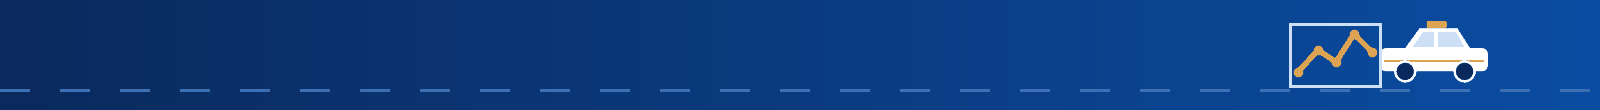

# <span style="color:#1D6FD8">Bagian 3: Visualisasi Data</span>

## <span style="color:#1D6FD8">3.1 Strategi Visualisasi</span>

<p style="line-height:1.6;">
Eksplorasi sudah mengidentifikasi pola yang layak dikomunikasikan. Jenis grafik dipilih menurut pertanyaan dan tipe variabelnya: batang untuk perbandingan kategori, histogram untuk distribusi, garis untuk tren waktu, dan heatmap untuk dua dimensi sekaligus. Setiap grafik menjawab satu pertanyaan bisnis dan memakai angka dari Bagian 1–2. Seluruh grafik juga disimpan sebagai PNG di <code>databasegpt/charts/</code>.
</p>

| Warna | Makna |
|---|---|
| **Oranye** | Request gagal (masalah yang perlu diperhatikan) |
| **Biru** | Seri utama |
| **Abu-abu** | Pembanding atau kategori lain |

In [155]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# One place for colours and style, so all charts look the same.
COLOR_MAIN = "#0b4da2"      # deep Bluebird blue: normal / main series
COLOR_PROBLEM = "#eb6834"   # orange: failures, the issue to look at
COLOR_NEUTRAL = "#b7c0ca"   # cool grey: reference / other
COLOR_TEXT = "#1f2933"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8896a6",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.labelcolor": COLOR_TEXT,
    "xtick.color": COLOR_TEXT,
    "ytick.color": COLOR_TEXT,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e3e9f0",
})

charts_dir = output_dir / "charts"
charts_dir.mkdir(parents=True, exist_ok=True)

def save_chart(fig, name):
    """Save the figure as PNG (for the presentation) and show it in the notebook."""
    fig.savefig(charts_dir / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {charts_dir / (name + '.png')}")

hour_labels = [f"{h:02d}" for h in range(24)]

## <span style="color:#1D6FD8">3.2 Pola Permintaan dan Layanan</span>

<p style="line-height:1.6;">
Grafik pertama menunjukkan pola permintaan serta cara pelanggan memesan dan membayar, sebagai latar sebelum kegagalan dibahas.
</p>

### <span style="color:#1D6FD8">3.2.1 Apakah Street Hail Terjadi pada Jam Berbeda?</span>

<p style="line-height:1.6;">
Setiap garis menunjukkan porsi trip suatu channel pada tiap jam.
</p>

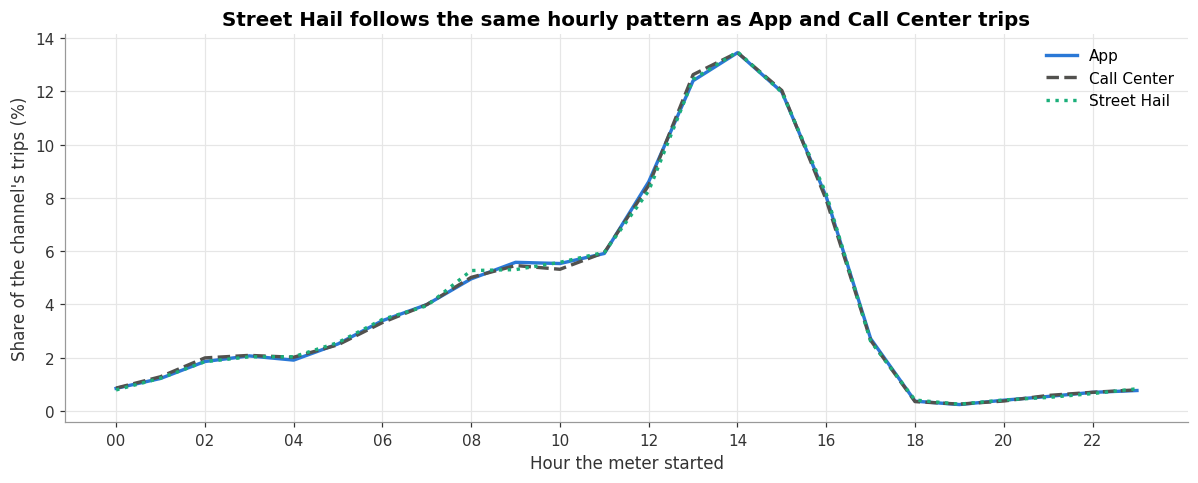

Saved: databasegpt\charts\v13_channel_hour_profile.png


In [156]:
fig, ax = plt.subplots(figsize=(11, 4.5))
line_styles = {"App": (COLOR_MAIN, "-"), "Call Center": ("#52514e", "--"), "Street Hail": ("#1baf7a", ":")}
for channel, (color, style) in line_styles.items():
    ax.plot(channel_hour_share.index, channel_hour_share[channel], color=color, linestyle=style, linewidth=2.2, label=channel)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(hour_labels[::2])
ax.set_xlabel("Hour the meter started")
ax.set_ylabel("Share of the channel's trips (%)")
ax.set_title("Street Hail follows the same hourly pattern as App and Call Center trips")
ax.legend(frameon=False)
fig.tight_layout()
save_chart(fig, "v13_channel_hour_profile")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Ketiga garis hampir berhimpit, dan semua channel memuncak pukul 13–15. Street Hail bukan permintaan dengan pola jam yang berbeda.
</div>

### <span style="color:#1D6FD8">3.2.2 Cara Bayar per Channel</span>

<p style="line-height:1.6;">
Setiap batang mewakili 100% trip pada channel tersebut.
</p>

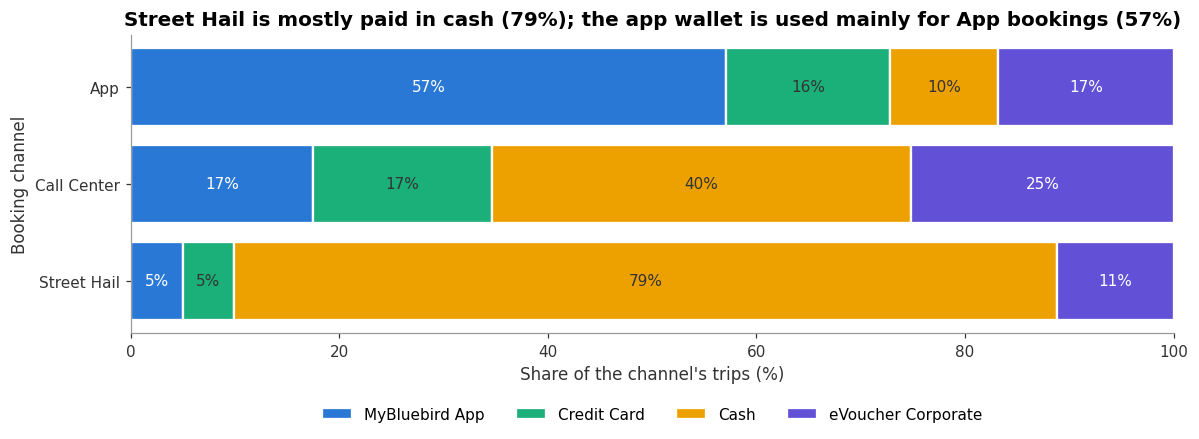

Saved: databasegpt\charts\v12_channel_payment_mix.png


In [157]:
payment_order = ["MyBluebird App", "Credit Card", "Cash", "eVoucher Corporate"]       # same order in every bar
payment_colors = {"MyBluebird App": "#2a78d6", "Credit Card": "#1baf7a", "Cash": "#eda100", "eVoucher Corporate": "#6250d6"}
label_colors = {"MyBluebird App": "white", "Credit Card": COLOR_TEXT, "Cash": COLOR_TEXT, "eVoucher Corporate": "white"}
channel_order = ["Street Hail", "Call Center", "App"]

fig, ax = plt.subplots(figsize=(11, 4.2))
left = np.zeros(len(channel_order))
for payment in payment_order:
    values = channel_payment_mix.loc[channel_order, payment].to_numpy()
    ax.barh(channel_order, values, left=left, color=payment_colors[payment], edgecolor="white", linewidth=1.5, label=payment)
    for i, v in enumerate(values):          # write the % inside each segment that is wide enough
        if v >= 4:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=10, color=label_colors[payment])
    left += values
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the channel's trips (%)")
ax.set_ylabel("Booking channel")
ax.set_title("Street Hail is mostly paid in cash (79%); the app wallet is used mainly for App bookings (57%)")
ax.grid(False)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
save_chart(fig, "v12_channel_payment_mix")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Street Hail 79% dibayar tunai. Call Center paling bervariasi (40% tunai, 25% eVoucher, 17,5% MyBluebird App). eVoucher dipakai di ketiga channel (17% App, 25% Call Center, 11% Street Hail), dengan porsi tertinggi di Call Center.
</div>

## <span style="color:#1D6FD8">3.3 Distribusi Trip dan Tarif</span>

<p style="line-height:1.6;">
Distribusi jarak dan tarif ditinjau untuk memastikan data meter dapat dipercaya, lalu untuk menilai tarif trip eVoucher.
</p>

### <span style="color:#1D6FD8">3.3.1 Apakah Data Meter yang Buruk Berpengaruh?</span>

<p style="line-height:1.6;">
Rata-rata jarak dibandingkan dengan dan tanpa flag, untuk melihat seberapa jauh jarak terlalu tinggi jika data tidak dibersihkan.
</p>

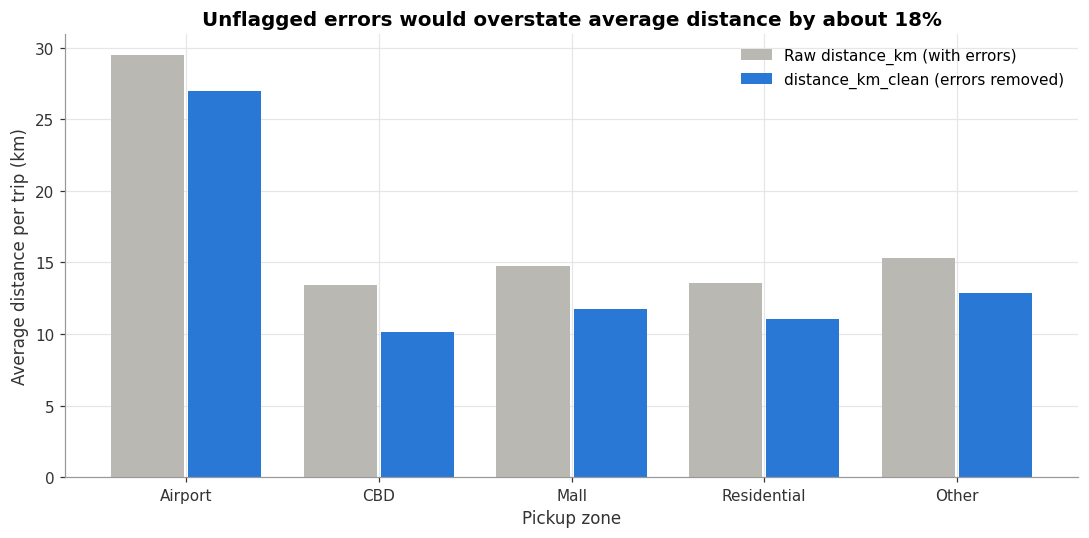

Saved: databasegpt\charts\v10_data_quality_impact.png


In [158]:
quality_zone = distance_by_zone.loc[["Airport", "CBD", "Mall", "Residential", "Other"]]

fig, ax = plt.subplots(figsize=(10, 5))
x_positions = np.arange(len(quality_zone))
ax.bar(x_positions - 0.2, quality_zone["distance_km"], width=0.38, color=COLOR_NEUTRAL, label="Raw distance_km (with errors)")
ax.bar(x_positions + 0.2, quality_zone["distance_km_clean"], width=0.38, color=COLOR_MAIN, label="distance_km_clean (errors removed)")
ax.set_xticks(x_positions)
ax.set_xticklabels(quality_zone.index)
ax.set_xlabel("Pickup zone")
ax.set_ylabel("Average distance per trip (km)")
ax.set_title(f"Unflagged errors would overstate average distance by about {abs(quality_impact.loc['Average distance, all trips (km)', 'difference_pct']):.0f}%")
ax.legend(frameon=False)
fig.tight_layout()
save_chart(fig, "v10_data_quality_impact")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Tanpa menandai jarak yang tidak andal (lebih dari 500 km atau kurang dari 1 km), rata-rata jarak menjadi terlalu tinggi di semua zona. Selisih terbesar ada di CBD (13,4 vs 10,1 km, sekitar 25% dari angka mentah) dan terkecil di Airport (29,5 vs 27,0 km). Analisis jarak, kecepatan, atau tarif per km harus memakai <code>distance_km_clean</code>.
</div>

### <span style="color:#1D6FD8">3.3.2 Zona Penjemputan dan Distribusi Tarif eVoucher</span>

<p style="line-height:1.6;">
Grafik kiri membandingkan komposisi zona penjemputan eVoucher dengan pembanding (CBD diberi garis tepi). Grafik kanan menampilkan distribusi tarif eVoucher per zona beserta batas tarif tinggi pembanding (Reguler) sebagai garis merah. Skala log dipakai karena sebaran tarif sangat miring ke kanan.
</p>

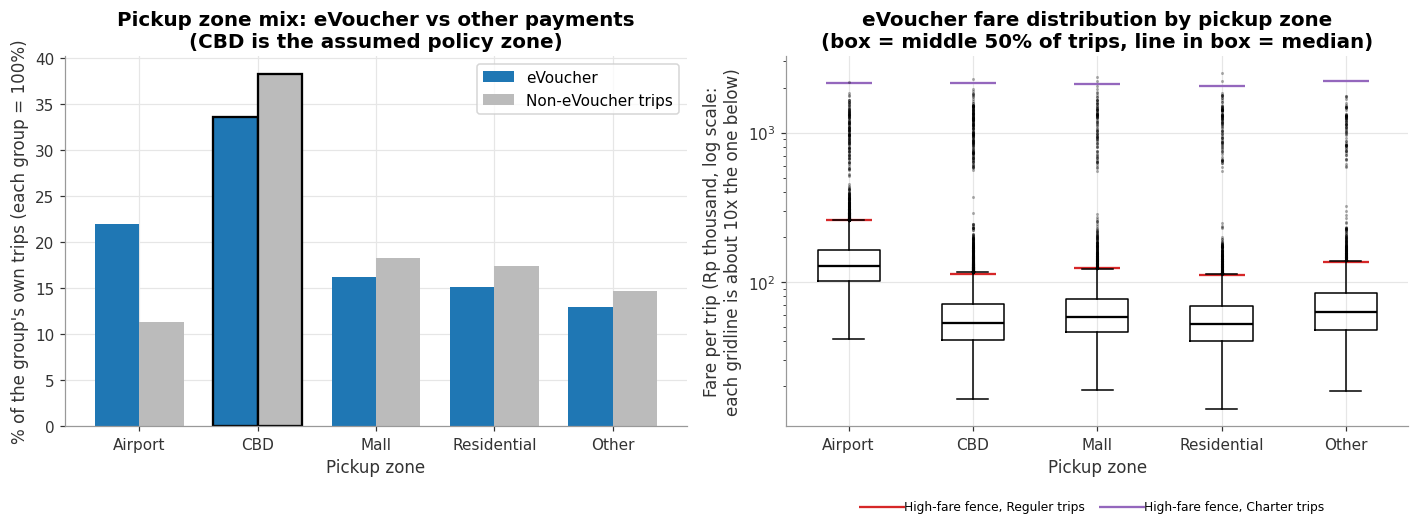

In [159]:
# 3.3.2 - Where do eVoucher trips start, and how are their fares distributed?
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 5))

zone_mix = pd.DataFrame({
    "eVoucher": ev_trips["pickup_zone_type"].value_counts(normalize=True).loc[zones_in_order] * 100,
    "Non-eVoucher trips": other_trips["pickup_zone_type"].value_counts(normalize=True).loc[zones_in_order] * 100,
})
zone_mix.plot(kind="bar", ax=ax_left, color=["#1f77b4", "#bbbbbb"], width=0.75)
ax_left.set_xlabel("Pickup zone")
ax_left.set_ylabel("% of the group's own trips (each group = 100%)")
ax_left.set_title("Pickup zone mix: eVoucher vs other payments\n(CBD is the assumed policy zone)")
ax_left.tick_params(axis="x", rotation=0)
for patch in ax_left.patches[zones_in_order.index("CBD")::len(zones_in_order)]:
    patch.set_edgecolor("black")
    patch.set_linewidth(1.5)

fare_by_zone = [ev_trips.loc[ev_trips["pickup_zone_type"] == zone, "total_fare"] / 1000 for zone in zones_in_order]
ax_right.boxplot(fare_by_zone, tick_labels=zones_in_order, showfliers=True, medianprops={"color": "black", "linewidth": 1.5}, flierprops={"marker": ".", "markersize": 2, "alpha": 0.3})
# High-fare fence = Q3 + 1.5 x IQR of the NON-eVoucher trips of the same pickup zone and trip type (see 2.6.7).
# Reguler and Charter trips have very different fares, so each trip type has its own fence.
fence_table = screen.drop_duplicates(["pickup_zone_type", "trip_type"]).set_index(["trip_type", "pickup_zone_type"])["total_fare_fence"] / 1000
zone_positions = range(1, len(zones_in_order) + 1)
ax_right.scatter(zone_positions, fence_table.loc["Reguler"].loc[zones_in_order], marker="_", s=900, color="#d62728",
                 label="High-fare fence, Reguler trips")
ax_right.scatter(zone_positions, fence_table.loc["Charter"].loc[zones_in_order], marker="_", s=900, color="#9467bd",
                 label="High-fare fence, Charter trips")
ax_right.set_yscale("log")
ax_right.set_xlabel("Pickup zone")
ax_right.set_ylabel("Fare per trip (Rp thousand, log scale:\neach gridline is about 10x the one below)")
ax_right.set_title("eVoucher fare distribution by pickup zone\n(box = middle 50% of trips, line in box = median)")
ax_right.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(output_dir / "charts" / "v22_evoucher_zone_fare.png", dpi=150, bbox_inches="tight")
plt.show()

In [160]:
# Support table for the numbers quoted below (all eVoucher trips; Non-eVoucher = Cash + Credit Card + MyBluebird App).
fare_support = pd.DataFrame({
    "eVoucher: % of trips": ev_trips["pickup_zone_type"].value_counts(normalize=True) * 100,
    "Non-eVoucher: % of trips": other_trips["pickup_zone_type"].value_counts(normalize=True) * 100,
    "eVoucher: % of eVoucher fare": ev_trips.groupby("pickup_zone_type")["total_fare"].sum() / ev_trips["total_fare"].sum() * 100,
    "eVoucher: median fare (Rp)": ev_trips.groupby("pickup_zone_type")["total_fare"].median(),
    "Non-eVoucher: median fare (Rp)": other_trips.groupby("pickup_zone_type")["total_fare"].median(),
    "fence Reguler (Rp)": screen[screen["trip_type"] == "Reguler"].drop_duplicates("pickup_zone_type").set_index("pickup_zone_type")["total_fare_fence"],
    "fence Charter (Rp)": screen[screen["trip_type"] == "Charter"].drop_duplicates("pickup_zone_type").set_index("pickup_zone_type")["total_fare_fence"],
    "eVoucher: high-fare trips": ev_trips.groupby("pickup_zone_type")["flag_high_fare"].sum(),
}).loc[zones_in_order]
display(fare_support.round(1))
print("Non-eVoucher group:", other_trips["payment_method"].value_counts().to_dict())
print("eVoucher trips by trip type:", ev_trips["trip_type"].value_counts().to_dict())

high_fare_ev = ev_trips[ev_trips["flag_high_fare"]]
print(f"High-fare eVoucher trips: {len(high_fare_ev):,} ({len(high_fare_ev) / len(ev_trips) * 100:.1f}% of eVoucher trips)")
print(f"  of which ALSO high fare per km: {int(high_fare_ev['flag_high_fare_per_km'].sum()):,}; "
      f"high fare but NOT high per km (fare follows distance): {int((~high_fare_ev['flag_high_fare_per_km']).sum()):,} "
      f"= {(~high_fare_ev['flag_high_fare_per_km']).mean() * 100:.1f}%")
print(f"  median distance: high-fare {high_fare_ev['distance_km_clean'].median():.1f} km vs other eVoucher trips "
      f"{ev_trips.loc[~ev_trips['flag_high_fare'], 'distance_km_clean'].median():.1f} km")


,eVoucher: % of trips,Non-eVoucher: % of trips,eVoucher: % of eVoucher fare,eVoucher: median fare (Rp),Non-eVoucher: median fare (Rp),fence Reguler (Rp),fence Charter (Rp),eVoucher: high-fare trips
pickup_zone_type,,,,,,,,
Airport,22.00,11.40,36.30,"128,500.00","129,500.00","258,250.00","2,161,625.00",338
CBD,33.60,38.30,25.80,"53,000.00","53,500.00","112,250.00","2,137,125.00",721
Mall,16.30,18.30,13.90,"58,500.00","59,500.00","123,500.00","2,115,750.00",288
Residential,15.20,17.40,12.20,"52,500.00","53,000.00","111,750.00","2,066,875.00",331
Other,13.00,14.70,11.70,"63,000.00","63,000.00","135,500.00","2,215,875.00",244


Non-eVoucher group: {'MyBluebird App': 122426, 'Cash': 87681, 'Credit Card': 44818}
eVoucher trips by trip type: {'Reguler': 55452, 'Charter': 630}
High-fare eVoucher trips: 1,922 (3.4% of eVoucher trips)
  of which ALSO high fare per km: 181; high fare but NOT high per km (fare follows distance): 1,741 = 90.6%
  median distance: high-fare 20.4 km vs other eVoucher trips 9.1 km


<div style="border-left:5px solid #6B7C8F; background:#F0F3F6; color:#1F2933; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Cara membaca angka.</strong> <em>Non-eVoucher</em> (pada grafik dan tabel sebelumnya disebut pembanding Non-B2B) adalah seluruh 254.925 trip yang dibayar Cash, Credit Card, atau MyBluebird App; pada data ini trip ber-<code>company_id</code> persis sama dengan trip eVoucher. Persentase zona pada grafik kiri dihitung di dalam masing-masing kelompok (tiap kelompok = 100%).<br><br>Median tarif adalah nilai tengah tarif trip pada zona itu (separuh trip lebih murah, separuh lebih mahal): eVoucher Airport Rp128.500, sedangkan zona lain Rp52.500 (Residential) sampai Rp63.000 (Other), dengan CBD Rp53.000 dan Mall Rp58.500. Airport menyumbang 36,3% nilai tarif eVoucher (Rp1,83 miliar dari Rp5,04 miliar) dari 22,0% trip eVoucher (12.343 dari 56.082).<br><br>Garis merah dan ungu adalah <em>batas tarif tinggi</em>: kuartil ketiga + 1,5 × rentang interkuartil (IQR) dari trip non-eVoucher pada zona dan tipe trip yang sama. Reguler (merah) dan Charter (ungu) punya batas sendiri karena tarif Charter jauh lebih tinggi (sekitar Rp2,1 juta). Pada skala log, setiap garis grid bernilai sekitar 10 kali garis di bawahnya.
</div>

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> eVoucher lebih banyak dijemput di Airport (22,0% vs 11,4%) dan lebih sedikit di CBD (33,6% vs 38,3%); zona lain mirip. Median tarif Airport hampir sama pada trip non-eVoucher (Rp129.500 vs Rp128.500), sehingga tarif tinggi adalah ciri zona Airport dan bukan ciri eVoucher. Itu sebabnya Airport menyumbang porsi tarif yang lebih besar daripada porsi trip.<br><br>Hanya 3,4% trip eVoucher (1.922) melewati batas tarif tinggi, hampir sama dengan 3,5% pada non-eVoucher. Dari 1.922 trip itu, sekitar 91% tidak tinggi per kilometer (tarif sejalan dengan jarak; median jarak 20,4 km vs 9,1 km pada trip lain). Trip di atas batas adalah <strong>kandidat tinjauan</strong>, bukan bukti pelanggaran; titik Charter di atas garis merah tidak dihitung karena batas Charter adalah garis ungu.<br><br><strong>Batasan:</strong> non-eVoucher adalah pembanding yang tidak sempurna (pelanggan berbeda, bukan perjalanan dinas), dan tidak ada zona tujuan, sehingga grafik hanya menggambarkan titik jemput.
</div>

## <span style="color:#1D6FD8">3.4 Request dan Kinerja Operasional</span>

<p style="line-height:1.6;">
Inti brief: kapan dan di mana request gagal, apakah pasokan pengemudi menjelaskannya, dan apakah ritase benar-benar menurun.
</p>

### <span style="color:#1D6FD8">3.4.1 Kapan Request Gagal?</span>

<p style="line-height:1.6;">
Panel atas menunjukkan jumlah request per jam (penyebut), dan panel bawah menunjukkan proporsi gagal per jam. Tujuannya melihat apakah kegagalan hanya akibat jam yang paling ramai.
</p>

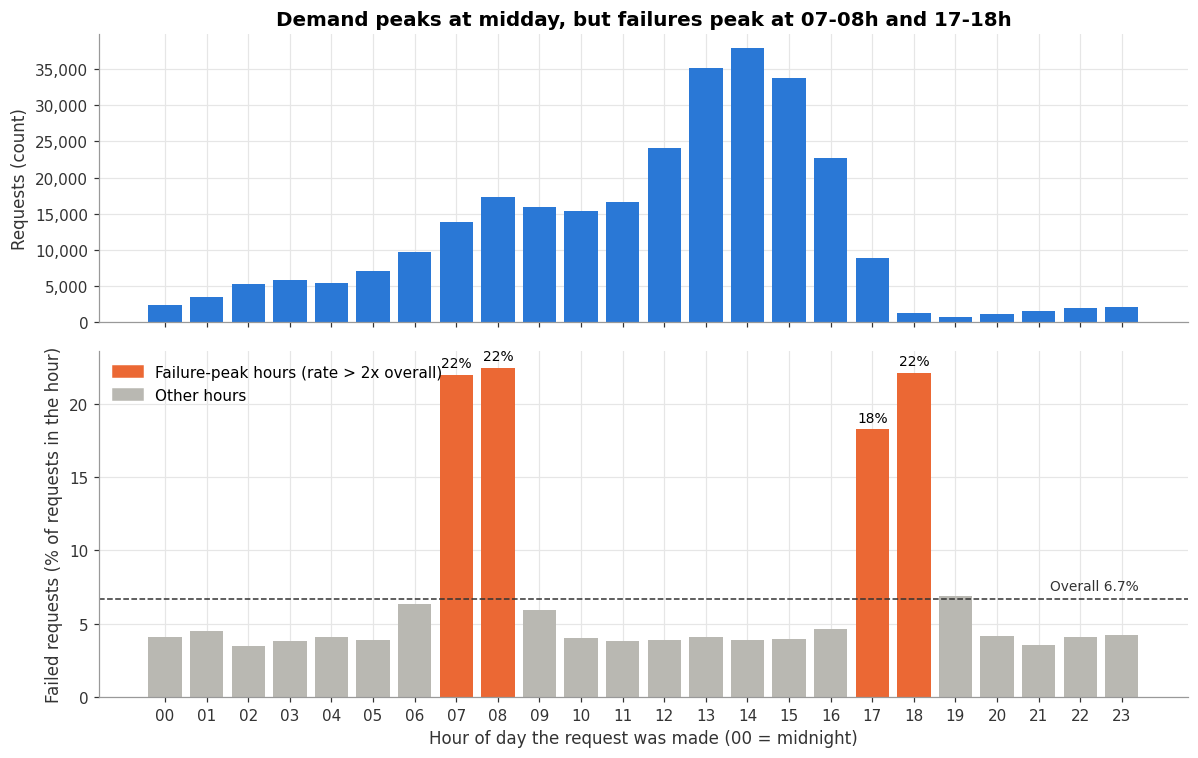

Saved: databasegpt\charts\v1_failure_by_hour.png


In [161]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})

hours = by_hour.index
is_peak = hours.isin(failure_peak_hours)

ax_top.bar(hours, by_hour["requests"], color=COLOR_MAIN)
ax_top.set_ylabel("Requests (count)")
ax_top.set_title("Demand peaks at midday, but failures peak at 07-08h and 17-18h")
ax_top.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax_bottom.bar(hours, by_hour["failed_pct"], color=[COLOR_PROBLEM if p else COLOR_NEUTRAL for p in is_peak])
ax_bottom.axhline(overall_failed_pct, color=COLOR_TEXT, linestyle="--", linewidth=1)
ax_bottom.text(23.4, overall_failed_pct + 0.6, f"Overall {overall_failed_pct:.1f}%", ha="right", fontsize=9, color=COLOR_TEXT)
for h in failure_peak_hours:
    ax_bottom.text(h, by_hour.loc[h, "failed_pct"] + 0.5, f"{by_hour.loc[h, 'failed_pct']:.0f}%", ha="center", fontsize=9)
ax_bottom.set_ylabel("Failed requests (% of requests in the hour)")
ax_bottom.set_xlabel("Hour of day the request was made (00 = midnight)")
ax_bottom.set_xticks(range(24))
ax_bottom.set_xticklabels(hour_labels)
ax_bottom.legend(handles=[Patch(color=COLOR_PROBLEM, label="Failure-peak hours (rate > 2x overall)"),
                          Patch(color=COLOR_NEUTRAL, label="Other hours")], loc="upper left", frameon=False)
fig.tight_layout()
save_chart(fig, "v1_failure_by_hour")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Jam tersibuk (12–16) hanya gagal sekitar 4%, sedangkan pukul 07, 08, 17, dan 18 melonjak ke 22%, 22%, 18%, dan 22%. Keempat jam ini hanya 14,3% request, tetapi 45,6% kegagalan. Kegagalan terkait jam tertentu, bukan sekadar banyaknya request. Pukul 18 hanya memiliki 1.258 request, sehingga angka 22% bertumpu pada basis yang kecil.
</div>

### <span style="color:#1D6FD8">3.4.2 Heatmap Zona × Jam</span>

<p style="line-height:1.6;">
Heatmap dipilih karena membandingkan dua dimensi sekaligus. Setiap sel adalah request gagal dibagi seluruh request pada zona dan jam tersebut.
</p>

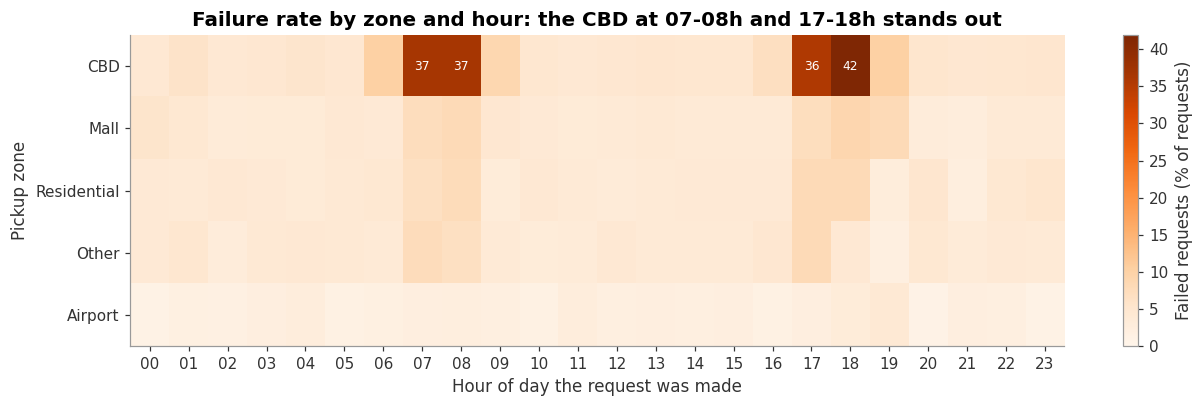

Saved: databasegpt\charts\v2_heatmap_zone_hour.png


In [162]:
heat = req.pivot_table(index="pickup_zone_type", columns="hour", values="is_failed", aggfunc="mean") * 100
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]      # worst zone on top

fig, ax = plt.subplots(figsize=(12, 3.8))
image = ax.imshow(heat.values, aspect="auto", cmap="Oranges", vmin=0)
ax.set_xticks(range(24))
ax.set_xticklabels(hour_labels)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
ax.set_xlabel("Hour of day the request was made")
ax.set_ylabel("Pickup zone")
ax.set_title("Failure rate by zone and hour: the CBD at 07-08h and 17-18h stands out")
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Failed requests (% of requests)")
# Write the number only in the very high cells, so the chart stays readable.
for row in range(heat.shape[0]):
    for col in range(heat.shape[1]):
        if heat.iat[row, col] >= 20:
            ax.text(col, row, f"{heat.iat[row, col]:.0f}", ha="center", va="center", fontsize=8, color="white")
fig.tight_layout()
save_chart(fig, "v2_heatmap_zone_hour")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Hanya CBD yang memiliki pita gelap: 36–42% request gagal pada pukul 07, 08, 17, dan 18. Mall, Residential, dan Other naik hanya ke sekitar 7–8%, dan Airport tetap sekitar 4% atau kurang. Masalahnya ada pada CBD saat jam sibuk, bukan pada Airport. CBD pukul 18 (42%) bertumpu pada hanya 554 request.
</div>

### <span style="color:#1D6FD8">3.4.3 CBD, Jam, atau Keduanya?</span>

<p style="line-height:1.6;">
Tingkat kegagalan dibandingkan antar zona dan periode. Jam puncak kegagalan = 07, 08, 17, 18; jam puncak permintaan = 12–16.
</p>

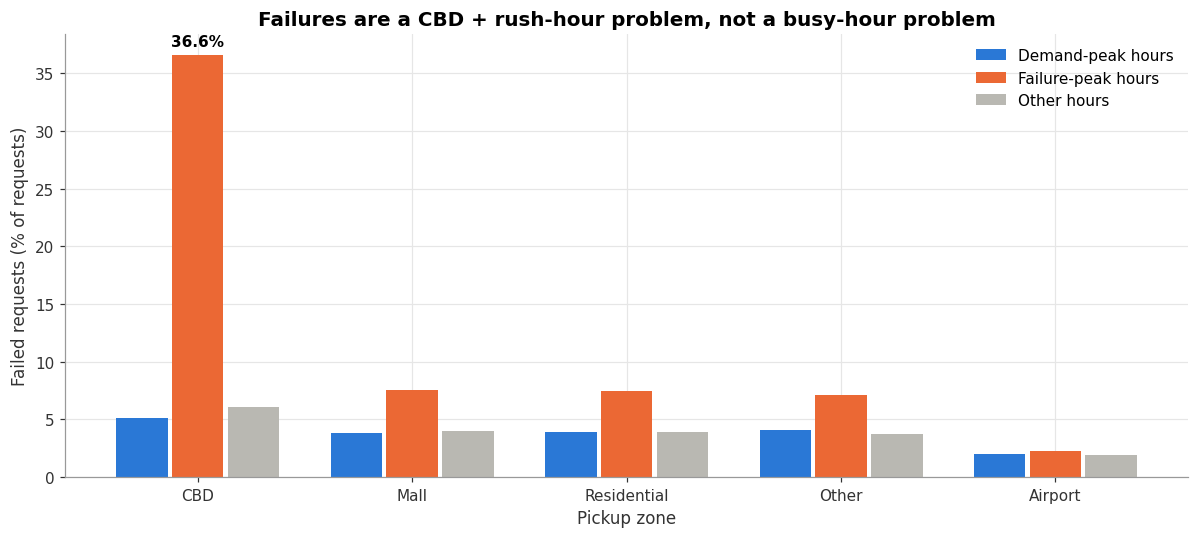

Saved: databasegpt\charts\v3_zone_by_period.png


In [163]:
period_order = ["Demand-peak hours", "Failure-peak hours", "Other hours"]
period_colors = {"Demand-peak hours": COLOR_MAIN, "Failure-peak hours": COLOR_PROBLEM, "Other hours": COLOR_NEUTRAL}
zone_order = list(zone_by_period.mean(axis=1).sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(11, 5))
bar_width = 0.26
x_positions = np.arange(len(zone_order))
for i, period in enumerate(period_order):
    values = zone_by_period.loc[zone_order, period]
    ax.bar(x_positions + (i - 1) * bar_width, values, width=bar_width - 0.02, color=period_colors[period], label=period)
cbd_x = zone_order.index("CBD") + 0.0 * bar_width
ax.text(cbd_x, zone_by_period.loc["CBD", "Failure-peak hours"] + 0.8,
        f"{zone_by_period.loc['CBD', 'Failure-peak hours']:.1f}%", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(x_positions)
ax.set_xticklabels(zone_order)
ax.set_xlabel("Pickup zone")
ax.set_ylabel("Failed requests (% of requests)")
ax.set_title("Failures are a CBD + rush-hour problem, not a busy-hour problem")
ax.legend(frameon=False)
fig.tight_layout()
save_chart(fig, "v3_zone_by_period")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Request CBD pada jam puncak kegagalan gagal 36,6%, dibanding 5,1% pada jam puncak permintaan dan 6,1% pada jam lain. Request ini 7,1% dari total, tetapi memuat 38,5% kegagalan (odds ratio sekitar 12). Jika manajemen ingin menurunkan kegagalan, CBD pada keempat jam tersebut adalah titik terbesar.
</div>

### <span style="color:#1D6FD8">3.4.4 Ketersediaan Pengemudi per Jam</span>

<p style="line-height:1.6;">
Garis jumlah pengemudi bertugas disandingkan dengan tingkat kegagalan per jam, untuk melihat apakah pasokan sejalan dengan kegagalan (rata-rata hari penuh).
</p>

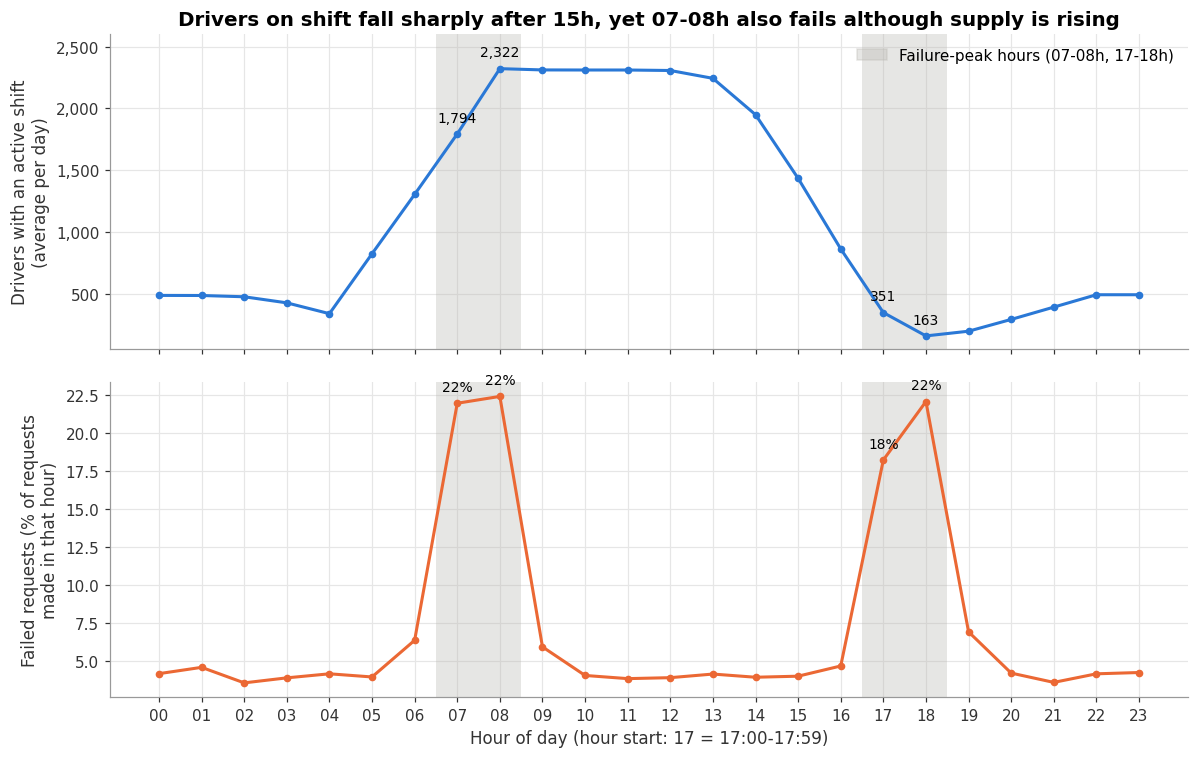

Saved: databasegpt\charts\v4_supply_vs_failure.png


In [164]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax_top.plot(supply_demand.index, supply_demand["drivers_on_shift"], color=COLOR_MAIN, linewidth=2, marker="o", markersize=4)
ax_top.set_ylim(top=supply_demand["drivers_on_shift"].max() * 1.12)
ax_top.set_ylabel("Drivers with an active shift\n(average per day)")
ax_top.set_title("Drivers on shift fall sharply after 15h, yet 07-08h also fails although supply is rising")
ax_top.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax_bottom.plot(supply_demand.index, supply_demand["failed_pct"], color=COLOR_PROBLEM, linewidth=2, marker="o", markersize=4)
ax_bottom.set_ylabel("Failed requests (% of requests\nmade in that hour)")
ax_bottom.set_xlabel("Hour of day (hour start: 17 = 17:00-17:59)")
ax_bottom.set_xticks(range(24))
ax_bottom.set_xticklabels(hour_labels)

# Direct labels only for the hours quoted in the interpretation (07, 08, 17, 18).
for h in failure_peak_hours:
    ax_top.annotate(f"{supply_demand.loc[h, 'drivers_on_shift']:,.0f}", (h, supply_demand.loc[h, "drivers_on_shift"]),
                    textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
    ax_bottom.annotate(f"{supply_demand.loc[h, 'failed_pct']:.0f}%", (h, supply_demand.loc[h, "failed_pct"]),
                       textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

for axis in (ax_top, ax_bottom):          # grey bands mark the four failure-peak hours on both panels
    for h in failure_peak_hours:
        axis.axvspan(h - 0.5, h + 0.5, color=COLOR_NEUTRAL, alpha=0.35, linewidth=0)
ax_top.legend(handles=[Patch(color=COLOR_NEUTRAL, alpha=0.35, label="Failure-peak hours (07-08h, 17-18h)")],
              loc="upper right", frameon=False)
fig.tight_layout()
save_chart(fig, "v4_supply_vs_failure")

In [165]:
# Support table: where the numbers quoted below come from (hours 07, 08, 17, 18).
# Both panels use the 90 full days (2023-10-01 to 2023-12-29). Hour = hour the request was made / hour the shift was active.
key_hours = [7, 8, 17, 18]
requests_by_hour = full_days_req.groupby("hour").size()
failed_by_hour = full_days_req.groupby("hour")["is_failed"].sum()      # failed = Cancelled-No Driver + Cancelled-Timeout

support_table = pd.DataFrame({
    "requests (90 days)": requests_by_hour,
    "failed requests (90 days)": failed_by_hour,
    "failed % = failed / requests": failed_by_hour / requests_by_hour * 100,
    "drivers with an active shift (avg per day)": supply_demand["drivers_on_shift"],
    "drivers, time-weighted (avg per day, 2.5.10)": utilisation_by_hour["drivers_on_shift"],
    "CBD requests per CBD driver (2.5.1)": cbd_supply_demand["cbd_requests_per_driver"],
}).loc[key_hours]
assert np.allclose(support_table["failed % = failed / requests"], supply_demand.loc[key_hours, "failed_pct"])   # same as the chart
display(support_table.round(2))
print("Average drivers with an active shift, 08-12h:", round(supply_demand.loc[8:12, "drivers_on_shift"].mean()))


,requests (90 days),failed requests (90 days),failed % = failed / requests,drivers with an active shift (avg per day),"drivers, time-weighted (avg per day, 2.5.10)",CBD requests per CBD driver (2.5.1)
7,13817,3038,21.99,"1,794.39","1,480.46",0.14
8,17341,3891,22.44,"2,321.58","2,030.91",0.14
17,8917,1627,18.25,351.02,183.33,0.36
18,1258,278,22.10,162.57,72.88,0.13


Average drivers with an active shift, 08-12h: 2312


<div style="border-left:5px solid #6B7C8F; background:#F0F3F6; color:#1F2933; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Cara membaca angka.</strong> Panel atas: jumlah shift yang aktif (sebagian atau seluruhnya) pada jam itu, dirata-rata atas 90 hari penuh. Panel bawah: request gagal (Cancelled-No Driver + Cancelled-Timeout) dibagi seluruh request yang dibuat pada jam itu, dijumlahkan atas 90 hari. Contoh: pukul 17 ada 1.627 request gagal dari 8.917 request = 18,2%. Pukul 07 dan 08 gagal 22,0% dan 22,4%; pukul 18 gagal 22,1% tetapi hanya dari 1.258 request. Label jam adalah awal jam (17 = 17:00–17:59).
</div>

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Jumlah shift aktif turun dari sekitar 2.300 (08–12) menjadi 351 pada pukul 17 dan 163 pada pukul 18, karena sebagian besar shift pagi berakhir antara pukul 13 dan 17 (puncak clock-out 14–16), sedangkan shift sore baru mulai pukul 18–22. Pada 07–08 jumlah shift aktif sedang naik (1.794 ke 2.322), tetapi sekitar 22% request tetap gagal, sehingga alasan "kekurangan pengemudi" tidak cocok untuk pagi hari.<br><br>Pada pukul 17, CBD memiliki request per pengemudi tertinggi dari 24 jam: 39,6 request per jam dibagi 109,5 shift berzona dominan CBD yang aktif = 0,36 (rata-rata semua zona 0,28), yang sesuai dengan celah pergantian shift. <strong>Catatan:</strong> angka 351 menghitung shift yang hanya aktif sebagian jam 17; jika dihitung menurut menit tugas, rata-rata pengemudi pada pukul 17 hanya sekitar 183 (grafik 3.4.6).<br><br>Korelasi antar-jam di CBD antara request per pengemudi dan tingkat kegagalan hanya 0,21, dan pada 07–08 CBD gagal 36,6% dengan rasio hanya 0,14. Jadi pasokan paling masuk akal menjelaskan puncak sore, bukan pagi. Ini <strong>hipotesis</strong>: data tidak menunjukkan di mana setiap pengemudi berada saat request masuk, sehingga jumlah agregat tidak membuktikan kekurangan lokal.
</div>

### <span style="color:#1D6FD8">3.4.5 Ritase dan Tingkat Kegagalan Mingguan</span>

<p style="line-height:1.6;">
Grafik garis waktu dipilih untuk melihat tren mingguan.
</p>

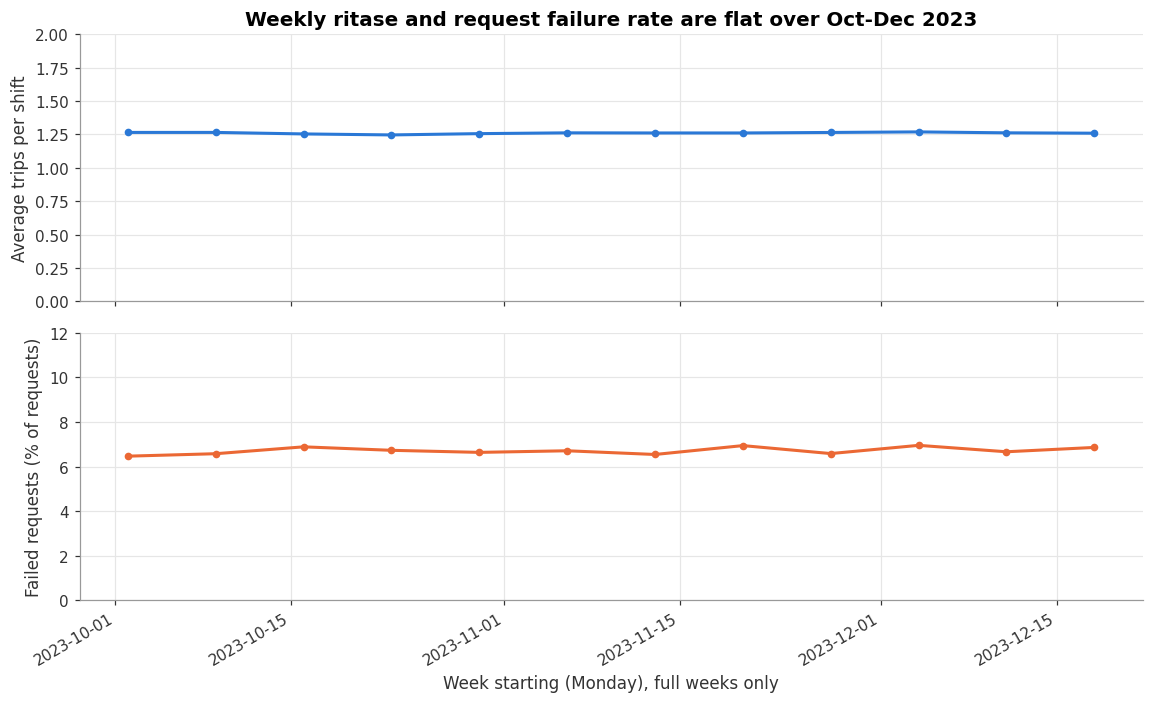

Saved: databasegpt\charts\v15_weekly_trend.png


In [166]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(10.5, 6.5), sharex=True)
ax_top.plot(weekly.index, weekly["avg_trips_per_shift"], color=COLOR_MAIN, linewidth=2, marker="o", markersize=4)
ax_top.set_ylim(0, 2)
ax_top.set_ylabel("Average trips per shift")
ax_top.set_title("Weekly ritase and request failure rate are flat over Oct-Dec 2023")
ax_bottom.plot(weekly.index, weekly["request_failure_pct"], color=COLOR_PROBLEM, linewidth=2, marker="o", markersize=4)
ax_bottom.set_ylim(0, 12)
ax_bottom.set_ylabel("Failed requests (% of requests)")
ax_bottom.set_xlabel("Week starting (Monday), full weeks only")
fig.autofmt_xdate()
fig.tight_layout()
save_chart(fig, "v15_weekly_trend")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Selama 12 minggu penuh, ritase rata-rata berada di 1,25–1,27 trip per shift dan porsi shift tanpa trip di 30,1–31,3%. Kegagalan mingguan 6,5–7,0%. Tidak tampak penurunan ritase pada Oktober–Desember 2023, sehingga dugaan penurunan dalam brief tidak dapat dikonfirmasi dengan data tiga bulan. Masalahnya adalah <strong>level yang rendah</strong> (1,26 trip per driver-day), bukan penurunan yang terukur.
</div>

### <span style="color:#1D6FD8">3.4.6 Pengemudi Bertugas vs Sibuk, dan Utilisasi vs Kegagalan</span>

<p style="line-height:1.6;">
Area pengemudi bertugas dibandingkan dengan pengemudi sibuk per jam, lengkap dengan garis kegagalan, untuk melihat apakah request gagal karena semua pengemudi sedang sibuk.
</p>

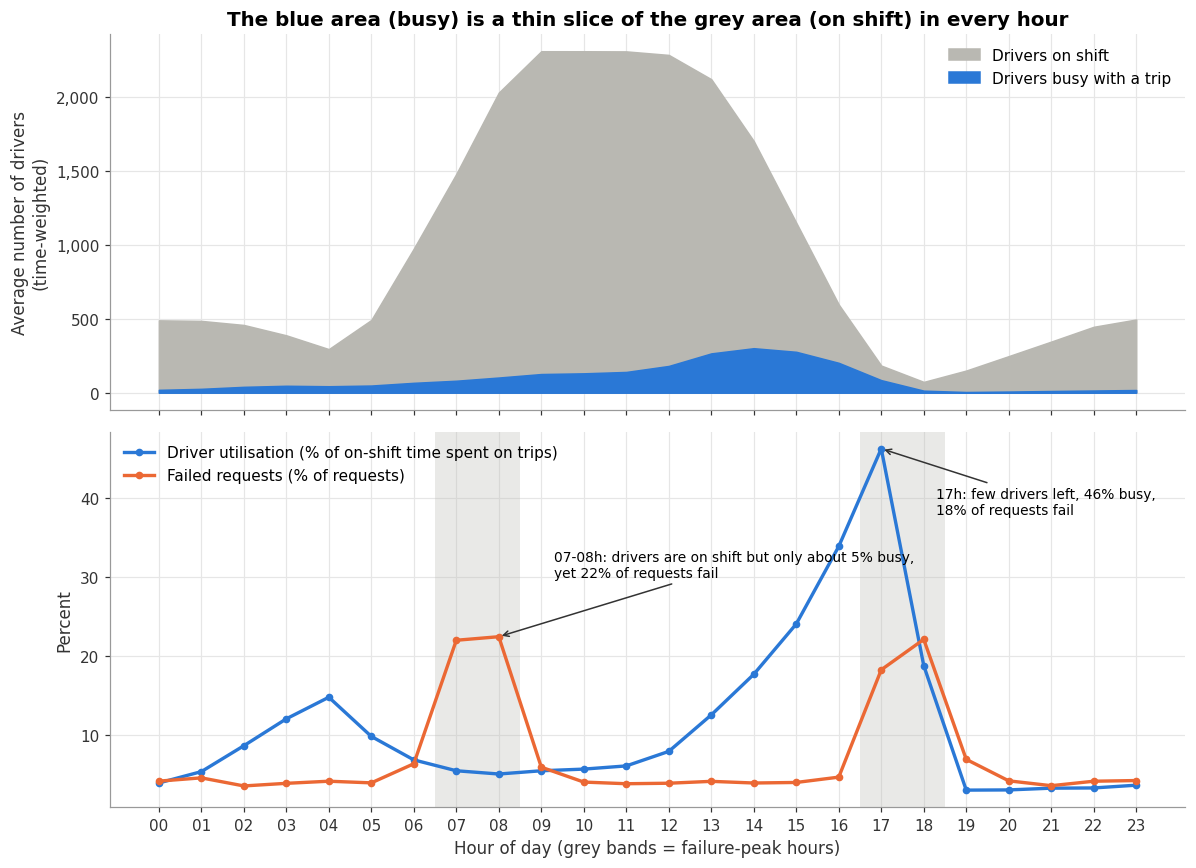

Saved: databasegpt\charts\v17_capacity_vs_demand.png


In [167]:
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
hours_axis = utilisation_by_hour.index

ax_top.fill_between(hours_axis, utilisation_by_hour["drivers_on_shift"], color=COLOR_NEUTRAL, label="Drivers on shift")
ax_top.fill_between(hours_axis, utilisation_by_hour["drivers_busy"], color=COLOR_MAIN, label="Drivers busy with a trip")
ax_top.set_ylabel("Average number of drivers\n(time-weighted)")
ax_top.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax_top.set_title("The blue area (busy) is a thin slice of the grey area (on shift) in every hour")
ax_top.legend(frameon=False, loc="upper right")

ax_bottom.plot(hours_axis, utilisation_by_hour["utilisation_pct"], color=COLOR_MAIN, linewidth=2.2, marker="o", markersize=4,
               label="Driver utilisation (% of on-shift time spent on trips)")
ax_bottom.plot(hours_axis, utilisation_by_hour["failed_pct"], color=COLOR_PROBLEM, linewidth=2.2, marker="o", markersize=4,
               label="Failed requests (% of requests)")
for h in failure_peak_hours:
    ax_bottom.axvspan(h - 0.5, h + 0.5, color=COLOR_NEUTRAL, alpha=0.3, linewidth=0)
ax_bottom.annotate(f"07-08h: drivers are on shift but only about {utilisation_by_hour.loc[7:8, 'utilisation_pct'].mean():.0f}% busy,\nyet {utilisation_by_hour.loc[7:8, 'failed_pct'].mean():.0f}% of requests fail",
                   xy=(8, utilisation_by_hour.loc[8, "failed_pct"]), xytext=(9.3, 30), fontsize=9,
                   arrowprops={"arrowstyle": "->", "color": COLOR_TEXT})
ax_bottom.annotate(f"17h: few drivers left, {utilisation_by_hour.loc[17, 'utilisation_pct']:.0f}% busy,\n{utilisation_by_hour.loc[17, 'failed_pct']:.0f}% of requests fail",
                   xy=(17, utilisation_by_hour.loc[17, "utilisation_pct"]), xytext=(18.3, 38), fontsize=9,
                   arrowprops={"arrowstyle": "->", "color": COLOR_TEXT})
ax_bottom.set_ylabel("Percent")
ax_bottom.set_xlabel("Hour of day (grey bands = failure-peak hours)")
ax_bottom.set_xticks(range(24))
ax_bottom.set_xticklabels(hour_labels)
ax_bottom.legend(frameon=False, loc="upper left")
fig.tight_layout()
save_chart(fig, "v17_capacity_vs_demand")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Area pengemudi bertugas jauh lebih besar daripada pengemudi sibuk di setiap jam. (Utilisasi = menit pengemudi dalam trip dibagi menit pengemudi bertugas pada jam itu. Jumlah pengemudi di sini dihitung menurut menit tugas, sehingga lebih kecil daripada hitungan shift aktif di 3.4.4, mis. 183 vs 351 pada pukul 17.)<br><br>Dua puncak kegagalan berbeda sifatnya: pada 07–08 kegagalan melonjak saat utilisasi sekitar 5%, sedangkan pada 17:00 kegagalan naik bersama utilisasi 46%. Puncak pagi tampak sebagai masalah <strong>posisi atau awal shift</strong>, sedangkan puncak sore sebagai <strong>celah pasokan nyata</strong>. Satu tindakan saja tidak akan memperbaiki keduanya.
</div>

### <span style="color:#1D6FD8">3.4.7 Di Mana Idle Time Terkonsentrasi? Utilisasi per Zona dan Jam</span>

<p style="line-height:1.6;">
Setiap sel adalah menit sibuk dibagi menit bertugas pada zona dan jam tersebut.
</p>

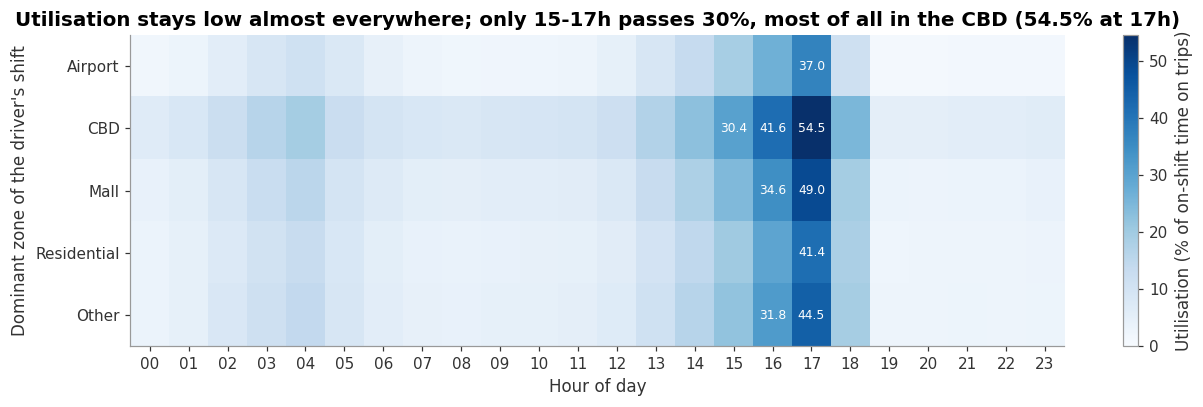

Saved: databasegpt\charts\v18_utilisation_heatmap.png


In [168]:
heat_util = zone_hour_utilisation.loc[zones_in_order]
fig, ax = plt.subplots(figsize=(12, 3.8))
image = ax.imshow(heat_util.values, aspect="auto", cmap="Blues", vmin=0)
ax.set_xticks(range(24))
ax.set_xticklabels(hour_labels)
ax.set_yticks(range(len(heat_util.index)))
ax.set_yticklabels(heat_util.index)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Dominant zone of the driver's shift")
ax.set_title(f"Utilisation stays low almost everywhere; only 15-17h passes 30%, most of all in the CBD ({heat_util.loc['CBD', 17]:.1f}% at 17h)")
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Utilisation (% of on-shift time on trips)")
for row in range(heat_util.shape[0]):
    for col in range(heat_util.shape[1]):
        if heat_util.iat[row, col] >= 30:
            ax.text(col, row, f"{heat_util.iat[row, col]:.1f}", ha="center", va="center", fontsize=8, color="white")
fig.tight_layout()
save_chart(fig, "v18_utilisation_heatmap")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Pengemudi paling jarang terpakai pada malam dan pagi hari di setiap zona. Angka hanya ditulis pada sel dengan utilisasi minimal 30%, dan zona di sini adalah zona dominan shift pengemudi, bukan lokasi trip. Sel tergelap adalah pukul 16–17 di CBD (42% dan 54,5%), Mall (35% dan 49%), dan Other (32% dan 44,5%). Airport memiliki utilisasi harian terendah (5,9%) dan hanya 37% pada pukul 17:00. Kapasitas idle terutama ada di pagi hari dan di Airport, sedangkan titik tersibuk ada di CBD pukul 16–17.
</div>

## <span style="color:#1D6FD8">3.5 Pengemudi, Shift, dan Penggunaan Korporat</span>

<p style="line-height:1.6;">
Bagian ini memvisualisasikan utilisasi pengemudi, perbedaan antar pool, penyebab idle, dan pemakaian eVoucher korporat.
</p>

### <span style="color:#1D6FD8">3.5.1 Ritase per Pengemudi per Hari</span>

<p style="line-height:1.6;">
Histogram dipilih untuk menampilkan distribusi jumlah trip per shift. Unit analisis: satu shift (= satu driver-day, lihat 2.5.4). Target 6 trip adalah asumsi.
</p>

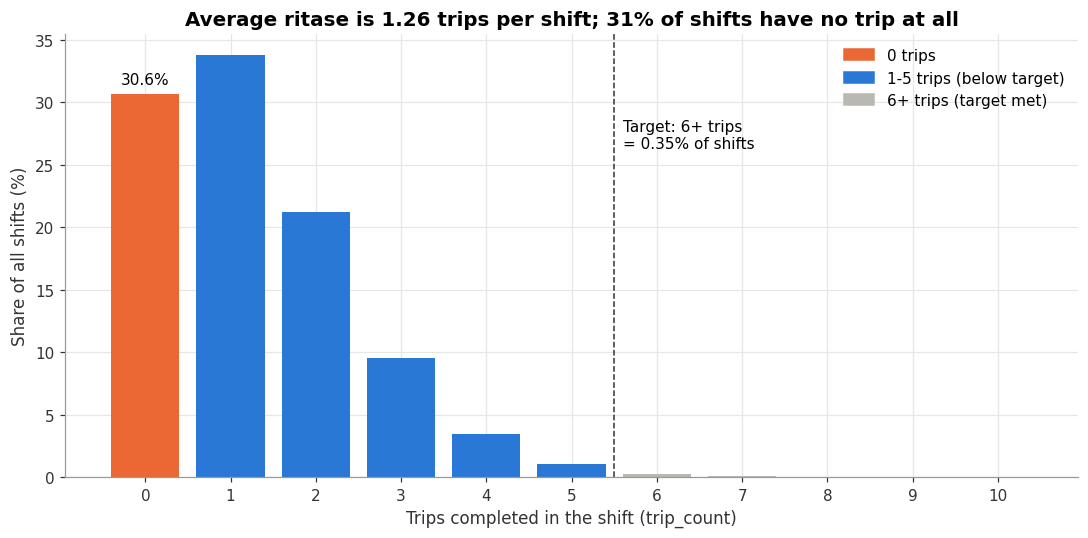

Saved: databasegpt\charts\v5_trips_per_shift.png


In [169]:
trip_count_share = shifts_eda["trip_count"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(10, 5))
bar_colors = [COLOR_PROBLEM if count == 0 else (COLOR_MAIN if count < 6 else COLOR_NEUTRAL) for count in trip_count_share.index]
ax.bar(trip_count_share.index, trip_count_share.values, color=bar_colors)
ax.axvline(5.5, color=COLOR_TEXT, linestyle="--", linewidth=1)
ax.text(5.6, trip_count_share.max() * 0.85, f"Target: 6+ trips\n= {shifts_eda['ritase_target_met'].mean()*100:.2f}% of shifts",
        fontsize=10, va="top")
ax.text(0, trip_count_share.loc[0] + 0.8, f"{trip_count_share.loc[0]:.1f}%", ha="center", fontsize=10)
ax.legend(handles=[Patch(color=COLOR_PROBLEM, label="0 trips"),
                   Patch(color=COLOR_MAIN, label="1-5 trips (below target)"),
                   Patch(color=COLOR_NEUTRAL, label="6+ trips (target met)")], frameon=False, loc="upper right")
ax.set_xticks(trip_count_share.index)
ax.set_xlabel("Trips completed in the shift (trip_count)")
ax.set_ylabel("Share of all shifts (%)")
ax.set_title(f"Average ritase is {shifts_eda['trip_count'].mean():.2f} trips per shift; "
             f"{shifts_eda['zero_trip_shift'].mean()*100:.0f}% of shifts have no trip at all")
fig.tight_layout()
save_chart(fig, "v5_trips_per_shift")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Pengemudi rata-rata hanya memperoleh 1,26 trip per hari; 30,6% shift tanpa trip dan 33,8% hanya satu trip. Hanya 894 shift (0,35%) yang mencapai 6 trip, dan sekitar 90% dari shift berdurasi sekitar 510 menit adalah idle. Masalahnya adalah <strong>level ritase yang rendah</strong>.<br><br>Garis putus-putus pada grafik memisahkan shift dengan 6+ trip, yaitu nilai <code>ritase_target_met</code> dari data (setara <code>trip_count &gt;= 6</code>); angka 6 tidak ada di brief. Target 6 trip hampir tidak pernah tercapai, sehingga definisi targetnya perlu dikonfirmasi sebelum dipakai sebagai KPI.
</div>

### <span style="color:#1D6FD8">3.5.2 Ritase per Pool dan Penjelasannya</span>

<p style="line-height:1.6;">
Titik menunjukkan rata-rata yang diharapkan jika setiap shift menghasilkan rata-rata seluruh pool pada zona dominannya, untuk memisahkan efek pool dari efek jenis pekerjaan.
</p>

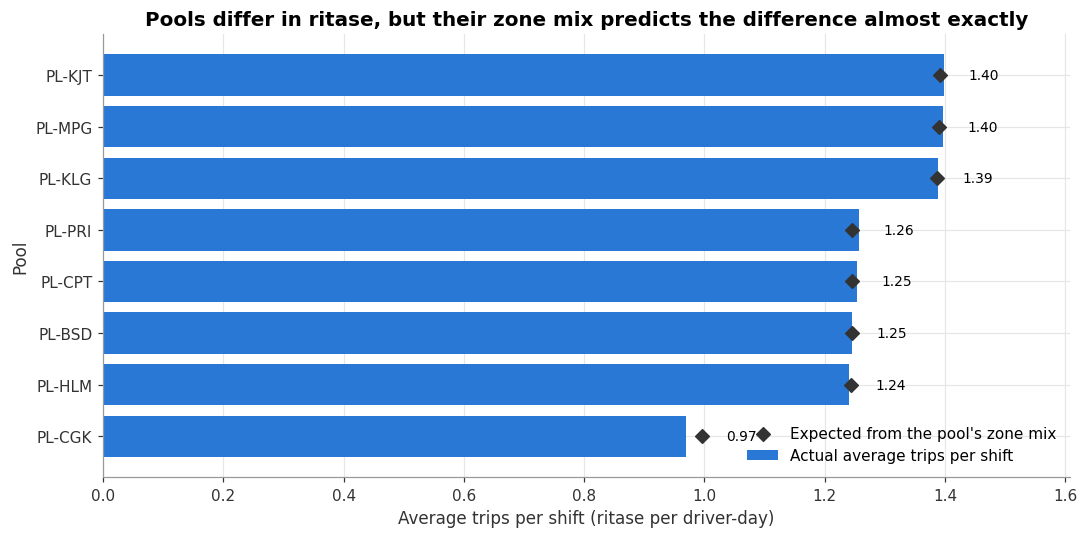

Saved: databasegpt\charts\v6_pool_ritase.png


In [170]:
pool_plot = pool_vs_expected.join(df_pools.set_index("pool_id")["pool_name"]).sort_values("actual_avg_trips")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(pool_plot.index, pool_plot["actual_avg_trips"], color=COLOR_MAIN, label="Actual average trips per shift")
ax.scatter(pool_plot["expected_from_zone_mix"], pool_plot.index, color=COLOR_TEXT, marker="D", s=40, zorder=3,
           label="Expected from the pool's zone mix")
for pool_id, row in pool_plot.iterrows():
    label_x = max(row["actual_avg_trips"], row["expected_from_zone_mix"]) + 0.04
    ax.text(label_x, pool_id, f"{row['actual_avg_trips']:.2f}", va="center", fontsize=9)
ax.set_xlabel("Average trips per shift (ritase per driver-day)")
ax.set_ylabel("Pool")
ax.set_title("Pools differ in ritase, but their zone mix predicts the difference almost exactly")
ax.legend(frameon=False, loc="lower right")
ax.set_xlim(0, pool_plot["actual_avg_trips"].max() * 1.15)
fig.tight_layout()
save_chart(fig, "v6_pool_ritase")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Ritase pool berkisar dari 0,97 (PL-CGK) sampai 1,40 (PL-KJT, PL-MPG) trip per shift. Berlian hitam (nilai harapan dari komposisi zona) jatuh dalam selisih 0,03 trip dari nilai nyata di setiap pool, dan di dalam satu zona semua pool hampir sama. Pool berbeda karena zona kerja pengemudinya berbeda (PL-CGK 55% shift Airport; pool dengan dominasi CBD 45% shift CBD), bukan karena sebagian pool lebih lemah. Ini asosiasi pada data observasional, bukan bukti sebab.
</div>

### <span style="color:#1D6FD8">3.5.3 Apakah Armada Berada di Tempat Permintaan?</span>

<p style="line-height:1.6;">
Porsi request setiap zona dibandingkan dengan porsi shift pengemudi di zona tersebut.
</p>

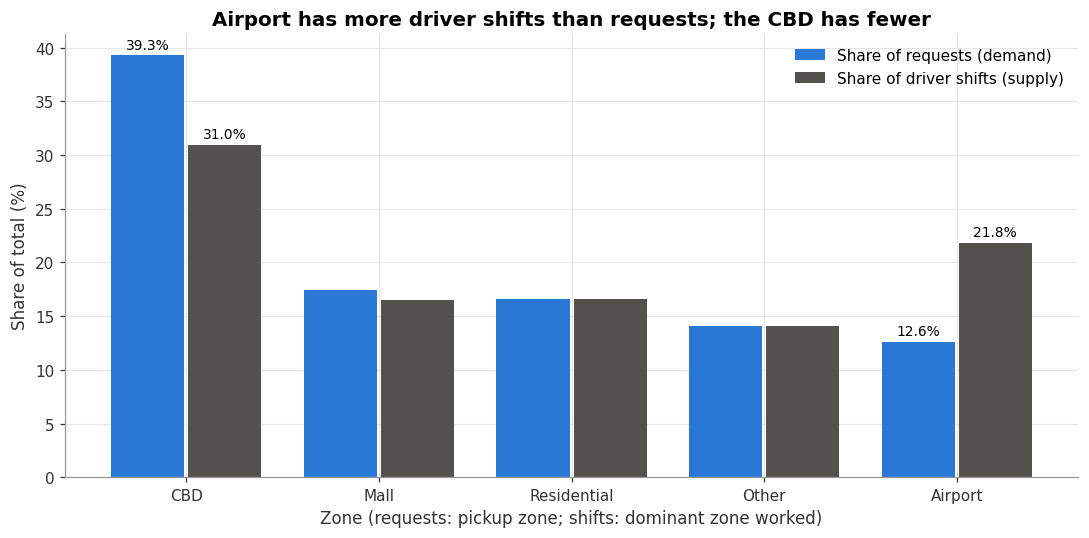

Saved: databasegpt\charts\v7_zone_supply_demand.png


In [171]:
balance = zone_balance.sort_values("request_share_pct", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
x_positions = np.arange(len(balance))
ax.bar(x_positions - 0.2, balance["request_share_pct"], width=0.38, color=COLOR_MAIN, label="Share of requests (demand)")
ax.bar(x_positions + 0.2, balance["shift_share_pct"], width=0.38, color="#52514e", label="Share of driver shifts (supply)")
ax.set_xticks(x_positions)
ax.set_xticklabels(balance.index)
ax.set_xlabel("Zone (requests: pickup zone; shifts: dominant zone worked)")
ax.set_ylabel("Share of total (%)")
ax.set_title("Airport has more driver shifts than requests; the CBD has fewer")
for i, zone in enumerate(balance.index):
    if zone in ("CBD", "Airport"):
        ax.text(i - 0.2, balance.loc[zone, "request_share_pct"] + 0.6, f"{balance.loc[zone, 'request_share_pct']:.1f}%", ha="center", fontsize=9)
        ax.text(i + 0.2, balance.loc[zone, "shift_share_pct"] + 0.6, f"{balance.loc[zone, 'shift_share_pct']:.1f}%", ha="center", fontsize=9)
ax.legend(frameon=False)
fig.tight_layout()
save_chart(fig, "v7_zone_supply_demand")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Airport menerima 12,6% request tetapi memiliki 21,8% shift (0,67 trip per shift, 51% shift tanpa trip). CBD menerima 39,3% request tetapi hanya 31,0% shift (1,70 trip per shift). Mall, Residential, dan Other relatif seimbang. Kapasitas pengemudi tampak lebih banyak di Airport daripada kebutuhannya (hipotesis). <strong>Batasan:</strong> zona shift adalah label zona dominan, dan request hanya mencakup App dan Call Center.
</div>

### <span style="color:#1D6FD8">3.5.4 Porsi Idle per Zona dan Waktu Mulai Shift</span>

<p style="line-height:1.6;">
Porsi idle dibandingkan antar zona dominan dan waktu mulai shift.
</p>

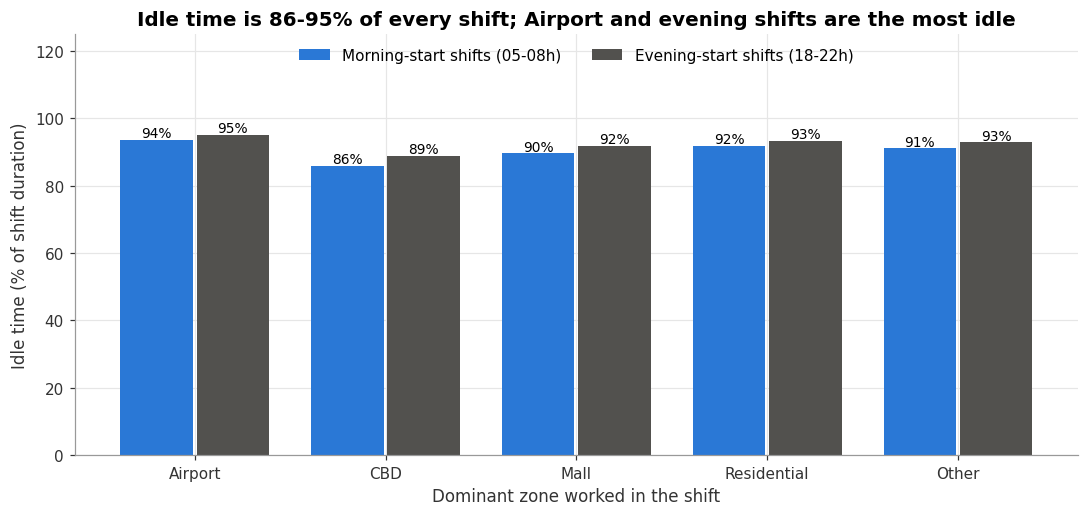

Saved: databasegpt\charts\v16_idle_share.png


In [172]:
idle_plot = idle_summary["avg_idle_share_pct"].unstack("start_group").loc[zones_in_order]
fig, ax = plt.subplots(figsize=(10, 4.8))
positions = np.arange(len(idle_plot))
ax.bar(positions - 0.2, idle_plot["Morning start"], width=0.38, color=COLOR_MAIN, label="Morning-start shifts (05-08h)")
ax.bar(positions + 0.2, idle_plot["Evening start"], width=0.38, color="#52514e", label="Evening-start shifts (18-22h)")
for i, zone in enumerate(idle_plot.index):
    ax.text(i - 0.2, idle_plot.loc[zone, "Morning start"] + 0.8, f"{idle_plot.loc[zone, 'Morning start']:.0f}%", ha="center", fontsize=9)
    ax.text(i + 0.2, idle_plot.loc[zone, "Evening start"] + 0.8, f"{idle_plot.loc[zone, 'Evening start']:.0f}%", ha="center", fontsize=9)
ax.set_xticks(positions)
ax.set_xticklabels(idle_plot.index)
ax.set_ylim(0, 125)
ax.set_xlabel("Dominant zone worked in the shift")
ax.set_ylabel("Idle time (% of shift duration)")
ax.set_title("Idle time is 86-95% of every shift; Airport and evening shifts are the most idle")
ax.legend(frameon=False, loc="upper center", ncol=2)
fig.tight_layout()
save_chart(fig, "v16_idle_share")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Idle mencapai 86–95% durasi shift di semua kelompok. Shift Airport paling idle (94–95%, 0,5–0,7 trip per shift), sedangkan shift CBD paling rendah (86–89%). Pada setiap zona, shift yang mulai sore 1–3 poin lebih idle. Ini bersifat observasional, dan label zona sebagian merupakan hasil pekerjaan.
</div>

### <span style="color:#1D6FD8">3.5.5 Seberapa Besar Variasi yang Dijelaskan Tiap Faktor?</span>

<p style="line-height:1.6;">
Faktor kategorik dinilai dengan eta-squared dan faktor kontinu dengan r-squared. Setiap faktor dihitung <strong>sendiri-sendiri</strong>.
</p>

,variance_explained_pct
Employment status,0.00
Tenure (days),0.00
Driver rating,0.00
Weekday,0.00
Vehicle type,0.00
Shift start (morning / evening),0.96
Pool (garage),1.45
Requests per driver in the zone (crowding),7.35
Dominant zone (place),9.72


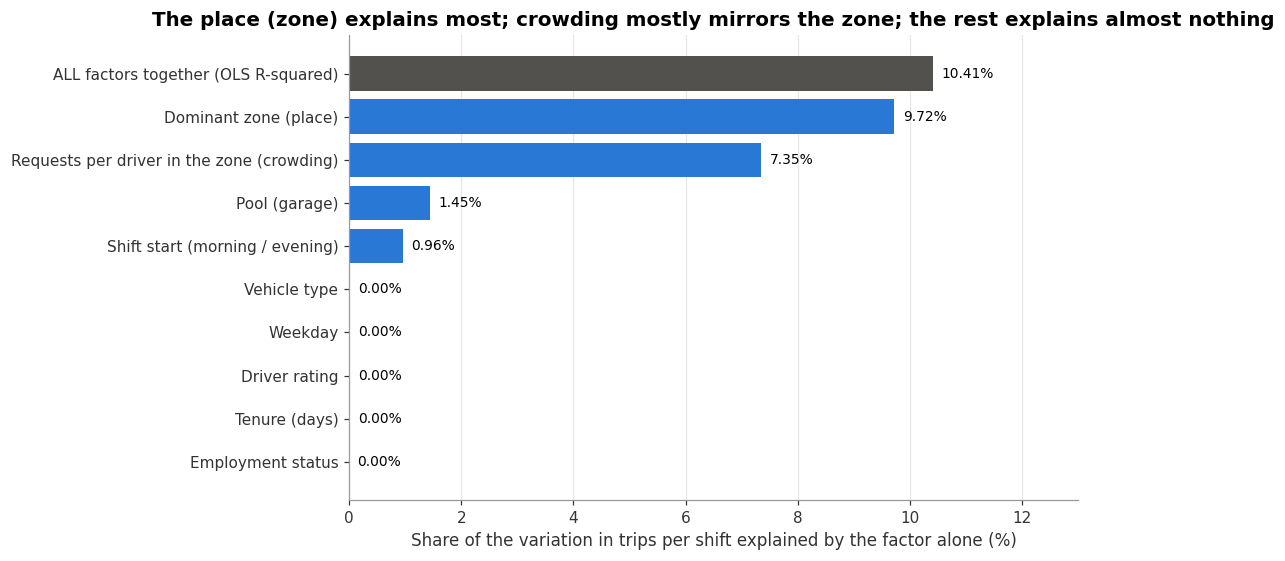

Saved: databasegpt\charts\v19_variance_explained.png


In [173]:
def eta_squared(column):
    groups = shifts_eda.groupby(column)["trip_count"]
    between = (groups.count() * (groups.mean() - shifts_eda["trip_count"].mean()) ** 2).sum()
    return between / ((shifts_eda["trip_count"] - shifts_eda["trip_count"].mean()) ** 2).sum() * 100

def r_squared(column):
    valid = shifts_eda[column].notna()
    return np.corrcoef(shifts_eda.loc[valid, column], shifts_eda.loc[valid, "trip_count"])[0, 1] ** 2 * 100

explained = pd.Series({
    "Dominant zone (place)": eta_squared("dominant_zone_worked"),
    "Pool (garage)": eta_squared("pool_id"),
    "Shift start (morning / evening)": eta_squared("start_group"),
    "Requests per driver in the zone (crowding)": r_squared("requests_per_driver_zone"),
    "Employment status": eta_squared("employment_status"),
    "Vehicle type": eta_squared("vehicle_type_assigned"),
    "Weekday": eta_squared("weekday"),
    "Driver rating": r_squared("driver_rating"),
    "Tenure (days)": r_squared("tenure_days"),
}).sort_values()
display(explained.round(3).to_frame("variance_explained_pct"))
if have_statsmodels:
    explained = pd.concat([explained, pd.Series({"ALL factors together (OLS R-squared)": model_with_pool.rsquared * 100})])

fig, ax = plt.subplots(figsize=(10, 5.2))
bar_colors = ["#52514e" if name.startswith("ALL") else (COLOR_MAIN if value >= 0.5 else COLOR_NEUTRAL)
              for name, value in explained.items()]
ax.barh(explained.index, explained.values, color=bar_colors)
for position, value in enumerate(explained.values):
    ax.text(value + 0.15, position, f"{value:.2f}%", va="center", fontsize=9)
ax.set_xlabel("Share of the variation in trips per shift explained by the factor alone (%)")
ax.set_title("The place (zone) explains most; crowding mostly mirrors the zone; the rest explains almost nothing")
ax.set_xlim(0, 13)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "v19_variance_explained")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Zona menjelaskan 9,7% variasi trip per shift, dan merupakan faktor tunggal terbesar. "Request per pengemudi di zona" menjelaskan 7,4%, tetapi sebagian besar hanya mengulang efek zona. Pool (1,4%) dan waktu mulai (1,0%) kecil, sedangkan status kerja, kendaraan, hari, rating, dan masa kerja sekitar 0%. Jika manajemen ingin mengubah idle time, tuasnya adalah <strong>di mana pengemudi bekerja</strong>, bukan siapa pengemudinya atau pool mana. Seluruh faktor bersama hanya menjelaskan 10,4%.
</div>

### <span style="color:#1D6FD8">3.5.6 Ramai Pengemudi? Trip per Kelompok Kepadatan</span>

<p style="line-height:1.6;">
Grafik kiri membandingkan trip per shift menurut kelompok kepadatan, dan grafik kanan menampilkan request per pengemudi per zona.
</p>

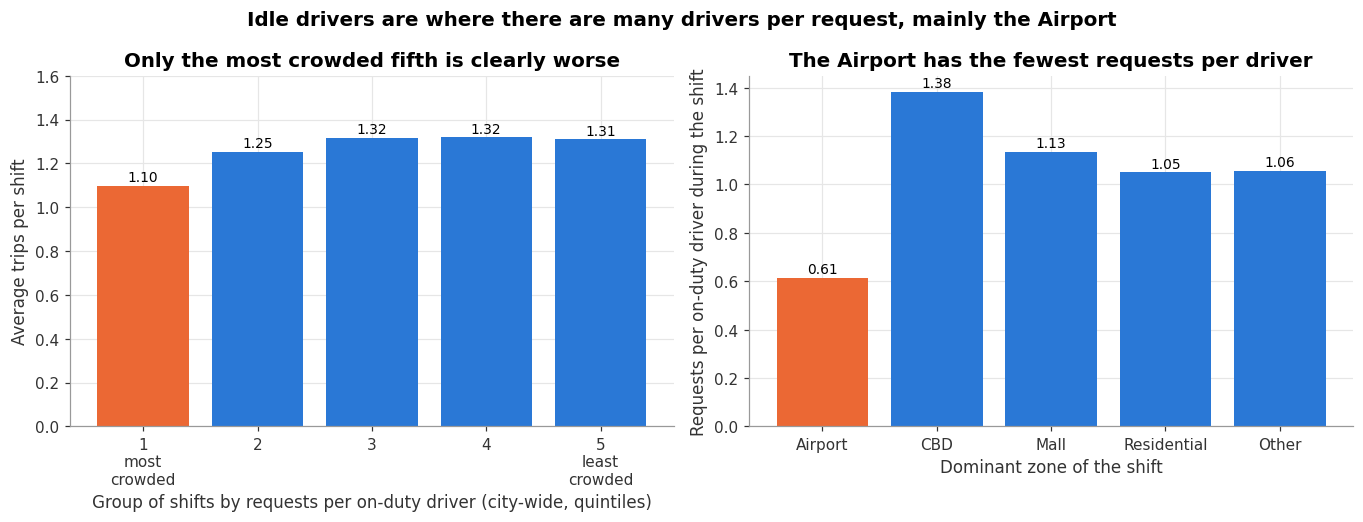

Saved: databasegpt\charts\v20_crowding.png


In [174]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12.5, 4.8))

group_labels = ["1\nmost\ncrowded", "2", "3", "4", "5\nleast\ncrowded"]
ax_left.bar(group_labels, crowding_table["avg_trips_per_shift"], color=[COLOR_PROBLEM, COLOR_MAIN, COLOR_MAIN, COLOR_MAIN, COLOR_MAIN])
for position, value in enumerate(crowding_table["avg_trips_per_shift"]):
    ax_left.text(position, value + 0.02, f"{value:.2f}", ha="center", fontsize=9)
ax_left.set_ylim(0, 1.6)
ax_left.set_xlabel("Group of shifts by requests per on-duty driver (city-wide, quintiles)")
ax_left.set_ylabel("Average trips per shift")
ax_left.set_title("Only the most crowded fifth is clearly worse")

zone_crowding = shifts_eda.groupby("dominant_zone_worked")["requests_per_driver_zone"].mean().loc[zones_in_order]
ax_right.bar(zone_crowding.index, zone_crowding.values, color=[COLOR_PROBLEM if z == "Airport" else COLOR_MAIN for z in zone_crowding.index])
for position, value in enumerate(zone_crowding.values):
    ax_right.text(position, value + 0.02, f"{value:.2f}", ha="center", fontsize=9)
ax_right.set_xlabel("Dominant zone of the shift")
ax_right.set_ylabel("Requests per on-duty driver during the shift")
ax_right.set_title("The Airport has the fewest requests per driver")
fig.suptitle("Idle drivers are where there are many drivers per request, mainly the Airport", fontweight="bold", fontsize=13)
fig.tight_layout()
save_chart(fig, "v20_crowding")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Hanya seperlima shift paling padat (0,73 request per pengemudi) yang jelas lebih buruk (1,10 trip vs 1,31–1,32). Airport memiliki request per pengemudi paling sedikit (0,61 vs 1,38 di CBD), sehingga Airport adalah tempat pengemudi "ramai" relatif terhadap permintaan. Karena itu, memindahkan sebagian kapasitas Airport ke CBD (hipotesis, perlu uji pilot) lebih menjanjikan daripada kebijakan di tingkat pengemudi.
</div>

### <span style="color:#1D6FD8">3.5.7 Waktu Pemakaian eVoucher</span>

<p style="line-height:1.6;">
Profil jam trip eVoucher dibandingkan dengan metode bayar lain. Aturan waktu tidak lazim adalah asumsi (lihat 2.6.2).
</p>

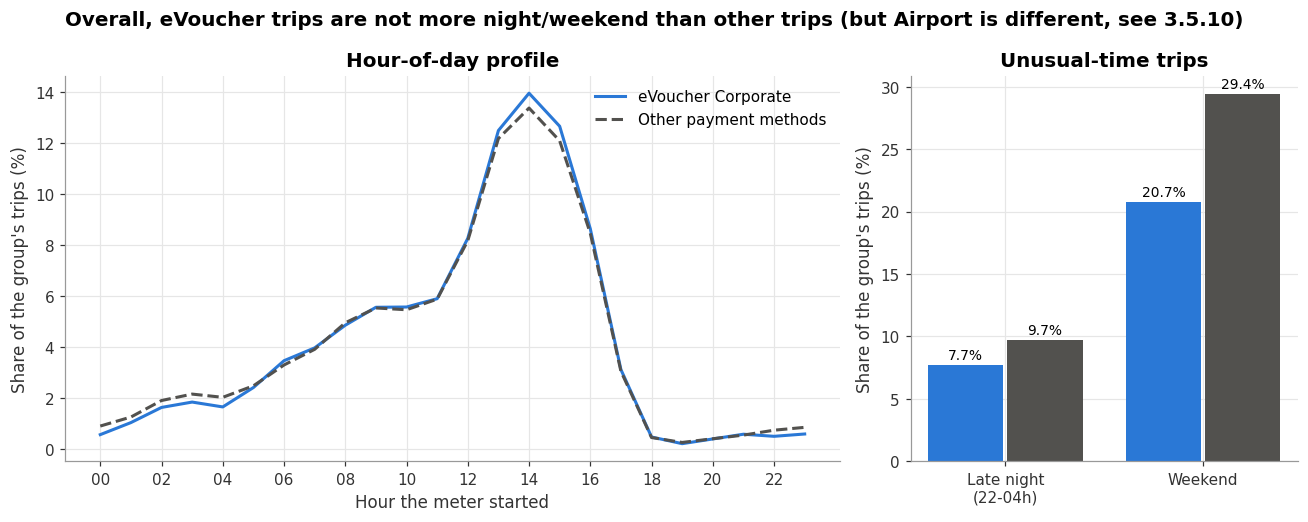

Saved: databasegpt\charts\v8_evoucher_timing.png


In [175]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [2, 1]})

ax_left.plot(evoucher_hour_share.index, evoucher_hour_share["eVoucher Corporate"], color=COLOR_MAIN, linewidth=2, label="eVoucher Corporate")
ax_left.plot(evoucher_hour_share.index, evoucher_hour_share["Other payment methods"], color="#52514e", linewidth=2, linestyle="--", label="Other payment methods")
ax_left.set_xticks(range(0, 24, 2))
ax_left.set_xticklabels(hour_labels[::2])
ax_left.set_xlabel("Hour the meter started")
ax_left.set_ylabel("Share of the group's trips (%)")
ax_left.set_title("Hour-of-day profile")
ax_left.legend(frameon=False)

categories = ["Late night\n(22-04h)", "Weekend"]
evoucher_values = [unusual.loc["eVoucher Corporate", "late_night_pct"], unusual.loc["eVoucher Corporate", "weekend_pct"]]
other_values = [unusual.loc["Other payment methods", "late_night_pct"], unusual.loc["Other payment methods", "weekend_pct"]]
positions = np.arange(2)
ax_right.bar(positions - 0.2, evoucher_values, width=0.38, color=COLOR_MAIN, label="eVoucher Corporate")
ax_right.bar(positions + 0.2, other_values, width=0.38, color="#52514e", label="Other payment methods")
for p, v in zip(positions - 0.2, evoucher_values):
    ax_right.text(p, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
for p, v in zip(positions + 0.2, other_values):
    ax_right.text(p, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax_right.set_xticks(positions)
ax_right.set_xticklabels(categories)
ax_right.set_ylabel("Share of the group's trips (%)")
ax_right.set_title("Unusual-time trips")
fig.suptitle("Overall, eVoucher trips are not more night/weekend than other trips (but Airport is different, see 3.5.10)", fontweight="bold", fontsize=13)
fig.tight_layout()
save_chart(fig, "v8_evoucher_timing")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Pada seluruh zona, kurva jam eVoucher mengikuti kurva metode bayar lain (puncak 13–15), dan eVoucher lebih jarang terjadi pada malam (7,7% vs 9,7%) dan akhir pekan (20,7% vs 29,4%). Angka gabungan ini menyesatkan karena Airport menunjukkan pola sebaliknya (3.5.10).
</div>

### <span style="color:#1D6FD8">3.5.8 Trip Korporat per Industri</span>

<p style="line-height:1.6;">
Trip ber-<code>company_id</code> dihitung per industri untuk melihat segmen korporat terbesar.
</p>

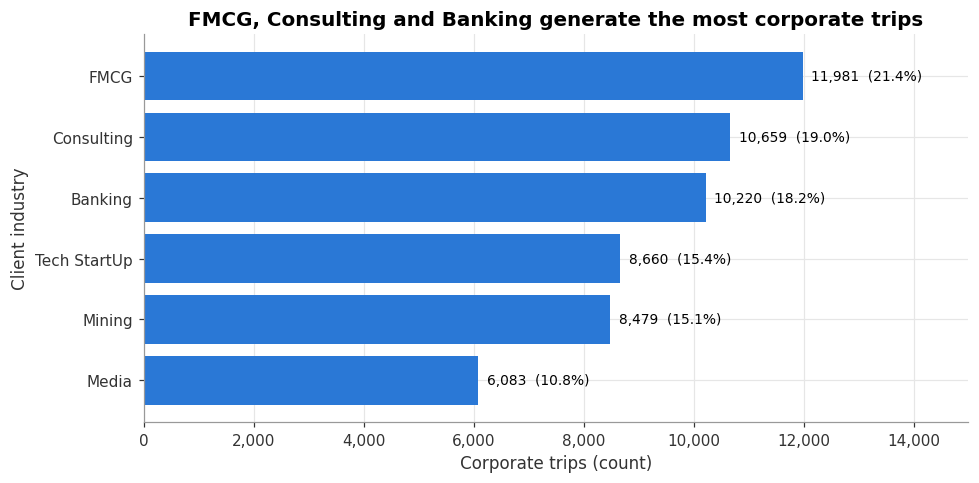

Saved: databasegpt\charts\v9_corporate_by_industry.png


In [176]:
industry_plot = by_industry.sort_values("trips")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(industry_plot.index, industry_plot["trips"], color=COLOR_MAIN)
for industry, row in industry_plot.iterrows():
    ax.text(row["trips"] + 150, industry, f"{row['trips']:,.0f}  ({row['trip_share_pct']:.1f}%)", va="center", fontsize=9)
ax.set_xlabel("Corporate trips (count)")
ax.set_ylabel("Client industry")
ax.set_title("FMCG, Consulting and Banking generate the most corporate trips")
ax.set_xlim(0, industry_plot["trips"].max() * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.tight_layout()
save_chart(fig, "v9_corporate_by_industry")

<div style="border-left:5px solid #6B7C8F; background:#F0F3F6; color:#1F2933; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Cara membaca angka.</strong> Persentase pada batang = trip industri dibagi seluruh 56.082 trip korporat (trip yang memiliki <code>company_id</code>). "Rata-rata trip per perusahaan" = trip industri dibagi jumlah perusahaan berbeda di industri itu (kolom <code>trips_per_company</code> pada tabel 2.6.1): terendah Mining 180,4 (8.479 trip dari 47 perusahaan) dan tertinggi Consulting 213,2 (10.659 trip dari 50 perusahaan), sehingga rentangnya 180–213.<br><br>"Top 10% perusahaan" = 29 perusahaan dengan trip terbanyak (10% dari 286 perusahaan, dibulatkan ke atas; perusahaan ke-29 memiliki 422 trip dan ke-30 memiliki 408 trip, jadi tidak ada seri di batas). Mereka menghasilkan 15.288 dari 56.082 trip = 27,3%; jika semua perusahaan sama, 29 perusahaan hanya akan menghasilkan sekitar 10,1%.
</div>

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> FMCG (11.981 trip, 21,4%), Consulting (19,0%), dan Banking (18,2%) adalah industri terbesar, sedangkan Media terkecil (10,9%). Karena rata-rata trip per perusahaan mirip antar industri, urutan ini terutama mencerminkan jumlah perusahaan per industri (57 FMCG vs 31 Media), bukan perusahaan yang lebih aktif. Di dalam industri, pemakaian cukup terkonsentrasi: 10% perusahaan teratas memakai sekitar 2,7 kali porsi "adil". Ini bersifat deskriptif; konsentrasi tinggi belum berarti pelanggaran.
</div>

### <span style="color:#1D6FD8">3.5.9 Ukuran B2B dan Lokasi Penjemputannya</span>

<p style="line-height:1.6;">
Porsi trip dan tarif B2B serta zona penjemputannya dibandingkan dengan Non-B2B.
</p>

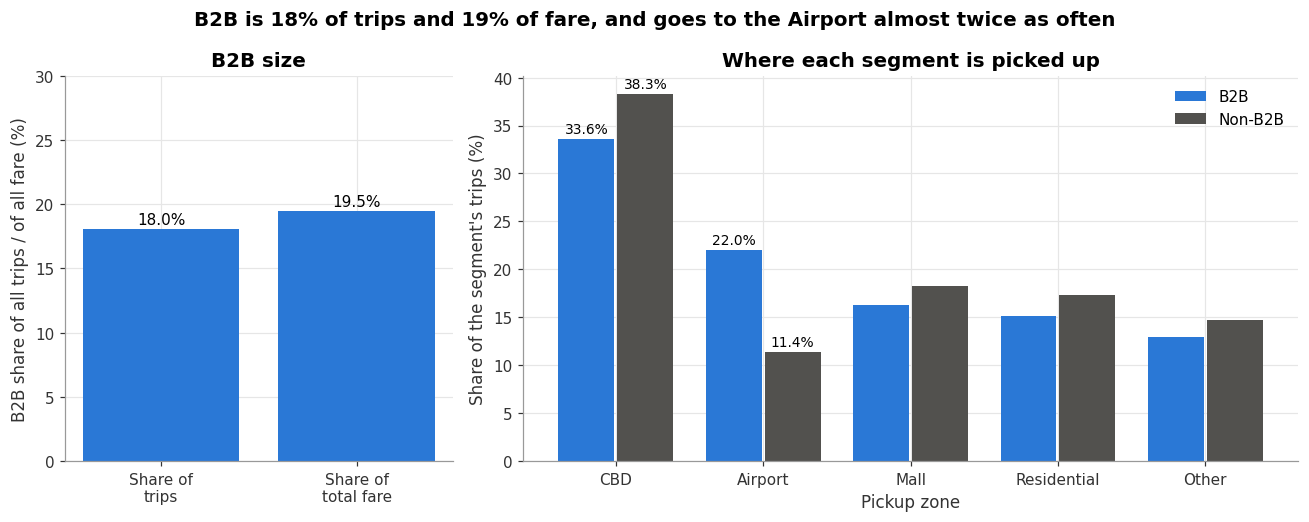

Saved: databasegpt\charts\v11_b2b_vs_non_b2b.png


In [177]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 2]})

b2b_values = [segment_summary.loc["B2B", "trip_share_pct"], segment_summary.loc["B2B", "fare_share_pct"]]
ax_left.bar(["Share of\ntrips", "Share of\ntotal fare"], b2b_values, color=COLOR_MAIN)
for i, v in enumerate(b2b_values):
    ax_left.text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=10)
ax_left.set_ylabel("B2B share of all trips / of all fare (%)")
ax_left.set_ylim(0, 30)
ax_left.set_title("B2B size")

zone_order = ["CBD", "Airport", "Mall", "Residential", "Other"]
positions = np.arange(len(zone_order))
ax_right.bar(positions - 0.2, segment_zone_mix.loc["B2B", zone_order], width=0.38, color=COLOR_MAIN, label="B2B")
ax_right.bar(positions + 0.2, segment_zone_mix.loc["Non-B2B", zone_order], width=0.38, color="#52514e", label="Non-B2B")
for i, zone in enumerate(zone_order):
    if zone in ("CBD", "Airport"):
        ax_right.text(i - 0.2, segment_zone_mix.loc["B2B", zone] + 0.6, f"{segment_zone_mix.loc['B2B', zone]:.1f}%", ha="center", fontsize=9)
        ax_right.text(i + 0.2, segment_zone_mix.loc["Non-B2B", zone] + 0.6, f"{segment_zone_mix.loc['Non-B2B', zone]:.1f}%", ha="center", fontsize=9)
ax_right.set_xticks(positions)
ax_right.set_xticklabels(zone_order)
ax_right.set_xlabel("Pickup zone")
ax_right.set_ylabel("Share of the segment's trips (%)")
ax_right.set_title("Where each segment is picked up")
ax_right.legend(frameon=False)
fig.suptitle("B2B is 18% of trips and 19% of fare, and goes to the Airport almost twice as often", fontweight="bold", fontsize=13)
fig.tight_layout()
save_chart(fig, "v11_b2b_vs_non_b2b")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> B2B menyumbang 18,0% trip dan 19,5% tarif; 22,0% trip B2B dijemput di Airport vs 11,4% pada Non-B2B. Permintaan korporat condong ke Airport, tempat kegagalan paling rendah (2%) dan pengemudi berlebih.
</div>

### <span style="color:#1D6FD8">3.5.10 Trip Waktu Tidak Lazim B2B vs Non-B2B per Zona</span>

<p style="line-height:1.6;">
Grafik kiri membandingkan porsi trip waktu tidak lazim per zona, dan grafik kanan menunjukkan profil hari pada trip Airport.
</p>

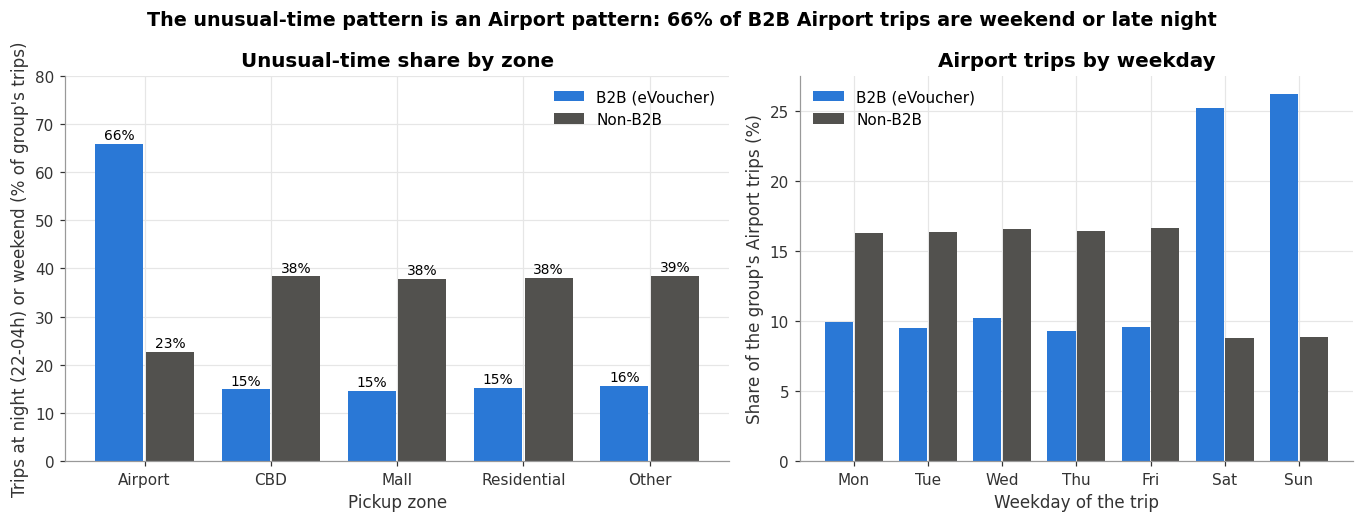

Saved: databasegpt\charts\v14_evoucher_airport_unusual_time.png


In [178]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})

zones_in_order = ["Airport", "CBD", "Mall", "Residential", "Other"]
unusual_matrix = zone_rule["unusual_time_pct"].unstack("customer_segment").loc[zones_in_order]
positions = np.arange(len(zones_in_order))
ax_left.bar(positions - 0.2, unusual_matrix["B2B"], width=0.38, color=COLOR_MAIN, label="B2B (eVoucher)")
ax_left.bar(positions + 0.2, unusual_matrix["Non-B2B"], width=0.38, color="#52514e", label="Non-B2B")
for i, zone in enumerate(zones_in_order):
    ax_left.text(i - 0.2, unusual_matrix.loc[zone, "B2B"] + 1, f"{unusual_matrix.loc[zone, 'B2B']:.0f}%", ha="center", fontsize=9)
    ax_left.text(i + 0.2, unusual_matrix.loc[zone, "Non-B2B"] + 1, f"{unusual_matrix.loc[zone, 'Non-B2B']:.0f}%", ha="center", fontsize=9)
ax_left.set_xticks(positions)
ax_left.set_xticklabels(zones_in_order)
ax_left.set_xlabel("Pickup zone")
ax_left.set_ylabel("Trips at night (22-04h) or weekend (% of group's trips)")
ax_left.set_ylim(0, 80)
ax_left.set_title("Unusual-time share by zone")
ax_left.legend(frameon=False, loc="upper right")

day_positions = np.arange(7)
ax_right.bar(day_positions - 0.2, airport_weekday["B2B"], width=0.38, color=COLOR_MAIN, label="B2B (eVoucher)")
ax_right.bar(day_positions + 0.2, airport_weekday["Non-B2B"], width=0.38, color="#52514e", label="Non-B2B")
ax_right.set_xticks(day_positions)
ax_right.set_xticklabels(weekday_names)
ax_right.set_xlabel("Weekday of the trip")
ax_right.set_ylabel("Share of the group's Airport trips (%)")
ax_right.set_title("Airport trips by weekday")
ax_right.legend(frameon=False, loc="upper left")
fig.suptitle("The unusual-time pattern is an Airport pattern: 66% of B2B Airport trips are weekend or late night", fontweight="bold", fontsize=12.5)
fig.tight_layout()
save_chart(fig, "v14_evoucher_airport_unusual_time")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> B2B lebih rendah daripada Non-B2B di empat zona (sekitar 15% vs 38%), tetapi jauh lebih tinggi di Airport (66% vs 23%). Trip B2B Airport 25–26% pada setiap hari akhir pekan, vs sekitar 9% untuk Non-B2B. Pertanyaan kontrol eVoucher pada dasarnya adalah pertanyaan tentang Airport pada akhir pekan dan malam, dan berlaku bagi hampir semua perusahaan.
</div>

### <span style="color:#1D6FD8">3.5.11 eVoucher di Luar Hari dan Jam Kerja: Perusahaan atau Tempat?</span>

<div style="border-left:5px solid #1D6FD8; background:#EAF2FC; color:#14263D; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Pertanyaan.</strong> Apakah pola eVoucher pada akhir pekan dan malam disebabkan oleh segelintir perusahaan, atau oleh tempat (Airport)?
</div>

<p style="line-height:1.6;">
Metrik: porsi trip eVoucher yang mulai pada Sabtu/Minggu atau pukul 22:00–04:59 (asumsi analisis; tidak ada aturan kontrak pada data). Bagian 3.5.11 membandingkan pola per hari dan sebaran porsi per perusahaan.
</p>

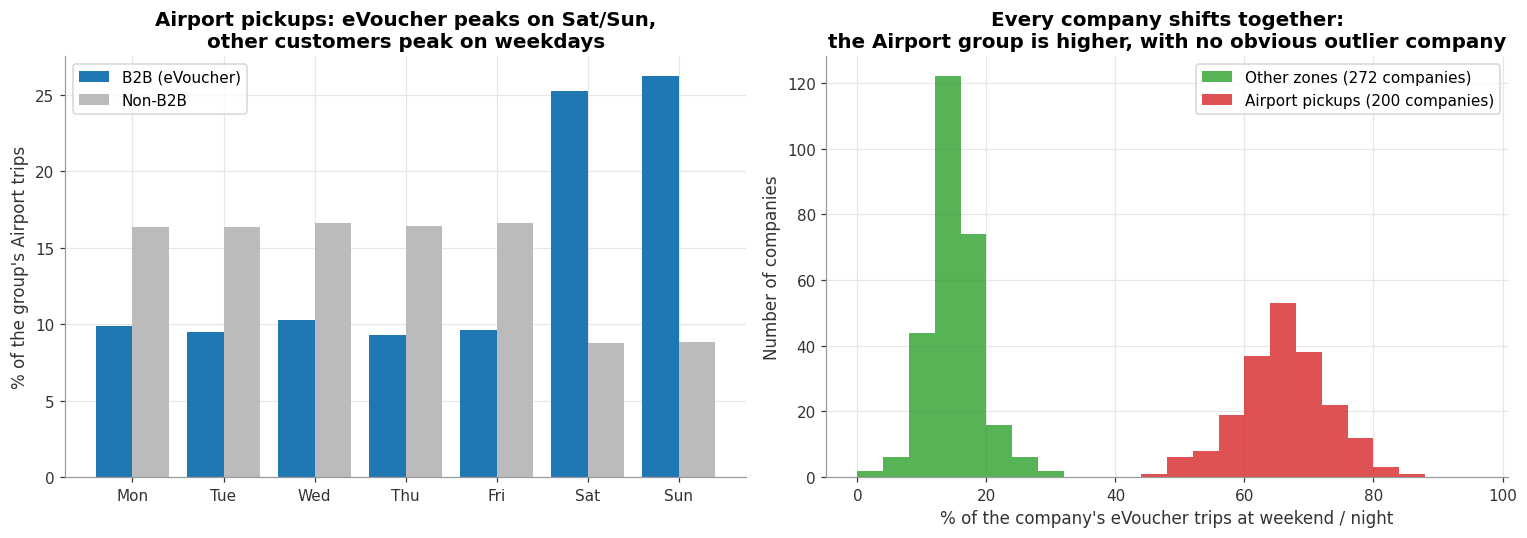

Airport: median company = 66.7%, range 47.8% - 84.6%
Other zones: median company = 15.0%, range 0.0% - 30.8%
Companies in the top 10% of Airport unusual share hold 8.3% of all B2B trips


In [179]:
# 3.5.11 - Is "unusual-time eVoucher use" a few-companies problem, or a place problem?
MIN_COMPANY_TRIPS = 20     # same cut-off as 2.6.5, so company percentages are not noise

b2b_trips = ev[ev["customer_segment"] == "B2B"].copy()
b2b_trips["group"] = np.where(b2b_trips["pickup_zone_type"] == "Airport", "Airport pickups", "Other zones")

# Left chart: share of trips per weekday (Airport only), reuse the table from 2.6.5
# Right chart: unusual-time share per company, separately for Airport and other zones
company_rate = b2b_trips.groupby(["group", "company_id"]).agg(
    trips=("trip_id", "size"),
    unusual_pct=("is_unusual_time", lambda s: s.mean() * 100),
).reset_index()
company_rate = company_rate[company_rate["trips"] >= MIN_COMPANY_TRIPS]

airport_rates = company_rate.loc[company_rate["group"] == "Airport pickups", "unusual_pct"]
other_rates = company_rate.loc[company_rate["group"] == "Other zones", "unusual_pct"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

x_pos = np.arange(7)
ax1.bar(x_pos - 0.2, airport_weekday["B2B"], width=0.4, label="B2B (eVoucher)", color="#1f77b4")
ax1.bar(x_pos + 0.2, airport_weekday["Non-B2B"], width=0.4, label="Non-B2B", color="#bbbbbb")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(airport_weekday.index)
ax1.set_ylabel("% of the group's Airport trips")
ax1.set_title("Airport pickups: eVoucher peaks on Sat/Sun,\nother customers peak on weekdays")
ax1.legend()

bins = np.arange(0, 100, 4)
ax2.hist(other_rates, bins=bins, alpha=0.8, color="#2ca02c", label=f"Other zones ({len(other_rates)} companies)")
ax2.hist(airport_rates, bins=bins, alpha=0.8, color="#d62728", label=f"Airport pickups ({len(airport_rates)} companies)")
ax2.set_xlabel("% of the company's eVoucher trips at weekend / night")
ax2.set_ylabel("Number of companies")
ax2.set_title("Every company shifts together:\nthe Airport group is higher, with no obvious outlier company")
ax2.legend()

plt.tight_layout()
plt.savefig(output_dir / "charts" / "v21_evoucher_unusual_time.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Airport: median company = {airport_rates.median():.1f}%, range {airport_rates.min():.1f}% - {airport_rates.max():.1f}%")
print(f"Other zones: median company = {other_rates.median():.1f}%, range {other_rates.min():.1f}% - {other_rates.max():.1f}%")
print(f"Companies in the top 10% of Airport unusual share hold {b2b_trips[b2b_trips['company_id'].isin(company_rate.loc[(company_rate['group']=='Airport pickups') & (company_rate['unusual_pct'] >= airport_rates.quantile(0.9)), 'company_id'])].shape[0] / len(b2b_trips) * 100:.1f}% of all B2B trips")

<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Pola ini bukan milik segelintir perusahaan. Semua perusahaan dengan cukup banyak trip Airport berada pada rentang sempit (48–85%, median 67%), polanya sama di semua industri (65–67%), dan perusahaan yang sama terlihat normal di luar Airport (median 15%). Polanya mengikuti <strong>tempat</strong>, bukan perusahaan. Mencari satu perusahaan yang "melanggar" bernilai rendah, dan "pelanggaran" tidak bisa dibuktikan karena tidak ada aturan kontrak tentang hari dan jam yang diizinkan. Penjelasan yang mungkin (hipotesis): perjalanan bisnis mengikuti jadwal penerbangan, pemakaian pribadi, atau voucher tanpa batasan waktu.
</div>

## <span style="color:#1D6FD8">3.6 Temuan Visual Akhir</span>

<p style="line-height:1.6;">
Bagian ini merangkum temuan terpenting yang didukung grafik, memastikan angka pada grafik cocok dengan tabel, menjawab pertanyaan tentang penyebab idle time, dan menutup dengan kesimpulan serta rekomendasi.
</p>

### <span style="color:#1D6FD8">3.6.1 Ringkasan Temuan Visual</span>

| Pertanyaan brief | Dijawab di | Hasil |
|---|---|---|
| Variasi ritase antar pool dan penyebabnya | 3.5.1, 3.5.2, 2.5.4, 2.5.5 | 0,97–1,40 trip per driver-day; komposisi zona menjelaskan hampir seluruhnya (hipotesis: alokasi zona) |
| Waktu atau lokasi dengan request gagal terbanyak | 3.4.1, 3.4.2, 3.4.3 | CBD pukul 07–08 dan 17–18: 36–42% gagal vs 6,7% keseluruhan |
| Apakah kekurangan pengemudi penyebabnya? | 3.4.4, 3.5.3 | Belum terbukti; pasokan tidak menjelaskan 07–08; Airport memiliki shift lebih banyak dari permintaan, CBD lebih sedikit |
| Dampak kualitas data meter | 3.3.1, 2.3.1 | Setelah eksklusi, 0,38% trip dengan jarak tidak andal tetap menaikkan rata-rata jarak sekitar 18% |
| Pola eVoucher | 3.5.7, 3.5.8, 2.6.2, 2.6.5, 3.5.10 | Secara keseluruhan tidak lebih sering pada waktu tidak lazim, tetapi trip eVoucher Airport 66% pada akhir pekan/malam vs 23% pada trip Airport lain |
| Keputusan bagi manajer operasional dan tim Finance | Rekomendasi | Operasional: atur shift CBD jam sibuk, pindahkan sebagian shift Airport, tetapkan baseline ritase. Finance: verifikasi eVoucher Airport akhir pekan/malam, konfirmasi aturan zona |

### <span style="color:#1D6FD8">3.6.2 Pengecekan Grafik dan Angka</span>

<p style="line-height:1.6;">
Sebelum grafik dan angka dipakai, satu sel memeriksa bahwa angka yang digambar sama dengan tabel di Bagian 2 dan bahwa total tabel eksplorasi konsisten (jumlah baris, persentase berjumlah 100%, jumlah minggu, dan sebagainya).
</p>

In [180]:
final_checks = {
    "3.4.1: hourly requests add up to all requests": int(by_hour["requests"].sum()) == len(req),
    "3.4.1/3.4.2: heatmap has 5 zones x 24 hours": heat.shape == (5, 24),
    "3.4.3: zone-period cells use all requests": int(zone_by_period_n.to_numpy().sum()) == len(req),
    "3.4.4: 24 hourly supply values": len(supply_demand) == 24,
    "3.5.1: trip-count shares add to 100%": abs(trip_count_share.sum() - 100) < 1e-9,
    "3.5.2: 8 pools plotted": len(pool_plot) == df_pools["pool_id"].nunique() == 8,
    "3.5.3: request and shift shares each add to 100%": abs(balance["request_share_pct"].sum() - 100) < 1e-9 and abs(balance["shift_share_pct"].sum() - 100) < 1e-9,
    "3.5.7: hour profiles each add to 100%": np.allclose(evoucher_hour_share.sum(), 100),
    "3.5.8: industry trips = corporate trips": int(by_industry["trips"].sum()) == int(trips_eda["is_corporate"].sum()),
    "3.3.1: five zones plotted": len(quality_zone) == 5,
    "3.5.9: segments add up to all trips": int(segment_summary["trips"].sum()) == len(trips_eda),
    "3.5.9: segment fare shares add to 100%": abs(segment_summary["fare_share_pct"].sum() - 100) < 1e-9,
    "3.2.2: payment mix adds to 100% per channel": np.allclose(channel_payment_mix.sum(axis=1), 100),
    "3.2.1: hour profiles add to 100% per channel": np.allclose(channel_hour_share.sum(), 100),
    "channels add up to all trips": int(channel_summary["trips"].sum()) == len(trips_eda),
    "Street Hail trips = trips with no request": int((trips_eda["booking_channel"] == "Street Hail").sum()) == int((~trips_eda["trip_id"].isin(req["matched_trip_id"])).sum()),
    "2.6.5: zone x segment table covers all trips": int(zone_rule["trips"].sum()) == len(ev),
    "2.6.5: Airport B2B + Non-B2B = all Airport trips": len(airport_b2b) + len(airport_non_b2b) == int((ev["pickup_zone_type"] == "Airport").sum()),
    "2.5.7: 12 full weeks": len(weekly) == 12,
    "2.5.7: weekly requests = requests in those weeks": int(weekly["requests"].sum()) == int(req["week_start"].isin(full_weeks).sum()),
    "2.5.8: idle-by-trips table covers all shifts": int(idle_by_trips["size"].sum()) == len(shifts_eda),
    "2.4.7: peak requests = requests in failure-peak hours": int(impact["peak_requests"].sum()) == int((req["period"] == "Failure-peak hours").sum()),
    "2.5.9: shifts table unchanged in size": len(shifts_eda) == len(df_shifts_clean) == 252524,
    "2.5.10: busy minutes match trip minutes (within clipping)": busy_minutes.sum() <= ((trips_eda["dropoff_time"] - trips_eda["booking_time"]).dt.total_seconds() / 60).sum() + 1e-6,
    "2.5.10: utilisation between 0 and 100 in every hour": bool(utilisation_by_hour["utilisation_pct"].between(0, 100).all()),
    "2.7.1: crowding measure has no empty values": bool(shifts_eda["requests_per_driver_zone"].notna().all()),
    "2.7.1: five crowding groups, each about 20% of shifts": bool(crowding_table["shifts"].between(0.19 * n_shifts, 0.21 * n_shifts).all()),
    "2.7.1: every test has a p-value between 0 and 1": bool(tests_table["p_value"].between(0, 1).all()),
    "3.5.5: explained variance values between 0 and 100": bool(explained.between(0, 100).all()),
}
display(pd.Series(final_checks).to_frame("passed"))
assert all(final_checks.values()), "A final check failed - do not use these numbers or charts"
print(f"All {len(final_checks)} final checks passed.")


,passed
3.4.1: hourly requests add up to all requests,True
3.4.1/3.4.2: heatmap has 5 zones x 24 hours,True
3.4.3: zone-period cells use all requests,True
3.4.4: 24 hourly supply values,True
3.5.1: trip-count shares add to 100%,True
3.5.2: 8 pools plotted,True
3.5.3: request and shift shares each add to 100%,True
3.5.7: hour profiles each add to 100%,True
3.5.8: industry trips = corporate trips,True
3.3.1: five zones plotted,True


All 29 final checks passed.


### <span style="color:#1D6FD8">3.6.3 Jawaban: Mengapa Pengemudi Idle di Sebuah Pool?</span>

<p style="line-height:1.6;">
Alasan diurutkan menurut kekuatan bukti. <strong>Teramati</strong> berarti ditunjukkan oleh data; <strong>hipotesis</strong> berarti kemungkinan penyebab yang belum terbukti.
</p>

| # | Alasan | Bukti | Uji atau metode | Status |
|---|---|---|---|---|
| 1 | **Struktural: jam shift jauh lebih banyak daripada permintaan** | Utilisasi 9,4%; tiap trip memakai sekitar 39 menit idle; 1,26 trip per shift (2.5.8, 2.5.10, 3.4.6) | Ukuran deskriptif (menit sibuk / menit bertugas), regresi linear idle vs trip | Teramati |
| 2 | **Tempat: Airport penuh pengemudi** | Zona adalah faktor terkuat (9,7% variasi); shift CBD 2,49 kali trip shift Airport; shift tanpa trip 19% (CBD) vs 51% (Airport); Airport 0,61 request per pengemudi vs 1,38 di CBD (2.7.1, 3.5.5, 3.5.6) | Kruskal-Wallis, chi-square, regresi Poisson dan logistik, indeks kepadatan | Teramati (label zona sebagian hasil pekerjaan) |
| 3 | **Waktu: shift mulai sore** | Trip 1,25 kali lebih sedikit daripada shift mulai pagi; rank-biserial r = 0,14 (2.7.1) | Mann-Whitney U, regresi Poisson | Teramati; sebab (permintaan sore tipis) = hipotesis |
| 4 | **Pagi: masalah pencocokan, bukan kekurangan** | Pukul 07–08 sekitar 5% pengemudi sibuk tetapi 22% request gagal (3.4.6) | Perbandingan deskriptif per jam | Teramati; sebab (posisi atau awal shift) = hipotesis |
| 5 | **Pool BUKAN penyebab mandiri** | Setelah zona dikendalikan, F-test pool p = 0,62; rate ratio 1,00–1,01 (2.7.3) | F-test model bertingkat, regresi Poisson | Teramati |
| 6 | **Bukan penyebab:** status kerja, tipe kendaraan, hari, rating, masa kerja, tren mingguan | Semuanya diabaikan atau tidak signifikan (2.7.4) | Mann-Whitney U, Kruskal-Wallis, Spearman, uji kemiringan | Teramati |
| 7 | **Tidak terjelaskan (sekitar 90%)** | R-squared 10,4% (2.7.3) | Regresi OLS | Butuh data yang tidak tersedia (GPS pengemudi, waktu antre Airport, log dispatch) |

<div style="border-left:5px solid #2E9E5B; background:#E8F6EE; color:#12301F; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Apakah idle terjadi karena tempatnya ramai?.</strong> Sebagian ya, dalam arti yang tepat: <strong>Airport memiliki banyak pengemudi untuk sedikit request</strong>, dan pengemudi di sana lebih idle. Di dalam satu zona, tambahan permintaan per pengemudi hampir tidak menambah trip setelah sekitar 1 request per pengemudi, sehingga "ramai" adalah cerita <strong>antar zona</strong>, bukan di dalam zona.
</div>

### <span style="color:#1D6FD8">3.6.4 Daftar Uji Statistik dan Metode yang Digunakan</span>

**Uji hipotesis** (setiap uji memiliki H0 yang menyatakan "tidak ada efek")

| Uji | Dipakai di | H0 | Hasil |
|---|---|---|---|
| Kruskal-Wallis H | 2.7.1 (zona, pool, kendaraan, hari) | semua kelompok berdistribusi sama | zona dan pool menolak H0; kendaraan dan hari tidak |
| Mann-Whitney U | 2.7.1 (mulai pagi vs sore, Tetap vs Mitra) | kedua kelompok berdistribusi sama | waktu mulai menolak H0 (efek kecil); status kerja tidak |
| Chi-square independensi (+ Cramér's V) | 2.4.4, 2.7.1 (zona × shift tanpa trip) | kedua variabel independen | keduanya menolak H0 |
| Uji z dua proporsi (+ CI 95%, Cohen's h) | 2.7.1 (CBD jam puncak vs lainnya; B2B Airport vs Non-B2B) | kedua proporsi sama | keduanya menolak H0, efek besar |
| Korelasi Spearman | 2.7.1 (kepadatan, rating, masa kerja vs trip) | rho = 0 | kepadatan signifikan tetapi diabaikan; rating dan masa kerja tidak menolak H0 |
| F-test model bertingkat (OLS) | 2.7.3 (pool setelah mengendalikan zona dll.) | semua koefisien pool = 0 | tidak menolak H0 (p = 0,62) |
| Uji t kemiringan regresi + Spearman | 2.5.7 / 2.7.1 (tren mingguan ritase) | kemiringan = 0 | tidak menolak H0 (tidak ada tren) |
| Skor z (penyaringan proporsi) | 2.6.2 (porsi waktu tidak lazim per perusahaan) | porsi perusahaan sama dengan keseluruhan | tidak ada perusahaan di atas z = 3 |

**Model dan effect size:** regresi OLS (R-squared, partial eta-squared); regresi Poisson dengan robust standard error (rate ratio); regresi logistik (odds ratio); epsilon-squared, eta-squared, r-squared, rank-biserial, Cramér's V, Cohen's h, odds ratio; CI 95%; koreksi **Bonferroni** untuk 15 uji.

**Metode analisis:** ambang batas dari celah data (batas jarak); cek kardinalitas join; pembersihan dengan flag; rasio dengan pembilang dan penyebut yang jelas; group-by dan pivot; standarisasi langsung menurut komposisi zona (2.5.5); penghitungan pengemudi bertugas per jam (2.5.1, 2.5.10); utilisasi (2.5.10); indeks kepadatan (2.7.2); ukuran kontrafaktual kegagalan berlebih (2.4.7).

**Variabel yang dikeluarkan dari pengujian:** lihat 2.5.9.

# <span style="color:#1D6FD8">Bagian 4: Export Data dan Validasi</span>

<p style="line-height:1.6;">
Bagian ini menyimpan dataset <strong>sebelum dan sesudah pembersihan</strong> supaya hasil analisis dapat diaudit dan dipakai ulang tanpa menjalankan seluruh notebook dari awal. Kedua versi perlu disimpan: tabel bersih saja tidak membuktikan apa yang diubah, sedangkan tabel mentah saja tidak cukup untuk mengulang analisis.
</p>

| Tahap | Arti | Lokasi |
|---|---|---|
| **RAW** | Enam tabel persis seperti dimuat dari MySQL, sebelum pembersihan apa pun | <code>databasegpt/raw/</code> |
| **CLEANED** | Tabel final yang dipakai di Bagian 2–3 (kolom asli ditambah kolom <code>*_clean</code> dan <code>flag_*</code>) | <code>databasegpt/cleaned/</code> |
| **EXCEPTION** | Record yang ditandai atau dikeluarkan beserta alasannya, dan daftar tinjauan eVoucher (ditulis di 1.8.1 dan 2.6.7) | <code>databasegpt/</code> |
| **REPORT** | Laporan kualitas dan relasi dari 1.9.3, ditambah manifest export dari bagian ini | <code>databasegpt/</code> |

<p style="line-height:1.6;">
<strong>Mengapa jumlah baris bisa berbeda.</strong> Hanya tabel trip yang berkurang barisnya, yaitu 7.091 trip dengan jarak negatif atau delay booking-ke-meter negatif (1.8.1). Tabel lain tidak dihapus barisnya; record bermasalah hanya diberi kolom flag.
</p>

<p style="line-height:1.6;">
<strong>Cara validasi.</strong> (1) Fingerprint tabel mentah saat dimuat (1.2.2) dan fingerprint tabel bersih di akhir Bagian 1 (1.9.3) dihitung ulang untuk membuktikan tidak ada perubahan. (2) Setiap file dibaca kembali dan dibandingkan dengan DataFrame asalnya: jumlah baris, kolom, nama kolom, sel kosong, dan isi.
</p>

<p style="line-height:1.6;">
<strong>Keterbatasan.</strong> CSV menyimpan semua nilai sebagai teks, sehingga kolom datetime dan boolean harus di-parse ulang saat file dibaca. File RAW adalah hasil export dari database, bukan salinan byte asli dari sumbernya.
</p>

## <span style="color:#1D6FD8">4.1 Export Data Mentah (RAW)</span>

<p style="line-height:1.6;">
Keenam tabel diexport dari DataFrame <code>*_raw</code> yang dimuat di 1.2.1. Fingerprint dicek lebih dulu untuk membuktikan tabel ini belum pernah diubah sejak dimuat.
</p>

In [ ]:
# 4.1 RAW exports: the six tables exactly as loaded from MySQL, before any cleaning.
raw_dir = output_dir / "raw"
cleaned_dir = output_dir / "cleaned"
for folder in [raw_dir, cleaned_dir]:
    folder.mkdir(parents=True, exist_ok=True)

raw_exports = {
    "bb_corporate_clients": df_clients_raw,
    "bb_trips": df_trips_raw,
    "bb_driver_shifts": df_shifts_raw,
    "bb_drivers": df_drivers_raw,
    "bb_pools": df_pools_raw,
    "bb_service_requests": df_requests_raw,
}
# Proof that the raw DataFrames are still the untouched source data (fingerprints taken in 1.2.2).
for name, df in raw_exports.items():
    assert int(pd.util.hash_pandas_object(df, index=True).sum()) == raw_fingerprints[name], f"{name}: raw data changed after loading"
print("Raw fingerprints match the values taken right after loading: the raw tables were never modified.")

export_log = []          # one entry per exported file, used for the manifest and the validation below

def export_csv(df, folder, file_name, dataset, stage, note):
    """Write one DataFrame to CSV (UTF-8 with BOM so Excel shows it correctly, no index) and log it."""
    path = folder / file_name
    df.to_csv(path, index=False, encoding="utf-8-sig")
    export_log.append({"dataset": dataset, "stage": stage, "file": path.as_posix(), "frame": df, "note": note})
    print(f"{stage:<9} {path.as_posix():<52} {len(df):>9,} rows x {df.shape[1]:>2} columns")

for name, df in raw_exports.items():
    export_csv(df, raw_dir, f"{name}_raw.csv", name, "RAW", "As loaded from MySQL; no cleaning applied")


## <span style="color:#1D6FD8">4.2 Export Data Bersih (CLEANED) dan Daftar Exception</span>

<p style="line-height:1.6;">
Tabel bersih diambil dari <code>tables_final</code> (1.8.2), yaitu tabel yang dipakai di Bagian 2–3. Fingerprint dicek untuk membuktikan analisis tidak mengubahnya. File exception sudah ditulis di 1.8.1 dan 2.6.7; di sini file-file itu hanya didaftarkan agar ikut divalidasi.
</p>

In [ ]:
# 4.2 CLEANED exports: the final tables from 1.8.2 (tables_final), the same objects used in Parts 2-3.
cleaned_names = {
    "bb_corporate_clients": "clients", "bb_trips": "trips", "bb_driver_shifts": "shifts",
    "bb_drivers": "drivers", "bb_pools": "pools", "bb_service_requests": "requests",
}

# Proof that the analysis did not change the cleaned tables after Bagian 1 (fingerprints taken in 1.9.3).
for name, key in cleaned_names.items():
    assert int(pd.util.hash_pandas_object(tables_final[key], index=True).sum()) == cleaned_fingerprints[key], f"{name}: cleaned table changed after Bagian 1"
print("Cleaned fingerprints match the end of Bagian 1: Parts 2-3 did not modify the exported tables.")

def cleaned_note(name, key):
    """Describe what differs from the raw table, computed from the data instead of typed by hand."""
    raw_rows, clean_rows = len(raw_exports[name]), len(tables_final[key])
    added = [c for c in tables_final[key].columns if c not in raw_exports[name].columns]
    rows_text = f"{raw_rows - clean_rows:,} rows excluded" if raw_rows != clean_rows else "No rows removed"
    return f"{rows_text}; {len(added)} columns added ({', '.join(added[:4])}{', ...' if len(added) > 4 else ''})" if added else f"{rows_text}; no columns added"

for name, key in cleaned_names.items():
    export_csv(tables_final[key], cleaned_dir, f"{name}_cleaned.csv", name, "CLEANED", cleaned_note(name, key))

# EXCEPTION files were written earlier (1.8.1 and 2.6.7). They are registered here so they are validated too.
for name, frame, file_name, note in [
    ("bb_trips", trip_exceptions, "trip_data_quality_exceptions.csv", "Every trip with a problem flag; column treatment = excluded or kept"),
    ("bb_driver_shifts", shift_exceptions, "shift_data_quality_exceptions.csv", "Shifts with an invalid duration or idle-time flag; all kept"),
    ("evoucher", review_candidates[review_columns], "evoucher_review_candidates.csv", "Review priority list (2-3 independent signals); NOT a fraud list"),
]:
    export_log.append({"dataset": name, "stage": "EXCEPTION", "file": (output_dir / file_name).as_posix(), "frame": frame, "note": note})
print("Exception files registered:", ", ".join(entry["file"] for entry in export_log if entry["stage"] == "EXCEPTION"))


## <span style="color:#1D6FD8">4.3 Validasi Export</span>

<p style="line-height:1.6;">
Setiap file dibaca kembali lalu dibandingkan dengan DataFrame asalnya. Yang dicek: file ada, jumlah baris dan kolom sama, nama kolom sama, jumlah sel kosong sama, dan isi sama setelah melalui konversi CSV yang sama.
</p>

In [ ]:
# 4.3 Validate every exported file by reading it back.
from io import StringIO

validation_rows = []
for entry in export_log:
    path, frame = Path(entry["file"]), entry["frame"]
    checks = {"file exists": path.exists()}
    back = pd.read_csv(path, encoding="utf-8-sig", low_memory=False)
    # Expected content: the same DataFrame passed through the same CSV conversion in memory.
    expected = pd.read_csv(StringIO(frame.to_csv(index=False)), low_memory=False)
    checks["same rows"] = len(back) == len(frame)
    checks["same columns"] = back.shape[1] == frame.shape[1]
    checks["same column names"] = list(back.columns) == [str(c) for c in frame.columns]
    checks["same empty cells"] = back.isna().sum().equals(expected.isna().sum())
    try:
        pd.testing.assert_frame_equal(back, expected, check_dtype=False)
        checks["same values"] = True
    except AssertionError:
        checks["same values"] = False
    validation_rows.append({**{k: entry[k] for k in ["stage", "dataset", "file"]}, **checks,
                            "missing in memory": int(frame.isna().sum().sum()), "empty cells in file": int(back.isna().sum().sum())})

validation = pd.DataFrame(validation_rows)
check_columns = ["file exists", "same rows", "same columns", "same column names", "same empty cells", "same values"]
validation["status"] = np.where(validation[check_columns].all(axis=1), "VALIDATED", "FAILED")
display(validation.drop(columns=["file"]))
assert (validation["status"] == "VALIDATED").all(), "Some exports failed validation - see the table above"

# The raw tables must still be untouched after exporting.
for name, df in raw_exports.items():
    assert int(pd.util.hash_pandas_object(df, index=True).sum()) == raw_fingerprints[name]
# Raw exports must not contain columns created by cleaning.
for entry in export_log:
    if entry["stage"] == "RAW":
        added = [c for c in entry["frame"].columns if str(c).startswith("flag_") or str(c).endswith("_clean")]
        assert not added, f"{entry['dataset']} raw export contains cleaning columns: {added}"
print(f"All {len(validation)} exported datasets validated; raw tables unchanged after export; raw files contain no cleaning columns.")


## <span style="color:#1D6FD8">4.4 Manifest dan Perbandingan Baris Mentah vs Bersih</span>

<p style="line-height:1.6;">
Manifest mencatat setiap file yang benar-benar dibuat, lengkap dengan jumlah baris, kolom, catatan, dan status validasinya. Perbandingan baris menjelaskan dari mana selisih jumlah baris berasal.
</p>

In [ ]:
# 4.4 Manifest of every file actually created, and the raw-vs-cleaned row comparison.
manifest = pd.DataFrame([{
    "dataset": entry["dataset"], "stage": entry["stage"], "file": entry["file"],
    "rows": len(entry["frame"]), "columns": entry["frame"].shape[1],
    "column_names": "; ".join(map(str, entry["frame"].columns)), "note": entry["note"],
} for entry in export_log])
manifest = manifest.merge(validation[["file", "status"]], on="file", how="left")

# Reports written in 1.9.3. Each one is read back to prove the file is usable.
report_files = [
    "data_quality_report.csv", "relationship_validation_report.csv", "relationship_validation_report_final.csv",
    "missing_values_structural_vs_real.csv", "cleaning_flag_summary.csv",
]
report_rows = []
for report_name in report_files:
    report_path = output_dir / report_name
    report = pd.read_csv(report_path, encoding="utf-8-sig")
    report_rows.append({"dataset": report_path.stem, "stage": "REPORT", "file": report_path.as_posix(),
                        "rows": len(report), "columns": report.shape[1],
                        "column_names": "; ".join(report.columns), "note": "Report written in 1.9.3",
                        "status": "READ BACK"})
manifest = pd.concat([manifest, pd.DataFrame(report_rows)], ignore_index=True)
display(manifest.drop(columns=["column_names"]))

def flagged_rows(df):
    """Rows with at least one flag_* column set to True."""
    flag_cols = [c for c in df.columns if str(c).startswith("flag_")]
    if not flag_cols:
        return 0
    return int(df[flag_cols].fillna(False).astype(bool).any(axis=1).sum())

comparison_rows = []
for name, key in cleaned_names.items():
    raw_rows, clean_rows = len(raw_exports[name]), len(tables_final[key])
    comparison_rows.append({
        "dataset": name, "raw rows": raw_rows, "cleaned rows": clean_rows, "excluded rows": raw_rows - clean_rows,
        "flagged rows kept in cleaned": flagged_rows(tables_final[key]),
        "reason for difference": "Exclusion rule 1.8.1 (negative distance or negative booking delay)" if raw_rows != clean_rows else "No rows removed",
    })
row_comparison = pd.DataFrame(comparison_rows).set_index("dataset")
display(row_comparison)
assert row_comparison.loc["bb_trips", "excluded rows"] == int(df_trips["exclude_trip"].sum())
assert (row_comparison.drop(index="bb_trips")["excluded rows"] == 0).all()

# Exception files: treatment, rules and overlaps.
print("trip_data_quality_exceptions.csv - records by treatment:")
display(trip_exceptions["treatment"].value_counts().to_frame("records"))
print("Records per rule (one record can match several rules):")
display(trip_exceptions[trip_flag_columns].sum().rename(index=trip_issue_flags).to_frame("records"))
print(f"Records with more than one rule: {int((trip_exceptions[trip_flag_columns].sum(axis=1) > 1).sum()):,}")
print(f"shift_data_quality_exceptions.csv: {len(shift_exceptions):,} shifts, all kept in the cleaned table")
in_trip_exceptions = review_candidates["trip_id"].isin(trip_exceptions["trip_id"]).sum()
print(f"evoucher_review_candidates.csv: {len(review_candidates):,} trips; {int(in_trip_exceptions):,} also appear in the trip exception file "
      f"(only review-flag trips can, because excluded trips are not in the cleaned table)")
assert not review_candidates["trip_id"].isin(trip_exceptions.loc[trip_exceptions["exclude_trip"], "trip_id"]).any()

manifest.to_csv(output_dir / "export_manifest.csv", index=False, encoding="utf-8-sig")
row_comparison.reset_index().to_csv(output_dir / "raw_vs_cleaned_row_counts.csv", index=False, encoding="utf-8-sig")
assert pd.read_csv(output_dir / "export_manifest.csv", encoding="utf-8-sig").shape[0] == len(manifest)
print(f"Saved: {(output_dir / 'export_manifest.csv').as_posix()} and {(output_dir / 'raw_vs_cleaned_row_counts.csv').as_posix()} (read back OK)")


<div style="border-left:5px solid #12A5A5; background:#E6F6F6; color:#123333; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Interpretasi.</strong> Semua file yang diexport (6 RAW, 6 CLEANED, dan 3 EXCEPTION) dibaca kembali dan dicocokkan dengan DataFrame asalnya, sedangkan 5 laporan dari 1.9.3 dibaca ulang untuk memastikan file-nya terbaca. Fingerprint membuktikan tabel mentah tidak berubah sejak dimuat dan tabel bersih tidak berubah sejak akhir Bagian 1.<br><br>Hanya tabel trip yang berkurang barisnya, tepat 7.091 trip yang dikeluarkan. Tabel lain tetap utuh; record bermasalah tetap ada dan hanya diberi kolom flag. Jumlah record per aturan, jumlah shift pada file exception, dan jumlah kandidat tinjauan eVoucher ditampilkan pada output sel 4.4.<br><br><strong>Catatan.</strong> File exception adalah daftar tinjauan, bukan daftar kesalahan atau kecurangan. CSV menyimpan nilai sebagai teks, sehingga datetime dan boolean perlu di-parse ulang saat file dibaca.
</div>

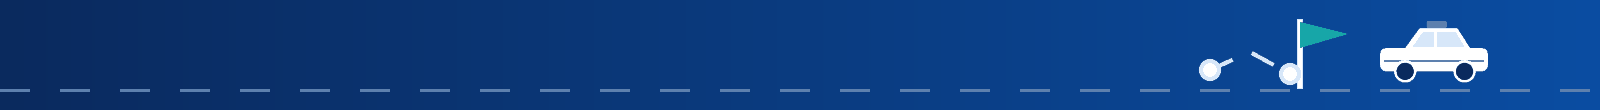

# <span style="color:#1D6FD8">Penutup</span>

## <span style="color:#1D6FD8">Kesimpulan</span>

<p style="line-height:1.6;">
Berdasarkan seluruh analisis atas data Oktober–Desember 2023, diperoleh enam kesimpulan berikut:
</p>

1. **Request gagal terpusat di CBD pada jam sibuk.** CBD pukul 07–08 dan 17–18 gagal 36,6%, dibanding 5,5% pada jam lain di zona yang sama (3.4.1–3.4.3, 2.4.4). Kegagalan berlebih ini sekitar 6.350 request di CBD (2.4.7).
2. **Pengemudi idle terutama karena pasokan jam shift jauh melebihi permintaan.** Rata-rata hanya 1,26 trip per shift, 30,6% shift tanpa trip, dan utilisasi 9,4% (2.5.8, 2.5.10). Tempat (Airport penuh pengemudi) adalah faktor terkuat, sedangkan pool bukan penyebab mandiri (2.7.1, 3.5.5).
3. **Ritase rendah tetapi tidak menurun.** Tidak ada tren dalam 12 minggu (3.4.5). Penurunan yang disebut dalam brief tidak dapat dikonfirmasi dengan data tiga bulan.
4. **Trip eVoucher Airport sangat condong ke akhir pekan dan malam** (65,9% vs 22,6%), seragam di 200 perusahaan dan semua industri (2.6.5, 3.5.10, 3.5.11). Ini pola yang perlu diverifikasi, bukan bukti penyalahgunaan.
5. **Kualitas data meter memengaruhi angka.** Setelah 7.091 trip (2,2%) dengan jarak atau delay negatif dikeluarkan, 0,38% trip dengan jarak tidak andal tetap menggelembungkan rata-rata jarak sekitar 18% (2.3.1, 3.3.1).
6. **Screening eVoucher menurut zona penjemputan tidak menunjukkan kecurangan.** 66,4% trip eVoucher (74,2% tarif) dijemput di luar CBD, hampir sama dengan pelanggan lain (61,7%), seragam di semua perusahaan, dan tarifnya tidak lebih sering tinggi (2.6.6–2.6.8). Aturan CBD-only belum dikonfirmasi dan zona tujuan tidak tersedia, sehingga ini merupakan potensi pelanggaran kebijakan yang bersyarat, bukan kecurangan.

## <span style="color:#1D6FD8">Rekomendasi dan Implikasi Bisnis</span>

<p style="line-height:1.6;">
Rekomendasi diurutkan menurut dampak, kekuatan bukti, dan kelayakan. Baseline KPI berasal dari data ini, sedangkan nilai target ditetapkan oleh manajemen.
</p>

| # | Rekomendasi | Bukti | KPI (baseline) | Prioritas |
|---|---|---|---|---|
| 1 | **Uji pilot pengaturan clock-in/clock-out** agar lebih banyak pengemudi berada di CBD pada pukul 07–08 dan 17–18, dengan kelompok kontrol sebagai pembanding | CBD gagal 36,6% pada jam tersebut; hanya 351 shift aktif pada 17:00–17:59 vs sekitar 2.300 pada 08:00–12:59 (3.4.3, 3.4.4, 2.4.7) | Kegagalan CBD pada 4 jam (36,6%); pengemudi bertugas per jam; porsi "tidak ada pengemudi" (69,6% dari kegagalan) | **Tinggi** |
| 2 | **Verifikasi trip eVoucher Airport akhir pekan/malam**: minta kebijakan perjalanan klien, wajibkan alasan trip, tinjau sampel acak; konfirmasi aturan zona CBD ke Finance dan minta data zona tujuan | 65,9% vs 22,6%; 8.134 trip, 24,3% tarif B2B (2.6.5, 3.5.10, 3.5.11); 66,4% trip eVoucher dijemput di luar CBD, hampir sama dengan pelanggan lain (2.6.6) | Porsi trip eVoucher Airport akhir pekan/malam (65,9%); % trip dengan tujuan terdokumentasi | **Tinggi** |
| 3 | **Uji pilot pemindahan sebagian shift Airport (terutama PL-CGK) ke CBD** pada jam sibuk | Airport 21,8% shift tetapi 12,6% request; 51% shift Airport tanpa trip (3.5.3, 3.5.6) | Porsi shift tanpa trip (30,6%; Airport 51,1%); trip per shift (1,26) | Sedang |
| 4 | **Tetapkan baseline dan target ritase** serta pantau mingguan per pool dan zona; jangan memakai flag 6 trip sebagai KPI | 1,26 trip per driver-day; hanya 0,35% shift mencapai 6 trip (3.5.1, 3.4.5) | Trip per driver-day (1,26); porsi idle (90%) | Sedang |
| 5 | **Evaluasi pool berdasarkan ritase yang disesuaikan zona** | Komposisi zona menjelaskan perbedaan pool dalam selisih 0,03 trip (3.5.2) | Selisih trip per shift terhadap nilai harapan per pool | Sedang |
| 6 | **Tinjau jumlah shift sore terhadap permintaan sore** | 1,01 vs 1,31 trip per shift (2.5.2, 3.4.4) | Trip per shift sore (1,01) | Rendah–Sedang |
| 7 | **Tambah validasi data meter** saat input dan wajibkan referensi booking untuk pemakaian eVoucher | 7.091 trip (2,2%) dengan jarak/delay negatif dikeluarkan; 1.185 trip (0,38%) jarak tidak andal; 5.220 trip Street Hail dibayar eVoucher tanpa booking (2.3.1, 2.6.4) | Persentase rekaman meter tidak valid (2,2% trip dikeluarkan; 0,38% jarak tidak andal) | Rendah–Sedang |

<div style="border-left:5px solid #6B7C8F; background:#F0F3F6; color:#1F2933; padding:10px 16px; border-radius:4px; line-height:1.6;">
<strong>Pembagian peran.</strong> Manajer operasional armada menangani rekomendasi 1, 3, 4, 5, dan 6. Tim Finance korporat menangani rekomendasi 2 dan 7. Semua rekomendasi merupakan usulan uji coba atau verifikasi, bukan kesimpulan sebab-akibat.
</div>

## <span style="color:#1D6FD8">Keterbatasan Analisis</span>

- **Cakupan waktu:** hanya tiga bulan data (Oktober–Desember 2023).
- **Jenis bukti:** semua hasil adalah asosiasi, bukan sebab-akibat.
- **Kelengkapan data:** request gagal tidak membawa informasi pengemudi atau perusahaan, dan permintaan Street Hail tidak terlihat.
- **Asumsi analisis:** definisi "waktu tidak lazim" dan batas jarak 500 km / 1 km merupakan asumsi dari analisis ini, dan target ritase tidak didefinisikan dalam brief.
- **Daya jelaskan:** sekitar 90% variasi trip per shift tidak terjelaskan oleh data yang tersedia.